# PROJET compagnon IMMOBILIER

# RENDU n°1

## 1.Exploration et data visualisation des données

### A.Contexte et description du projet

Titre du projet : Compagnon immobilier
Membres du groupe : Céline NAUDET, Théophyle CHEVET, Christian BAYILI, Gabrielle RICHERT
Mentor du projet : Romain LESIEUR

Objectif : une première partie du projet consistera à prédire l'évollution du prix du logement en fonction du territoire surlequel il se trouve, à partir de données historiques de ventes et de différents facteurs socio-économiques.
La deuxième partie du projet sera axée autour de la création d'un chatbot qui permettra aux acheteurs ainsi qu''aux investisseurs immobiliers pour explorer les annonces correspondantes à leur recherche et ainsi les comparer.

Aucun membre du groupe ne travaille déjà dans le domaine immobilier ou n'a de connaissances spécifiques sur le sujet.

Cadrage du projet :
- France métropolitaine, hors DOM-TOM et Alsace-Moselle (absente du DVF+) pour la prédiction de l'évolution des biens,
- ventes et location d'un seul logement, maison ou appartement avec dépendances éventuelles. La VEFA (vente en l'état futur d'achèvement) est également exclue car il s'agit d'un autre marché immobilier,
- ventes de 2014 à 2025, période qui couvre deux régimes de taux de crédit immobilier.

### B. Données à disposition

Les jeux de données mis à disposition au début du projet :
- Demande de Valeurs Foncières (DVF), disponible librement sur le site du gouvernement français. Ces données sont produites par la Direction Générale des Finances Publiques (GDFiP) à partir de sources fiscales. Cerema a developpé le modèle DVF+, qui restructure les données en plusieurs tables, ajoute des variables calculées ou agrégées pour faciliter l'exploitation des données. Le DVF+ est en opensource et sera utilisé au profit du DVF dans le projet.
- Annonces de vente et location dans le département du Haut-Rhin (68), deux fichiers CSV issus d'un GitHub de particulier (Klopstock-dviz), aucun fichier de métadonnées associé, aucune information concernant le mode de collecte, la date de mise à jour. Les données semblent être issues d'annonces immobilières ou de scraping.

Le DVF+ est particulièrement volumineux (11.6 Go avec 16 252 022 lignes et 64 colonnes), contrairement aux deux fichiers d'annonces de ventes et de locations qui ont respectivement 27 737 lignes, 58 colonnes et 11 702 lignes, 51 colonnes.
Le fichier DVF+, au vu de son poids, devra être échantillonné pour permettre son exploitation.

### C. Pertinence des données

#### C.1. Variable cible.
**L'évolution des prix médians au m2 par commune et par année.** Sélection uniquement des biens seuls (pas de lots type achat ou vente d'un promoteur immobilier).

#### C.2. Particularités du jeu de données à disposition.
La taille du DVF+ ainsi que l'absence du département 68 pour lequel nous possédons un échantillon des annonces de ventes et de location nous incite à utiliser les données de manière distinctes : le DVF+ servira principalement pour la première partie du projet sur la prédiction des prix de ventes des biens, tandis que les annonces nous serviront de base d'entrainement du chatbot pour la 2e partie du projet.

#### C.3. Analyse exhaustive des jeux de données à disposition

##### C.3.1. Analyse du DVF+

**Source**
Les données DVF (Demandes de valeurs foncières) sont produites par la Direction générale des Finances publiques (DGFiP) à partir de sources fiscales, notamment FIDJI et MAJIC.
Le modèle DVF+, développé par le Cerema, restructure ces données en plusieurs tables et ajoute des variables calculées ou agrégées pour faciliter leur exploitation. La table mutation correspond aux mutations immobilières.
Les données DVF sont d'origine administrative, et non issues d'annonces immobilières ou de scraping.


*Documentation* : guide Cerema De DVF à DV3F, dont la dernière mise à jour de fond est indiquée comme juin 2021. Le PDF a été généré le 10 octobre 2026. Une documentation technique en ligne existe et peut évoluer indépendamment de ce PDF.


*Impact projet :*
DVF+ constitue une source pertinente pour étudier les transactions immobilières effectivement enregistrées. Elle ne décrit cependant pas l'intégralité du marché : certaines mutations sont exclues, et les caractéristiques des biens restent limitées, notamment si nous utilisons uniquement la table mutation.


*Points de vigiliances :*
Le document distingue trois modèles : DVF brut, DVF+ et DV3F. Nous travaillons sur DVF+ et non sur DV3F qui n'est pas en opensource.

**Taille du fichier et échantillonnage pour une première analyse**
Le dataset analysé est un **échantillon de 100 000 observations et 64 colonnes**, occupant environ **48,2 Mo en mémoire**.

Il a été constitué à partir de 97 fichiers départementaux DVF+, couvrant la période 2014–2025. L'échantillonnage a été réalisé de manière **aléatoire stratifiée proportionnelle par département**, avec une graine fixée à 42 pour assurer la reproductibilité du tirage.

Les 64 colonnes comprennent 63 variables issues de la table `mutation` de DVF+ et une variable ajoutée lors de l'échantillonnage, `departement_source`, permettant de conserver l'origine départementale des observations.

Les variables présentent différents types (`int64`, `float64`, `str`, `bool`) et certaines comportent des valeurs manquantes.

**Structure d'une ligne**
une ligne correspond à une mutation immobilière, c'est-à-dire une opération de transfert de propriété pouvant concerner un ou plusieurs biens.

Contrairement aux fichiers DVF bruts, où une mutation peut apparaître sur plusieurs lignes, la table mutation de DVF+ présente un enregistrement par mutation.

La vérification de idmutation confirme la présence de 100 000 identifiants uniques pour 100 000 observations. Chaque ligne représente donc une mutation distincte dans l'échantillon.

**Limite :** les 100 000 observations ne constituent pas la base nationale exhaustive. La stratification proportionnelle vise à préserver le poids relatif des départements dans les fichiers sources, mais ne garantit pas à elle seule la représentativité de toutes les caractéristiques des transactions.
Par ailleurs, les informations agrégées à l'échelle d'une mutation ne permettent pas nécessairement de caractériser individuellement chaque bien vendu.
Toutefois, les données DVF brutes présentent également une limite importante : bien qu'elles permettent d'identifier les différents locaux et parcelles concernés par une mutation, la valeur foncière est renseignée pour l'ensemble de la transaction et non pour chaque bien. Ainsi, lorsqu'une mutation comprend plusieurs biens, il est possible de les dénombrer et de décrire certaines de leurs caractéristiques, mais pas d'attribuer un prix de vente individuel à chacun.

Le choix entre DVF brut et la table mutation de DVF+ implique donc un compromis entre le niveau de détail des biens et la facilité d'analyse des transactions.

**Comprendre les variables**

Tableau exhaustif des variables en annexe 1.

L'audit descriptif révèle une forte hétérogénéité des mutations immobilières. La base regroupe des ventes résidentielles individuelles, des terrains, des locaux professionnels et des transactions complexes pouvant porter sur plusieurs dizaines, voire centaines de biens.

Ces situations extrêmes influencent fortement les distributions et rendent les statistiques globales peu pertinentes pour évaluer la qualité des données destinées au futur modèle.

*Décision :* procéder dès maintenant à un sous-échantillonnage métier, afin de poursuivre l'audit sur une population plus homogène et cohérente avec les utilisateurs ciblés : particuliers et professionnels d'agence immobilière.


*Le périmètre envisagé est le suivant :*

Mutations de nature Vente ou Vente en l'état futur d'achèvement.

Typologie UNE MAISON ou UN APPARTEMENT.

Transaction portant sur un seul logement, avec possibilité de dépendances associées.

Les VEFA dépourvues de descriptif exploitable ne seront pas intégrées à ce premier périmètre.


La base initiale de 100 000 mutations sera conservée intacte. Le sous-échantillon constituera une nouvelle population d'étude, sur laquelle seront poursuivies les vérifications de qualité : valeurs manquantes, cohérence des surfaces, valeurs foncières atypiques et distributions géographiques et temporelles.

La constitution éventuelle d'un nouvel échantillon de 200 000 mutations sera réévaluée après mesure du nombre d'observations conservées.

Cette démarche permet de distinguer les caractéristiques normales de transactions complexes des véritables problèmes de qualité des données dans le périmètre métier retenu.

**Analyse de la qualité des données :** distribution des valeurs extrêmes en annexe n°2.

Dans l'ensemble, les données paraissent de bonne qualité. Aucun doublon n'a été détecté et les variables sont globalement bien renseignées. La valeur foncière ne présente que 0,03 % de valeurs manquantes et les coordonnées géographiques 0,35 %.

Trois colonnes sont entièrement vides (`codservch`, `refdoc`, `l_artcgi`) et ne présentent donc aucun intérêt pour l'analyse. La variable `l_idparmut` comporte 46,43 % de valeurs manquantes, mais celles-ci correspondent exactement aux mutations pour lesquelles `nbparmut = 0`. Il ne s'agit donc pas d'une incohérence entre ces deux variables.

Les distributions numériques sont assez asymétriques, en particulier pour les valeurs foncières et les surfaces de terrain.

*Concernant les valeurs foncières*, 99 % des mutations renseignées ne dépassent pas 1,08 million d'euros, mais le maximum atteint 27,06 millions d'euros. Quatre mutations présentent également une valeur foncière nulle. Ces observations sont atypiques et mériteront d'être examinées pour déterminer s'il s'agit de transactions particulières ou d'anomalies.

*Les surfaces bâties présentent une distribution plus homogène.* Aucune valeur nulle n'a été relevée, 95 % des surfaces ne dépassent pas 158 m² et 99 % restent inférieures ou égales à 222 m². La surface maximale est de 675 m², ce qui reste plausible pour une grande propriété. Aucune anomalie manifeste ne ressort de cette première analyse.

*Pour les surfaces de terrain, l'analyse par type de logement a permis de clarifier les résultats.* Initialement, 46,44 % des mutations présentaient une surface nulle, ce qui pouvait laisser penser à un problème de qualité. En distinguant les maisons des appartements, on constate que :

- 98,03 % des appartements ont une surface de terrain nulle, ce qui est cohérent avec les ventes en copropriété, où le terrain n'est généralement pas individualisé.
- Seulement 4,47 % des maisons ont une surface de terrain nulle. Pour les autres, la surface médiane est de 634 m² et le 95e percentile atteint 5 930 m².

Les valeurs nulles de `sterr` s'expliquent donc principalement par la typologie des biens et ne constituent pas un problème généralisé de qualité. En revanche, certaines superficies restent très importantes, avec un maximum dépassant 110 hectares pour les maisons. Ces transactions devront être examinées pour vérifier leur cohérence avec le périmètre du projet.

À ce stade, rien ne justifie un nettoyage systématique des données. Les valeurs extrêmes ne sont pas nécessairement des erreurs : elles peuvent correspondre à des transactions rares mais réelles.

**Pour la suite**, les vérifications seront concentrées sur ces quelques situations particulières. Les éventuelles décisions de traitement devront être justifiées par leur cohérence métier et leur pertinence pour le modèle de prédiction, plutôt que par leur seul caractère statistiquement atypique.

**Conclusion de l'audit du DVF+**

*Périmètre.* Le périmètre résidentiel est retenu : ventes d'une seule maison ou d'un seul appartement, avec d'éventuelles dépendances, portant sur une seule commune. Les VEFA sont exclues, car elles relèvent du marché du neuf (TVA incluse dans le prix, frais d'acquisition réduits).

*Couverture temporelle et géographique.* La période 2014-2025 est conservée ; l'année 2025 est réservée au test du modèle. La couverture géographique est limitée à la France métropolitaine : les DOM sont exclus, et l'Alsace-Moselle est absente de DVF+.

*Variables non conservées.* Les variables suivantes ne seront pas utilisées pour la suite. Elles restent disponibles dans les fichiers sources et peuvent être rattachées par `idmutation` si besoin.

- Colonnes vides : `codservch`, `refdoc`, `l_artcgi`.
- Colonne constante : `nbartcgi` (toujours égale à 0).
- Identifiants redondants avec `idmutation` : `idmutinvar`, `idopendata`.
- Listes de références cadastrales et de locaux : `l_section`, `l_idpar`, `l_idparmut`, `l_idlocmut`.
- Surfaces de terrain par type d'occupation du sol : `l_dcnt`.

Aucune de ces variables n'intervient dans les jointures prévues qui pourront être : `anneemut` et `moismut` pour les taux mensuels, `l_codinsee` pour la commune, `geompar_x` et `geompar_y` pour un éventuel rattachement à l'IRIS.



##### C.3.2.Analyse des fichiers d'annonces de ventes de biens dans le 68

**Source**

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine |Klopstock_dviz | aucun fichier de métadonnées associé|
| Finalité initiale | | |
| Mode de collecte | aucune information| |
| Extraction / mise à jour |aucune information | |
| Documentation / licence | aucune information| |
| Population / objets annoncés |annonces immobilières, ventes, département 68 | |
| Période / territoire, si pertinents |département 68  du 2019-02-01 au 2023-04-01 | |

**Structure d'une ligne**

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 27 737 lignes × 58 colonnes (59 en comptant idannonce, placé en index)|
| Contenu général, en une phrase | Annonces de biens immobiliers à vendre dans le Haut-Rhin (68), publiées par des professionnels entre février 2019 et avril 2023 : caractéristiques du bien, prix affiché, localisation et indicateurs du marché locatif local|
| Unité d’observation | Une annonce de vente, et non un bien ni une vente réalisée|
| Identifiants / clés possibles | idannonce unique et jamais vide, donc clé primaire valide |
| Une ou plusieurs lignes par objet ? Pourquoi ? |Une ligne par annonce. En revanche, un même bien peut apparaître sur plusieurs lignes : publié par plusieurs agences, ou remis en ligne avec un nouveau prix |
| Doublons exacts : nombre / proportion | 0 (0 %) : aucune annonce identique sous deux identifiants différents|
| Répétitions métier : règle examinée / résultat | Règle : même type, même surface, même nombre de pièces, mêmes coordonnées GPS. 544 annonces en trop. Soit 2% du dataset: ce sont surtout des remises en ligne ou des baisses de prix. Avec le même prix en plus : seulement 61 annonces en trop (0,2 %).|


*Constat :*

Le jeu `ventes` compte 27 737 annonces et 58 colonnes (hors `idannonce`, placé en index). Une ligne correspond à une annonce de vente. `idannonce` est unique et jamais vide : c'est une clé primaire valide. Il n'y a aucun doublon exact. En revanche, 544 annonces (2,0 %) décrivent un bien déjà présent (même type, surface, nombre de pièces et coordonnées GPS). Seules 61 d'entre elles (0,2 %) ont aussi le même prix : les autres sont surtout des remises en ligne avec un prix modifié, souvent à la baisse.

*Impact projet :*

Un même bien présent plusieurs fois pèse davantage dans les statistiques. Surtout, il peut se retrouver à la fois dans le jeu d'entraînement et dans le jeu de test : le modèle aurait alors déjà « vu » un prix très proche de celui à prédire, et ses performances seraient surestimées.

*Action envisagée :*

Garder `idannonce` comme index. Supprimer les 61 répétitions au même prix, et ne conserver qu'une annonce par bien répété (la plus récente, dont le prix est le plus à jour). Une alternative est de garder toutes les annonces, mais de séparer entraînement et test par bien plutôt que par annonce.

*Incertitudes / limites, si nécessaire :*

Les coordonnées GPS semblent approximatives (jusqu'à 179 annonces au même point). Deux biens différents mais identiques sur ces critères, par exemple deux appartements semblables d'un même programme neuf, peuvent donc être comptés à tort comme une répétition. À l'inverse, un même bien saisi avec une surface légèrement différente selon l'agence ne sera pas détecté.

**Comprendre les variables**

Tableau des variables disponible en Annexe 3.

*Constat :*

Sur les 58 colonnes, plusieurs n'apportent pas d'information utile : 3 sont constantes (`type_annonceur`, `REG`, `DEP`), 3 presque vides (`parking`, `videophone`, `surface_balcon`) et 3 redondantes (`typedebien_lite`, `TYP_IRIS_y`, `GRD_QUART`). Plusieurs types de stockage sont incohérents : 7 codes géographiques stockés en nombres, la date stockée en texte, et 7 variables oui / non codées de trois façons différentes. Des NA sont cachés derrière « 0 » (`dpeL`, `exposition`, `annonce_exclusive`, `mensualiteFinance`) et 999 (`etage`). Surtout, plusieurs variables sont **calculées à partir du prix** : `prix_m2_vente`, `taux_rendement_n6/n7`, `prix_maison` + `prix_terrain` et `mensualiteFinance`.

*Impact projet :*

Les variables dérivées du prix créent une **fuite de données** : un modèle qui les utiliserait obtiendrait d'excellents scores sans rien apprendre de réel, et serait inutilisable pour un nouveau bien dont on ne connaît pas encore le prix. Par ailleurs, sans correction, le modèle traiterait les codes communes comme des quantités et les « 0 » comme de vraies modalités.

*Action envisagée :*

Exclure des variables explicatives les colonnes dérivées du prix, ainsi que `duree_int`, connue seulement après la mise en ligne. Supprimer les colonnes constantes, presque vides et redondantes. Convertir les codes en catégories et la date en type date, transformer les NA cachés en NaN, recoder les oui / non en 0 / 1 et encoder le DPE dans l'ordre A → G.

*Incertitudes / limites, si nécessaire :*

Sans documentation, le sens de plusieurs variables reste une hypothèse : codes `vp` et `pi`, `categorie_annonceur`, niveaux géographiques `n6` / `n7`, unité de `duree_int`. Les loyers médians locaux (`loyer_m2_median_n6/n7`) ne sont utilisables que si l'on peut les recalculer pour un nouveau bien, ce qui reste à vérifier.

**Vérifier le périmètre réel**
Voir l'annexe n°4.

*Constat :*

Le jeu couvre les annonces de vente du **seul Haut-Rhin** (366 communes, soit toutes celles du département), de février 2019 à avril 2023, sans mois manquant. Maisons (50 %) et appartements (50 %) sont équilibrés ; le neuf représente 13 % des annonces. Trois déséquilibres ressortent : l'année 2019 est très peu fournie (722 annonces, dont 81 % d'appartements contre environ 50 % ensuite), 2023 ne couvre que 4 mois, et toutes les annonces viennent de **professionnels** (aucune vente entre particuliers). Mulhouse et Colmar sont représentées à peu près selon leur population ; Saint-Louis est presque deux fois sur-représentée.

*Impact projet :*

Le modèle ne vaudra que pour le Haut-Rhin et pour les biens vendus par des agences : il ne pourra pas être généralisé à d'autres territoires. Le changement de composition des biens selon l'année (beaucoup plus d'appartements en 2019, davantage de maisons en 2023) peut fausser l'analyse de l'évolution des prix : une hausse apparente peut venir du mélange de biens, et non du marché. Enfin, 29 communes ont 5 annonces ou moins, ce qui rend les estimations locales fragiles.

*Action envisagée :*

Analyser l'évolution des prix séparément pour les maisons et les appartements. Ne pas interpréter les tendances de 2019, et signaler que 2023 est partielle. Pour les communes peu représentées, regrouper à un niveau plus large (unité urbaine, urbain / rural). Préciser clairement le périmètre dans les conclusions : prix affichés par des agences, Haut-Rhin, 2019-2023.

*Incertitudes / limites, si nécessaire :*

La méthode d'échantillonnage du fichier est inconnue : on ne sait pas si les déséquilibres (2019, Saint-Louis) reflètent le marché réel ou la façon dont les annonces ont été collectées.

**Analyses des problèmes de qualité du fichier** : valeurs manquantes, formats et incohérences puis valeurs extrèmes en annexes 5, 6 et 7.

**Conclusion : pertinence des données ventes pour le projet**

- **Un seul territoire** : le Haut-Rhin. Le projet vise à comparer « différents territoires » : en l'état, le modèle ne sera pas généralisable au-delà du département.
- **Des prix affichés, pas des prix réels** : ce sont des annonces d'agences, avant négociation. Le modèle prédira un prix de marché affiché, pas le prix réellement payé.
- **Une période courte et inégale** (2019-2023, avec 2019 faible et 2023 partielle) : trop courte pour bien modéliser l'**évolution** des prix, qui est un objectif central du projet.
- **Aucun texte ni image** : les fichiers ne contiennent ni description d'annonce ni photo. Le second axe du projet (extraction d'informations, chatbot) ne pourra pas s'appuyer sur ces données.
- **Une qualité inégale** : variables d'équipement et d'énergie très lacunaires, NA cachés, quelques erreurs, et des variables dérivées du prix à exclure pour éviter les fuites de données.

##### C.3.3. Analyse des fichiers d'annonces de location de biens dans le 68

**Source**

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Fichier `ech_annonces_locations_68.csv` publié dans le dépôt GitHub public `klopstock-dviz/immo_vis` | Dépôt : github.com/klopstock-dviz/immo_vis.  le dépôt n'a ni description ni README |
| Finalité initiale |  |
| Mode de collecte |  | |
| Extraction / mise à jour | Aucune données|  |
| Documentation / licence | Aucune documentation des colonnes ni licence indiquée sur la page du dépôt | |
| Population / objets annoncés | Un **échantillon** (`ech_` dans le nom du fichier) d'annonces de location de logements | Le préfixe `ech_` suggère un sous-ensemble, et non l'exhaustivité des annonces. Méthode d'échantillonnage inconnue |
| Période / territoire, si pertinents | Haut-Rhin (68), d'après le nom du fichier ; d'avril 2019 à avril 2023 d'après la colonne `date` | |

*Impact projet :*

L'absence de documentation oblige à **déduire le sens de nombreuses variables** à partir des données elles-mêmes (codes de type de bien, de transaction, d'annonceur ; signification de `duree_int`). Chaque interprétation devient une hypothèse à justifier, et une erreur de lecture pourrait conduire à un mauvais nettoyage ou à une mauvaise variable explicative.


*Incertitudes / limites, si nécessaire :*

Le fichier se limite au Haut-Rhin ce qui n'est pas représentatif du territoire et qui ne semble pas adapté pour généraliser une tendance

**Comprendre la structure d'une ligne**

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 11 702 lignes × 51 colonnes (52 en comptant `idannonce`, placé en index) |
| Contenu général, en une phrase | Annonces de logements à louer, essentiellement dans le Haut-Rhin, publiées entre avril 2019 et avril 2023 : caractéristiques du bien, loyer affiché et localisation |
| Unité d'observation | Une **annonce** de location, et non un bail signé ni un logement |
| Identifiants / clés possibles | `idannonce` : unique et jamais vide, donc clé primaire valide |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Une ligne par annonce, mais un même logement peut apparaître plusieurs fois : il est remis en location à chaque changement de locataire, ou publié par plusieurs agences |
| Doublons exacts : nombre / proportion | 0 (0 %) |
| Répétitions métier : règle examinée / résultat | Règle : même type, surface, nombre de pièces et coordonnées GPS. 846 annonces en trop (7,2 %) ce sont surtout des remises en location à des dates différentes. Même bien et même loyer : 129 annonces (1,1 %) |

*Constat :*
La proportion de doublons est plus de trois fois plus élevée qu’en vente (2,0 %), ce qui est logique : un logement se reloue plus souvent qu’il ne se revend. Ces répétitions sont donc en grande partie normales. Comme pour la vente, les coordonnées GPS approximatives peuvent faire passer deux logements semblables d’une même résidence pour un seul bien.

*Impact projet :*

Les remises en location à des dates différentes sont de vraies observations : elles montrent comment le loyer d'un même logement évolue dans le temps, et il serait dommage de les supprimer. Elles posent toutefois deux problèmes :
- **Pour la modélisation** : si un même logement se retrouve à la fois dans le jeu d'entraînement et dans le jeu de test, le modèle aura déjà « vu » un loyer très proche de celui à prédire. Ses performances seront surestimées.
- **Pour les statistiques descriptives** : un logement remis en location plusieurs fois pèse davantage dans les moyennes et les loyers médians.

*Action envisagée :*

- Supprimer les 129 répétitions au même loyer, en ne gardant que l'annonce la plus récente.

**Comprendre les variables**

Tableau comportant la liste des variables à disposition en annexe n°8.

*Constat :*

Sur les 51 colonnes, 9 n'apportent rien en location : 4 sont vides (`prix_maison`, `prix_terrain`, `charges_copro`, `parking`), 2 sont constantes ou presque (`mensualiteFinance`, `logement_neuf`) et 3 sont redondantes (`typedebien_lite`, `TYP_IRIS_y`, `GRD_QUART`). Plusieurs types de stockage sont incohérents : codes géographiques en nombres, date en texte, variables oui / non codées de trois façons différentes. Des NA sont cachés derrière « 0 » (`dpeL`, `exposition`, `annonce_exclusive`) et 999 (`etage`)

*Impact projet :*

Sans correction, le modèle traiterait les codes communes comme des quantités et les « 0 » comme de vraies modalités.

*Action envisagée :*

Supprimer les 9 colonnes inutiles ; convertir les codes en catégories et la date en type date ; transformer les NA cachés en NaN ; recoder les oui / non en 0 / 1 ; encoder le DPE dans l'ordre A → G ; exclure `duree_int`

*Incertitudes / limites, si nécessaire :*

Sans documentation, le sens de `lt`, de `categorie_annonceur` et de `duree_int` reste une hypothèse.

**Vérifier le périmètre réel**

Tableau disponible en annexe n°9.

*Constat :*

Le périmètre réel s'écarte du périmètre annoncé sur trois points. 27 annonces sont hors Haut-Rhin (Paris, Lyon…) : ce sont exactement les 27 transactions `lt`, publiées fin 2019 - début 2020. La période va d'avril 2019 à avril 2023, avec une année 2019 très peu fournie (373 annonces) et 2023 limitée à 4 mois. Enfin, le jeu est très concentré : 91 % d'appartements, 99 % d'annonces de professionnels, et les villes (Mulhouse, Colmar, Saint-Louis) pèsent bien plus que leur part de la population, contre seulement 7 % d'annonces en commune rurale.

*Impact projet :*

Un modèle de loyer sera surtout fiable pour les appartements urbains loués par des agences. Il sera fragile pour les maisons, les communes rurales et les locations entre particuliers. Les comparaisons dans le temps sont limitées par la faiblesse de 2019 et le caractère partiel de 2023.

*Action envisagée :*

Exclure les 27 annonces hors Haut-Rhin (filtre `DEP == 68`). Analyser maisons et appartements séparément, ou ajouter le type de bien comme variable. Ne pas interpréter les tendances sur 2019, et préciser les limites du périmètre dans les conclusions.

*Incertitudes / limites, si nécessaire :*

La sur-représentation des villes peut simplement refléter la concentration réelle du parc locatif en ville : la comparer à la part de logements loués par commune (donnée INSEE) permettrait de conclure. La méthode d'échantillonnage du fichier étant inconnue, on ne sait pas si ces déséquilibres viennent du marché ou de la collecte.

**Analyses des problèmes de qualité du fichier** disponibles dans les annexes 10 (valeurs manquantes), 11 (formats et modalités des variables) et 12 (valeurs extrêmes).

**Conclusion : pertinence des données ventes et location pour le projet**

- **Un seul territoire** : le Haut-Rhin. Le projet vise à comparer « différents territoires » : en l'état, le modèle ne sera pas généralisable au-delà du département.
- **Des prix affichés, pas des prix réels** : ce sont des annonces d'agences, avant négociation. Le modèle prédira un prix de marché affiché, pas le prix réellement payé.
- **Une période courte et inégale** (2019-2023, avec 2019 faible et 2023 partielle) : trop courte pour bien modéliser l'**évolution** des prix, qui est un objectif central du projet.
- **Aucun texte ni image** : les fichiers ne contiennent ni description d'annonce ni photo. Le second axe du projet (extraction d'informations, chatbot) ne pourra pas s'appuyer sur ces données.
- **Une qualité inégale** : variables d'équipement et d'énergie très lacunaires, NA cachés, quelques erreurs, et des variables dérivées du prix à exclure pour éviter les fuites de données.

#### C.4. Conclusion des analyses des données : visualisations et statistiques

##### a. Prix au m2 des biens en vente dans le 68 selon le type de bien et le neuf/ancien

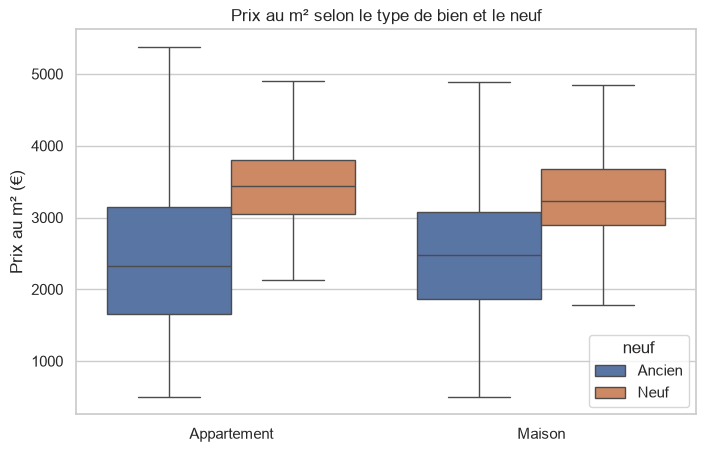

**Interpretation du graphique**

On remarque que la médiane du neuf est toujours supérieure à celle de l'ancien que ce soit pour les appartements ou les maisons. On remarque également une plus grande dispersion pour l'ancien qui peut s'expliquer par une proportion plus grande d'appartement anciens que neuf.

**Choix et interpretation du test**

Nous voulons comparer deux moyennes de deux groupes différents avec une variable quantitative et une variable qualitative à deux modalités. Plus précisément ici on utilise la version de Welch du test t de Student, qui ne suppose pas l’égalité des variances, car les groupes sont de tailles très différentes avec le paramètre equal_var=False. En effet les groupes sont très déséquilibrés (environ 1 200 appartements neufs contre 12 400 anciens) et leurs dispersions de prix diffèrent.

**Constat :** le neuf est nettement plus cher au m² que l'ancien. Pour les appartements, le prix moyen passe de 2 453 €/m² dans l'ancien à 3 503 €/m² dans le neuf (+43 %). Pour les maisons, il passe de 2 528 à 3 339 €/m² (+32 %).

**Validation :** statistic (environ 48 et 49) : l’écart entre les deux moyennes, rapporté à leur variabilité. Au-delà d’environ 2, la différence est déjà significative ; ici, elle est énorme.
pvalue = 0.0 : la probabilité d’observer un tel écart si, en réalité, neuf et ancien avaient le même prix moyen est très faible p < 0,001. Comme la p-value est inférieure à 0,05, on rejette l’hypothèse d’égalité des moyennes : le prix au m² moyen du neuf est significativement supérieur à celui de l’ancien, pour les appartements comme pour les maisons.

**Avis métier :** la prime du neuf s'explique par la performance énergétique (DPE A ou B), les normes de construction récentes, l'absence de travaux à prévoir et des frais de notaire réduits (environ 2 à 3 % contre 7 à 8 % dans l'ancien). L'écart est plus fort pour les appartements, souvent vendus dans des programmes neufs en ville.

##### b. Prix des biens en ventes dans le 68 en fonction de leur surface

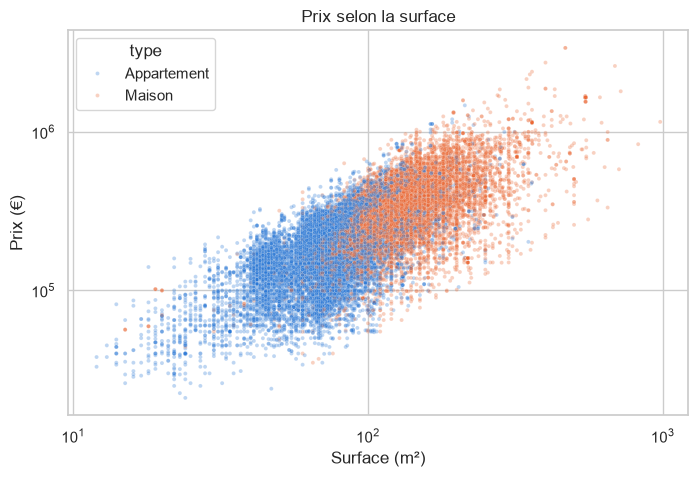

**Interpretation du graphique**

Les nuages de points semblent montrer une relation linéaire entre le prix et la surface. Les appartements restent gloabalement moins chers et une séparation nette à partir de 100m2 laisse place aux maisons

**Choix et intéprétations des tests**

Corrélations de Pearson et de Spearman. On étudie le lien entre deux variables quantitatives (surface et prix). Pearson mesure une relation linéaire. Spearman, basé sur les rangs, mesure une relation monotone (qui monte ou descend régulièrement), même si elle n'est pas linéaire, et il est moins sensible aux valeurs extrêmes. Présenter les deux permet de vérifier si la relation est linéaire.

Résultat :
- Surface / prix : Pearson r = 0,71 (p < 0,001).
- Surface / prix au m² : Pearson -0,15 et Spearman -0,18 pour les appartements ; -0,19 et -0,21 pour les maisons (p < 0,001).

Conclusion :le prix augmente fortement avec la surface. Le prix au m², lui, diminue légèrement quand la surface augmente. Spearman est un peu plus fort que Pearson : la relation n'est pas tout à fait linéaire.

Avis métier : la surface est la variable la plus explicative du prix, ce qui confirme qu'elle sera centrale dans le modèle. La baisse du prix au m² avec la surface est bien connue : c'est la **dégressivité**. Les pièces « coûteuses » (cuisine, salle de bain) existent dans tous les logements, quelle que soit leur taille, donc les petites surfaces reviennent plus cher au m².

##### c. Prix au m2 selon la surface, source DVF+

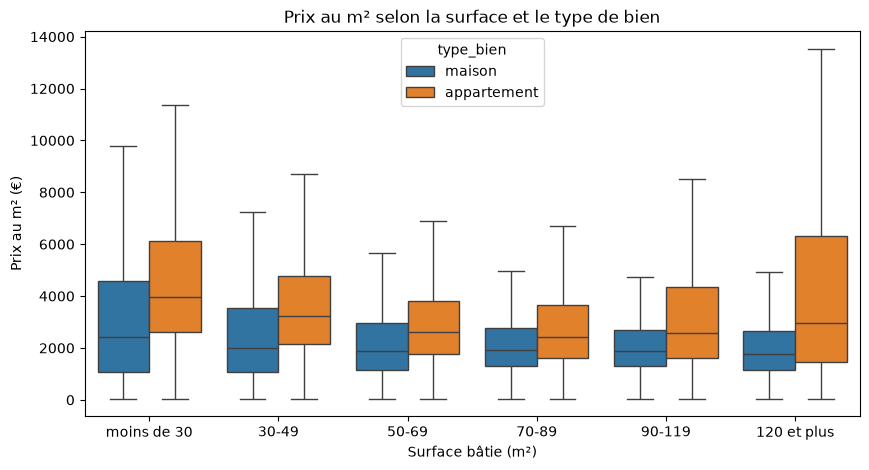

**Constat :**
- Pour les appartements, le prix médian au m² baisse quand la surface augmente, de 3 950 € environ pour moins de 30 m² à 2 400 € environ pour 70-89 m², puis remonte pour les plus grands (environ 2 950 € au-delà de 120 m²).
- Pour les maisons, le prix médian au m² baisse un peu entre les très petites maisons et les autres, puis reste presque stable, autour de 1 800 à 1 900 €.
- Dans chaque tranche, le prix médian au m² des appartements est plus élevé que celui des maisons.
- L'écart interquartile est plus grand pour les appartements, surtout pour les plus de 120 m².

**Hypothèse :** le prix au m² diminue quand la surface augmente.
- H0 : il n'y a pas de lien entre la surface et le prix au m².
- H1 : le prix au m² change avec la surface.

**Méthode de vérification :** corrélation de Spearman entre la surface et le prix au m², séparément pour les maisons et pour les appartements.

**Résultat :** pour les deux types de bien, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre la surface et le prix au m². Ce lien est négatif (le prix au m² baisse quand la surface augmente) et faible : rho = -0,22 pour les appartements, et rho = -0,04 pour les maisons, où il est presque nul.

**Interprétation :** pour les appartements, les petits logements sont plus chers au m². Mais le lien n'est pas en ligne droite : le prix baisse jusqu'à 70-89 m², puis remonte pour les grands appartements. Pour les maisons, la surface ne change presque pas le prix au m². Dans les deux cas, la surface explique peu de chose à elle seule. Les écarts entre maisons et appartements, et la forte dispersion des grands appartements, viennent probablement de la localisation : les appartements sont surtout dans les villes, où les prix sont plus élevés.

**Avis métier :** une explication courante est que, dans un petit appartement, la cuisine et la salle de bain coûtent aussi cher que dans un grand, mais sont réparties sur moins de m². Les petites surfaces sont aussi très demandées (étudiants, investissement locatif).

**Impact projet :** la cible est un prix médian par commune. Elle dépend donc aussi de la taille et du type des logements vendus dans l'année : si une commune vend plus de studios une année, son prix médian au m² peut monter sans que le marché ait changé.

**Action envisagée :** garder la surface et le type de bien comme variables, sans supposer un lien en ligne droite (par exemple en tranches). Vérifier l'effet de la localisation avec la carte (B3).

**Biais / limites :** Spearman ne mesure qu'un lien dans un seul sens, alors que la courbe des appartements baisse puis remonte. Le graphique mélange tous les territoires. Pour les maisons, le prix inclut le terrain, mais la surface ne compte que le bâti.

##### d. Prix au m2 selon le type de biens, source DVF+

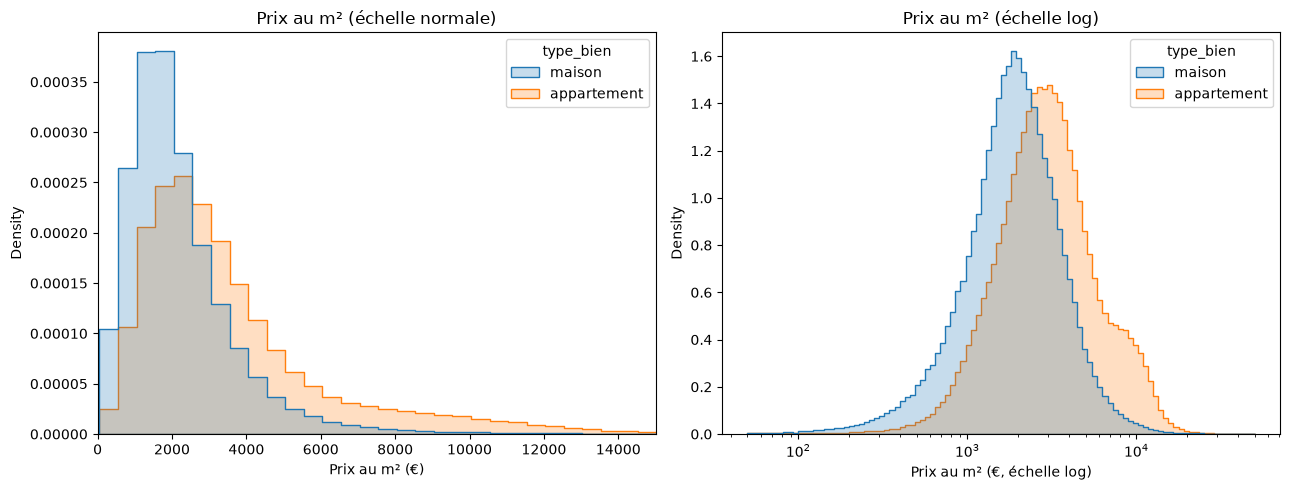

**Constat :**
- En échelle normale, les deux distributions sont très étirées vers la droite : beaucoup de ventes entre 1 000 et 3 000 € au m², et quelques ventes très chères.
- En échelle log, les deux distributions deviennent à peu près symétriques.
- Le prix au m² des appartements est plus élevé que celui des maisons : environ 2 900 € de médiane contre 1 900 €.
- La distribution des appartements a une bosse vers 8 000 à 10 000 € au m².

**Hypothèse :**
- H0 : les prix au m² des maisons et des appartements ont la même distribution.
- H1 : les prix au m² des maisons et des appartements sont différents.

**Méthode de vérification :** test de Mann-Whitney, qui compare deux groupes sans supposer que les données suivent une loi normale. On regarde aussi l'écart entre les médianes.

**Résultat :** la p-value est inférieure à 0,05 : on rejette H0, les prix au m² des maisons et des appartements sont différents. L'écart des médianes est de 1 022 € au m², en faveur des appartements.

**Interprétation :** les maisons et les appartements forment deux marchés différents. L'échelle log rend les distributions à peu près symétriques, ce qui sera utile pour le modèle. La bosse des appartements vers 8 000 à 10 000 € au m² correspond probablement aux grandes villes chères, surtout Paris.

**Avis métier :** les appartements se trouvent surtout dans les villes, où les prix sont élevés. Les maisons sont plus souvent en zone périurbaine ou rurale, où les prix sont plus bas. L'écart vient donc en partie de la localisation, et pas seulement du type de bien.

**Impact projet :** la cible mélange maisons et appartements. Si la part de maisons vendues change d'une année à l'autre dans une commune, le prix médian au m² peut changer sans que les prix aient bougé.

**Action envisagée :** discuter en groupe de deux options : calculer une cible séparée pour les maisons et pour les appartements, ou garder une cible commune et ajouter la part de maisons comme variable. Utiliser le log du prix au m² pour le modèle.

**Biais / limites :** la comparaison mélange tous les territoires. L'échantillon est utilisé sans poids.

##### e. Prix au m2 selon le département, source DVF+

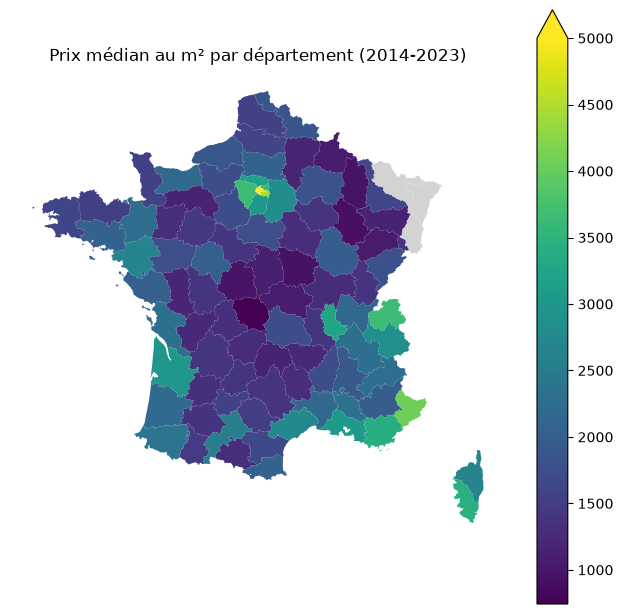

**Constat :**
- Le prix médian au m² varie beaucoup d'un département à l'autre : de 743 € dans la Creuse à 9 511 € à Paris, soit environ 13 fois plus.
- Les départements les plus chers sont Paris (9 511 €), les Hauts-de-Seine (6 288 €), le Val-de-Marne (4 479 €), les Alpes-Maritimes (4 062 €) et les Yvelines (3 667 €).
- Les moins chers sont la Creuse (743 €), la Haute-Marne (909 €), la Nièvre (938 €), la Meuse (946 €) et l'Indre (973 €).
- Les prix élevés se trouvent en Île-de-France, sur la côte méditerranéenne, dans les Alpes et autour des grandes villes. Les prix bas forment une bande du nord-est au centre de la France.
- L'Alsace-Moselle (Bas-Rhin, Haut-Rhin, Moselle) n'a pas de données.
- Sur la carte, l'échelle de couleur s'arrête à 5 000 € : Paris et les Hauts-de-Seine dépassent cette valeur.

**Hypothèse :**
- H0 : le prix au m² a la même distribution dans tous les départements.
- H1 : le prix au m² est différent selon les départements.

**Méthode de vérification :** test de Kruskal-Wallis, qui compare plus de deux groupes sans supposer une loi normale. C'est l'équivalent de Mann-Whitney pour plusieurs groupes.



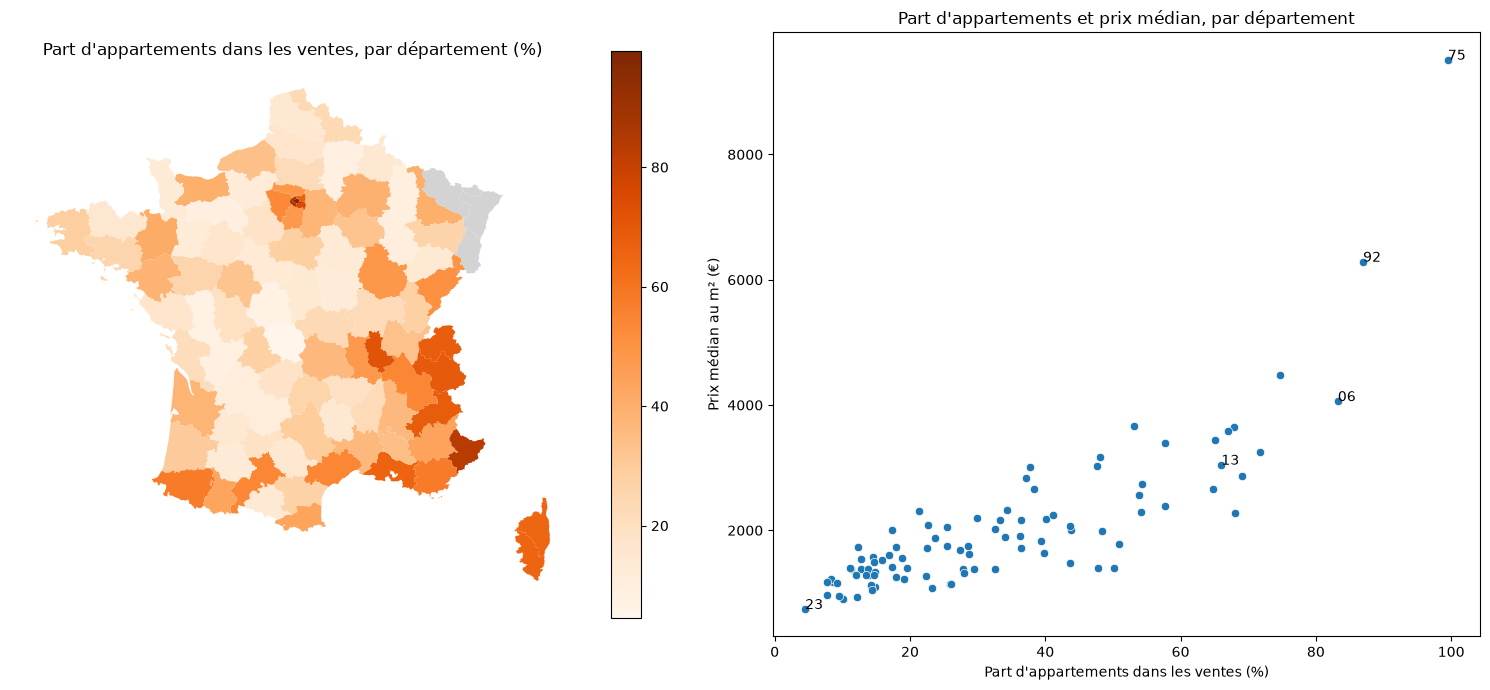

**Constat :**
- La part d'appartements dans les ventes varie beaucoup selon les départements : moins de 10 % dans la Creuse, près de 100 % à Paris. Elle est forte en Île-de-France, sur la côte méditerranéenne, dans les Alpes et autour des grandes villes.
- Plus la part d'appartements est élevée, plus le prix médian au m² du département est élevé : les points forment presque une droite.

**Hypothèse :**
- H0 : il n'y a pas de lien entre la part d'appartements vendus et le prix médian au m² du département.
- H1 : le prix médian au m² change avec la part d'appartements.

**Méthode de vérification :** corrélation de Spearman sur les 93 départements.

**Résultat :** la p-value est inférieure à 0,05 : on rejette H0, le prix au m² est différent selon les départements. L'écart est très grand : le prix médian va de 743 € (Creuse) à 9 511 € (Paris), soit un rapport d'environ 13.

**Interprétation :** la localisation est le facteur le plus fort parmi ceux étudiés : l'écart entre départements est bien plus grand que l'écart entre maisons et appartements (B2) ou entre petites et grandes surfaces (B1). Les départements chers sont aussi ceux où l'on vend le plus d'appartements. Ce n'est pas la part d'appartements qui fait monter les prix : dans les zones denses et attractives, le terrain est rare et cher, on construit donc plus d'immeubles, et les prix sont élevés pour tous les logements. Cela confirme qu'une partie de l'écart entre maisons et appartements vu en B2 vient de leur localisation.

**Avis métier :** les prix sont élevés là où il y a de l'emploi et une forte demande (Île-de-France, grandes villes), et dans les zones touristiques (littoral méditerranéen, Alpes). Ils sont bas dans les territoires peu denses qui perdent des habitants, souvent appelés la « diagonale du vide ».

**Impact projet :** le territoire doit être au centre du modèle. Les variables des autres bases du projet (ménages, logements, bassins de vie) devraient aider à expliquer ces écarts.

**Action envisagée :** garder la localisation dans le modèle et la compléter par des variables territoriales issues des autres bases.

**Biais / limites :** le département est une maille large, qui cache de grands écarts à l'intérieur (par exemple Megève et le reste de la Haute-Savoie). L'Alsace-Moselle n'est pas couverte : le modèle ne pourra pas y faire de prédiction. Sur la carte, l'échelle de couleur est limitée à 5 000 €.

##### f. Evolution du prix au m2 et du nombre de ventes dans le temps, source DVF+

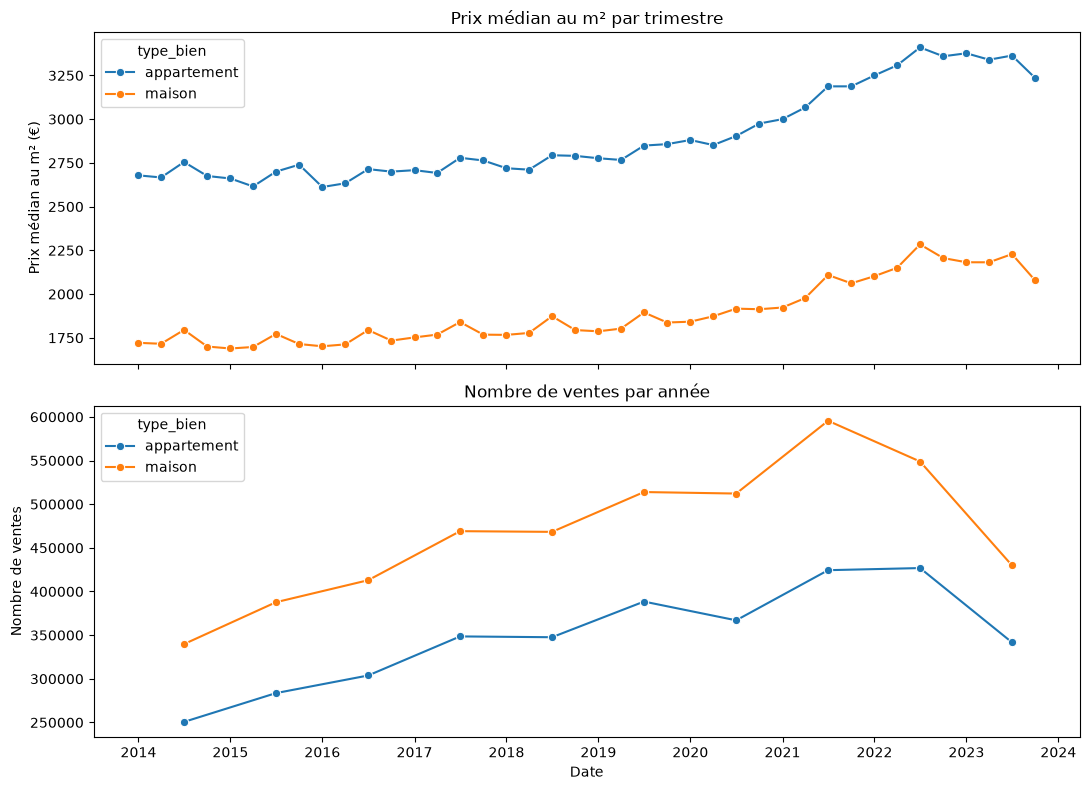

**Résultat :** on distingue trois périodes :
- de 2014 à 2018, les prix sont presque stables, et le nombre de ventes augmente ;
- de 2019 à 2022, les prix augmentent nettement et le nombre de ventes atteint un pic en 2021 (plus d'un million de ventes) ;
- en 2023, le nombre de ventes baisse de 21 % et les prix baissent légèrement.


**Interprétation :** la période compte beaucoup : selon les années, les prix et les ventes ne suivent pas la même tendance. Les prix réagissent avec un temps de retard : ils continuent de monter en 2022 alors que les ventes commencent déjà à baisser.

**Avis métier :** ces évolutions sont liées au contexte économique (taux des crédits, confinement de 2020). Le lien avec les taux sera étudié dans la partie sur les autres sources de données.

**Impact projet :** un modèle qui ne verrait qu'une seule période (par exemple les années de hausse) risquerait de mal prédire une période de baisse. Les données d'entraînement et de test devront être séparées par date, comme le recommande le cours sur les séries temporelles.

**Action envisagée :** garder toute la période 2014-2023 pour l'entraînement. Étudier le lien avec les taux d'intérêt dans la partie sur les autres sources.

**Biais / limites :** le prix médian national mélange tous les territoires et dépend du type de biens vendus chaque année. Les années 2024 et 2025 n'ont pas été regardées.

#### C.5. Pertinence des variables : limitations de notre jeux de données

Après une analyse exhaustive des jeux de données mis à disposition pour la réalisation du projet, le groupe en a conclu qu'il était essentiel d'enrichir notre jeux de données.

En effet, pour pouvoir prédire une évolution pertinente des prix de ventes des biens immobiliers, nous souhaiterions rajouter à l'analyse des données à la fois sur la temporalité et le contexte des ventes (taux de crédit immobiliers, informations concernant les ménages et les logements présents sur le territoire) ainsi que des données sur le territoire, notamment concernant les bassins de vie et les équipements présents sur les territoires.

## 2. Enrichissement du jeux de données initial

![alt text](pieces_jointes/MCD_Compagnon_Immobilier_v2.png)

### A. Données sur les taux de crédits immobiliers

**Pourquoi ajouter ces données?**

**Description de la base de donnée choisie**

**Structure d'une ligne**

**Analyse des variables** en annexe.

**Conclusion**

### B. Données sur les bassins de vie

**Pourquoi ajouter ces données ?**

Le bassin de vie est par définition le plus petit territoire sur lequel les habitants ont accès aux équipements et service les plus courants. Ils peuvent regrouper une ou plusieurs communes.

L'intérêt est d'étudier si l'évolution du prix au m2 médian par commune et par année peut dépendre ou non du type de bassins de vie dans lequel le bien se trouve et ainsi observer si l'évolution des prix dépend de la maille de la commune ou du bassin de vie.

**Description de la base de donnée choisie**
| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine |INSEE | aucun fichier de métadonnées associé mais 2 feuilles descriptives dans l'excel|
| Finalité initiale | | |
| Mode de collecte | INSEE, code officiel géographique| |
| Extraction / mise à jour | 2022 à 2026 | |
| Documentation / licence | aucune information| |
| Population / objets annoncés | 1e feuille : nom de chaque bassin de vie, intitulé, type et nombre de communes présentes ; 2e feuilles : par code géographique officiel des communes on trouve son libellé, le bassin de vie auquel elle appartient, le type de commune, son département et sa région | |
| Période / territoire, si pertinents | France avec ses DOM-TOM| |

**Structure d'une ligne**
| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 34 935 lignes × 8 colonnes |
| Contenu général, en une phrase | Pour chaque commune on a comme information son libellé et son type, le bassin de vie auquel elle appartient, son intitulé et son type, le nombre de communes qui se trouvent dans le bassin de vie ainsi que son département et sa région|
| Unité d’observation | Une commune identifiée par son code géographique |
| Identifiants / clés possibles | le code géographique |
| Une ou plusieurs lignes par objet ? Pourquoi ? |Une ligne par commune. |
| Doublons exacts : nombre / proportion | 0 (0 %) : aucune annonce identique sous deux identifiants différents|
| Répétitions métier : règle examinée / résultat | non applicable |

**Analyse des variables et distribution** disponibles en Annexe n° X

**Conclusion**
*Constat :*

Les codes géographiques officiels de chaque commune sont uniques, ils serviront de lien avec la table DVF+.

*Action envisagée :*

Pour obtenir pour chaque commune le détail du bassin de vie dont elle fait partie il faudra fusionner les informations contenues sur 2 feuilles du fichier Excel initial.

*Incertitudes / limites, si nécessaire :*

Un code géographique peut aussi être un code de bassin de vie. Viligance.

DONNEES DE 2022 A 2026


### C. Données sur les ménages

**Pourquoi ajouter ces données?**

La composition des ménages peut indiquer les besoins et demandes de biens immobiliers présents sur le marché et impacter les achats résultants.

**Description de la base de donnée**
| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | INSEE 2022 via l'IRIS | Recensement de la population, base infracommunale 2022 |
| Finalité initiale | Recensement |
| Mode de collecte | Recensement de la population | |
| Extraction / mise à jour | données de 2022 diffusées selon la géographie en vigueur au 1er janvier 2024 |  |
| Documentation / licence | https://www.insee.fr/fr/statistiques/8647008#consulter | |
| Population / objets annoncés | population française recensée en 2022 | |
| Période / territoire, si pertinents | France hors Mayotte, 2022 | |

**Structure d'une ligne**
| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 49 276 lignes × 80 colonnes |
| Contenu général, en une phrase | Par IRIS, par commune, toutes les statistiques liées à la population (nombres de ménages en fonction du type de ménage, nombre de personnes seules en fonction de leur sexe, population de différentes tranches d'âges, ...) |
| Unité d'observation | un **IRIS** : ilots regroupés pour l'information statistique ; découpage territorial de l'INSEE d'environ 2 000 habitants |
| Identifiants / clés possibles | IRIS |
| Une ou plusieurs lignes par objet ? Pourquoi ? | 1 ligne par IRIS |
| Doublons exacts : nombre / proportion | 0 (0 %) |
| Répétitions métier : règle examinée / résultat | |

**Analyse des variables** et de leur distribution en annexe XX.

**Conclusion**

Il faudra être vigilant à l'exploitation des données via le code commune et non via le code IRIS (trop complexe à mettre en place car il faut une liaison spatiale entre les coordonnées des communes et les contours des IRIS alors que la cible est définie par commune).

De plus il y a énormément de données pour un seul IRIS, parfois une variable est décomposée en plusieurs variables, exemple le taux de personnes vivant seules et décomposé par sexe et par tranche d'âge.

L'élaboration de ratios pertinents par commune pourrait permettre de se séparer de variables dépendantes entre elles tout en apportant une description structurelle des communes.

### D. Données sur le parc d'équipements

### E. Données sur la délinquance

**Pourquoi ajouter ces données?**

La délinquance dans une zone de vie peut avoir un impact sur les prix des biens d'après le vécu des personnes du groupe. Il est donc intéressant de vérifier cette intuition lors de l'analyse des prix médian au m2 par commune et par année en fonction de la délinquance observée dans la commune.

**Description de la base de donnée**
La base est produite par le **SSMSI** (Service statistique ministériel de la sécurité intérieure), le service statistique du ministère de l'Intérieur. Elle repose sur les **procédures enregistrées par la police et la gendarmerie** avant leur transmission à la justice : plaintes, signalements, flagrants délits, ou faits constatés par les services eux-mêmes. Elle mesure donc la délinquance **enregistrée**, et non toute la délinquance. Son niveau dépend du dépôt de plainte, très variable selon l'atteinte : d'après les enquêtes de victimation (2011-2018), 74 % des victimes de cambriolage portent plainte, contre 12 % des victimes de violences sexuelles.

Les faits sont comptés dans la **commune où ils ont été commis**, avec deux exceptions :
- les escroqueries sont comptées au domicile de la victime, car une grande partie a lieu sur internet ;
- les infractions sur les stupéfiants comptent des personnes mises en cause, à la date où l'affaire est élucidée. Elles reflètent donc en partie l'activité des services.

La base communale donne **15 indicateurs**, chacun en **nombre** et en **taux pour 1 000 habitants** (pour 1 000 logements dans le cas des cambriolages). L'unité de compte dépend de l'indicateur : victime, infraction, véhicule ou personne mise en cause.

**Secret statistique :** une commune n'est diffusée que si plus de 5 faits ont été enregistrés pendant 3 années successives (colonne `est_diffuse` = « diff »). Sinon (« ndiff »), le nombre et le taux sont vides. À la place, la base donne la moyenne des communes non diffusées du même département (`complement_info_nombre`, `complement_info_taux`). Cette règle protège les personnes concernées et évite d'interpréter des chiffres trop petits pour être fiables.

Les données couvrent **2016 à 2025** : il n'existe pas de données communales pour 2014 et 2015. Elles sont fournies dans la **géographie communale du 1er janvier 2026**. Les chiffres d'une année sont arrêtés en avril de l'année suivante.

**Analyse des variables** en annexe.

**Conclusion et observations**

La base de délinquance du SSMSI est une source pertinente pour décrire l'insécurité dans les communes. Elle est administrative : elle compte les crimes et délits enregistrés par la police et la gendarmerie, et non toute la délinquance. Son niveau dépend du dépôt de plainte, plus fréquent pour les cambriolages (74 %) que pour les violences sexuelles (12 %).

La base compte **5 238 000 lignes (une commune × une année × un indicateur) et 13 variables**. La grille est complète : 34 920 codes géographiques (communes de 2026 et arrondissements de Paris, Lyon et Marseille), 10 années de 2016 à 2025 et 15 indicateurs. Il n'existe pas de données communales pour 2014 et 2015.

L'examen de la base montre une qualité satisfaisante :
- aucun doublon exact ni sur la clé commune × année × indicateur ;
- Paris, Lyon et Marseille sont présentes à deux niveaux, la ville entière et ses arrondissements, qui décrivent exactement les mêmes faits : ce sont des doublons métier ;
- les valeurs manquantes s'expliquent entièrement par le **secret statistique**. 46 % des lignes sont masquées (de 9 % à 70 % selon l'indicateur), et la base fournit pour elles la moyenne départementale des communes masquées. Le taux manque aussi pour six villages détruits de la Meuse, sans habitant.

Au niveau communal, les taux sont difficiles à utiliser. Pour 13 indicateurs sur 15, la majorité des communes n'enregistre aucun fait. Quelques communes peu peuplées mais très fréquentées ont des taux extrêmes, comme Roissy-en-France (aéroport) ou le Mont-Saint-Michel. Au bassin de vie, les taux deviennent stables : plus aucune médiane nulle, et des valeurs extrêmes beaucoup moins isolées.

### F. Données sur le parc de logements

**Pourquoi ajouter ces données**

La disponibilité des logements dans une commune peut avoir un impact sur le prix médian au m2 par commune et par année, instinctivement c'est l'effet de l'offre et de la démande sur l'évolution des prix des biens dans une commune. Il sera donc intéressant de mettre ces données dans l'analyse pour évaluer leur poids dans l'évolution des prix.

**Description de la base de donnée**
| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | INSEE, recensement de la population. Jeu de données « Logement en 2022 – Base infracommunale (IRIS) ». | Page INSEE : insee.fr/fr/statistiques/8647012 |
| Finalité initiale | Statistique publique : décrire le parc de logements et les résidences principales (taille, époque de construction, statut d'occupation, emménagement, chauffage, voitures) à une échelle fine. Rien n'a été produit pour estimer des prix. | Aucun prix ni loyer : la cible du projet n'y figure pas. |
| Mode de collecte | Enquêtes annuelles du recensement : les petites communes sont recensées entièrement une fois tous les 5 ans, les communes de 10 000 habitants ou plus par sondage chaque année. Le millésime « 2022 » combine les enquêtes de 2020 à 2024. | Les effectifs sont des **estimations** (85 % des valeurs ont des décimales), donc peu fiables pour les petits IRIS. |
| Extraction / mise à jour | Publié le 16/10/2025, téléchargé sous forme de `base-ic-logement-2022_csv.zip` (données + dictionnaire `meta_…`). Une base par millésime, mise à jour chaque année. | Le millésime 2022 est le plus récent disponible. Les collectivités d'outre-mer sont dans un fichier séparé, non utilisé ici. |
| Documentation / licence | Dictionnaire des variables fourni (`meta_base-ic-logement-2022.CSV`) : les 101 colonnes y sont toutes décrites. Définitions du recensement sur insee.fr. Réutilisation libre avec mention « Source : Insee ». | Licence non précisée sur la page. Le code `LAB_IRIS` (label de qualité) n'est pas expliqué dans le dictionnaire. |
| Population / objets annoncés | Les IRIS des communes découpées (environ 2 000 habitants chacun) et les communes non découpées, traitées comme un seul IRIS. Fichier : **49 276 lignes**, dont 16 240 IRIS de communes découpées et 33 036 communes entières. | Maille mixte : quartier en ville, commune entière ailleurs. |
| Période / territoire, si pertinents | Recensement 2022 (enquêtes 2020-2024), géographie au 1er janvier 2024. France hors Mayotte : 34 960 communes, 100 départements, dont 971 à 974. | Une seule année. L'Alsace-Moselle est présente (2 149 IRIS) mais absente de DVF+. La géographie 2024 diffère de celle de LOVAC (2026) : quelques communes fusionnées sont à vérifier. |

*Impact projet :*

La base ne fournit pas la cible, seulement des variables explicatives sur les territoires (vacance, résidences secondaires, profil du parc). La jointure se fera par le code commune puis par bassin de vie, et le détail par quartier sera perdu. Avec une seule année, ces variables distingueront les territoires entre eux mais n'expliqueront pas l'évolution des prix.

*Incertitudes / limites, si nécessaire :*

- Les petits IRIS ont des effectifs estimés peu fiables : un seuil minimum (50 logements) est nécessaire pour calculer des taux.
- Utiliser le millésime 2022 pour des ventes antérieures introduit une légère anticipation, jugée faible car le parc évolue lentement.
- La géographie (communes au 1er janvier 2024) diffère de celle de LOVAC (2026) : des communes fusionnées pourraient ne pas trouver de correspondance.
- La signification des codes `LAB_IRIS` (label de qualité) n'est pas documentée dans le dictionnaire.
- La licence n'est pas précisée sur la page de l'INSEE.

**Structure d'une ligne**
| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 49 276 lignes × 101 colonnes : 4 identifiants en texte (`IRIS`, `COM`, `TYP_IRIS`, `LAB_IRIS`) et 97 effectifs numériques (`P22_…`, `C22_…`). |
| Contenu général, en une phrase | Pour chaque IRIS, le nombre estimé de logements selon leur catégorie (principales, secondaires, vacants), leur type (maison, appartement), leur taille, leur époque de construction, leur statut d'occupation et les caractéristiques des ménages qui les occupent. |
| Unité d’observation | **L'IRIS** : un quartier d'environ 2 000 habitants dans les villes découpées (16 240 lignes), ou **la commune entière** pour les petites communes non découpées (33 036 lignes, code IRIS terminé par `0000`). Paris, Lyon et Marseille sont décrites par **arrondissement** (75101… ; le code 75056 n'existe pas). |
| Identifiants / clés possibles | **`IRIS`** est une clé unique (49 276 valeurs pour 49 276 lignes). **`COM`** n'est pas unique : c'est la clé de regroupement vers la commune, puis le bassin de vie. |
| Une ou plusieurs lignes par objet ? Pourquoi ? | **Une ligne par IRIS.** En revanche, plusieurs lignes par commune pour les 1 924 communes découpées (jusqu'à 153 pour Toulouse, 146 pour Nice, 116 pour Strasbourg ; 26 et plus pour Colmar). C'est normal : il faut additionner les IRIS pour obtenir la commune. Aucune commune ne mélange une ligne « commune entière » et des IRIS. |
| Doublons exacts : nombre / proportion | **0** (0 %). |
| Répétitions métier : règle examinée / résultat | Règle : deux IRIS différents avec exactement les mêmes 97 chiffres. Résultat : 154 lignes, dont **152 IRIS sans aucun logement** (tous les effectifs à 0 : zones d'activité, parcs, IRIS « divers ») et 2 IRIS avec 1 seul logement vacant. Ce sont des **répétitions normales**, pas des doublons : ces lignes seront exclues car elles n'apportent aucune information sur le logement. |

**Analyse des variables** en annexe.

**Conclusion**

la base logement décrit à la fois la tension du marché et le gradient urbain, du village à la grande ville, qui structure le marché immobilier. La vacance (médiane 7,6 % par commune) est très inégale et signale les territoires en déprise. La taille des logements (η² = 0,31, effet fort) et l'accessibilité sans voiture (d = 1,48, effet très fort) sont les marqueurs les plus nets du gradient urbain. La mobilité résidentielle est fortement liée au marché locatif (ρ = 0,52) : ces deux variables sont en partie redondantes. Toutes sont de bons candidats pour expliquer les prix au m² ; leur intérêt réel sera mesuré après la jointure avec DVF+.

### G. Données sur les logements vacants

**Pourquoi ajouter ces données**

Ajout d'informations plus spécifiques sur les logements vacants via les données fiscales pour compléter les données précédents sur les logements qui sont issues d'un sondage.

**Description de la base de données**
| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Cerema (équipe DataFoncier), pour le ministère du Logement (DGALN), à partir des fichiers fiscaux de la DGFiP (fichier 1767 bis Com) et des Fichiers fonciers. | Onglet « Métadonnées » du fichier |
| Finalité initiale | Repérer les logements privés vacants pour le plan national « Zéro logement vacant » (outil des collectivités). Rien n'a été produit pour estimer des prix. | Aucun prix : pas de cible |
| Mode de collecte | Administratif : un logement privé est « vacant » s'il n'est déclaré occupé par personne au 1er janvier (taxe d'habitation, puis déclarations GMBI depuis 2023). Données exhaustives, pas un sondage. | Vacance « fiscale » : elle peut compter des logements en réalité occupés (déclarations manquantes, retards de mise à jour) |
| Extraction / mise à jour | Version open data publiée en juin 2026, millésimes 2020 à 2026, mise à jour annuelle. | Rupture de série depuis 2023 (fin de la taxe d'habitation, dispositif GMBI), signalée dans la note de version |
| Documentation / licence | Onglet « Métadonnées » : définitions, sources, requêtes, taux de secret, liens Cerema (doc-datafoncier.cerema.fr). Version « secrétisée » pour l'open data. | Licence à vérifier sur data.gouv.fr. Une incohérence de date dans la documentation (millésime 2023 annoncé au 01/01/2023, comme 2024) |
| Population / objets annoncés | Logements du parc **privé** (maisons et appartements à usage d'habitation, hors bailleurs sociaux), agrégés par commune. | Le parc social n'est pas couvert |
| Période / territoire | Situations au 1er janvier 2019 à 2025 (millésime N = situation au 1er janvier N-1). France entière, Mayotte comprise, géographie communale au 1er janvier 2026. | Géographie 2026 différente de celle du recensement (2024) |

*Impact projet :* c'est une variable explicative annuelle : elle permet de respecter la règle « informations de l'année précédant la vente », ce que le recensement (un seul millésime) ne permet pas.

*Incertitudes / limites :* vacance « fiscale », plus élevée que la vacance observée par le recensement ; rupture de série depuis 2023 ; documentation incohérente sur la date du millésime 2023.

**Structure d'une ligne**
| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 34 912 lignes × 28 colonnes (feuille « COM open data ») ; 4 autres feuilles : métadonnées, totaux France, régions, départements. |
| Contenu général, en une phrase | Pour chaque commune et chaque millésime de 2020 à 2026 : nombre de logements privés vacants, vacants depuis plus de 2 ans, et parc privé total. |
| Unité d’observation | La commune (géographie 2026). Paris, Lyon et Marseille par arrondissement (45 codes, aucun 75056, 69123 ou 13055), comme DVF+ et le recensement. |
| Identifiants / clés possibles | `CODGEO_26` : unique (34 912 / 34 912), 5 caractères. `EPCI_26` (intercommunalité) : clé de regroupement. |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Une ligne par commune, mais **les années sont en colonnes** (format « large ») : 3 variables × 7 millésimes. Il faudra passer au format « long » (une ligne par commune et par année) pour joindre avec les ventes. |
| Doublons exacts : nombre / proportion | 0 (0 %). |
| Répétitions métier : règle examinée / résultat | Code commune répété : aucun. |

*Impact projet* : nécessité de passer au format long (34 912 communes × 7 millésimes = 244 384 lignes) pour se joindre avec le DVF+ par commune et par année.

**Analyse des variables et distribution** en annexe.

**Conclusion**

Les données de cette base permettent d'obtenir avec plus de fiabilités les informations sur les logements vacants, qui peuvent mesurer la tension sur le marché immobilier.

## 3. Pre processing

### A. Travail sur le DVF+

**Objectif :** construire la variable cible du projet à partir de DVF+, la décrire, puis étudier ce qui la fait varier.

| Élément | Choix |
|---|---|
| Source | DVF+ (Cerema), table mutation. Voir la fiche de description. |
| Périmètre | Ventes d'un seul logement ancien (une maison ou un appartement), dans une seule commune, en France métropolitaine. VEFA et DOM exclus. L'Alsace-Moselle n'est pas couverte par DVF+. |
| Période étudiée | 2014-2023. L'année 2025 est réservée au test et n'est pas regardée. L'année 2024 est mise de côté en attendant la décision du groupe. |
| Cible | Prix médian au m² par commune et par année, accompagné du nombre de ventes. |
| Données utilisées | La population complète (8 181 968 ventes) pour construire la cible. L'échantillon d'apprentissage (835 288 ventes) pour étudier les relations entre variables. |
| Points provisoires | La période définitive et le seuil de maille seront confirmés par le groupe le 14/10. |

**Construction de la cible**
*Variables :* `valeurfonc` (prix de vente, en €), `sbati` (surface bâtie, en m²), `libtypbien` (maison ou appartement), `l_codinsee` (code de la commune), `anneemut` (année de la vente).

*Pourquoi regarder cela :* la cible est un prix médian au m² par commune et par année. Avant de la calculer, il faut vérifier que le prix au m² de chaque vente est plausible. Une valeur foncière nulle ou une surface erronée peut fausser la médiane, surtout dans les petites communes où il y a peu de ventes.

*Méthode :*
1. calculer le prix au m² de chaque vente ;
2. repérer les valeurs manquantes, nulles et extrêmes, par type de bien ;
3. examiner quelques cas extrêmes pour fixer des règles d'exclusion ;
4. calculer la table commune × année : prix médian au m² et nombre de ventes.

*Résultats :*
- Entonnoir : 8 181 968 ventes → 8 178 799 avec une valeur foncière → 8 161 192 après le seuil bas → 8 160 652 après le seuil haut. Au total, 21 316 ventes sont exclues (0,26 %).
- La table cible compte 307 479 lignes commune × année, avec pour chacune le nombre de ventes, le prix médian au m² et la part de maisons. Aucun seuil de maille n'est encore appliqué.

**Création d'un seuil de maille**
une médiane calculée sur peu de ventes change beaucoup d'une année à l'autre, par simple hasard. Il faut choisir un nombre minimum de ventes pour qu'une commune soit retenue une année donnée. Plus ce seuil est haut, plus la cible est fiable, mais moins elle couvre de communes.

*Méthode :*
1. pour plusieurs seuils, mesurer ce qu'on garde : lignes commune × année, communes, ventes ;
2. mesurer comment la variation annuelle du prix médian se disperse selon le nombre de ventes.

*Constat étape 1 :*
- Plus le seuil est haut, plus on perd de communes. Mais on perd peu de ventes : avec un seuil de 10 ventes, on garde 36 % des lignes et 91 % des ventes.
- Les communes qui ont des ventes chaque année au-dessus du seuil sont 6 595 avec un seuil de 10, et 3 796 avec un seuil de 20.

*Constat étape 2 :*
Quand il y a peu de ventes, la variation annuelle du prix médian change beaucoup d'une année sur l'autre. C'est le cas d'une grande partie des communes : 46 % des comparaisons d'une année à l'autre portent sur moins de 5 ventes.

Interprétation :
les prix augmentent d'environ 3 % par an. Avec 10 à 19 ventes, l'écart interquartile est de 22,5 points, donc bien plus grand que cette hausse. Dans les petites communes, la variation du prix médian dépend surtout des quelques biens vendus dans l'année, et pas du marché. On ne voit pas de seuil évident sur le graphique : il faudra choisir entre garder beaucoup de communes et avoir une cible fiable.

*Avis métier et impact projet :*
- La DGFiP conseille, quand il y a peu de ventes, d'élargir la zone ou la période étudiée plutôt que de se baser sur quelques ventes.
- la cible par commune et par année n'est fiable que pour une partie des communes. Le seuil choisi fixe le nombre de communes que le modèle pourra prédire.

**Analyses graphiques** disponibles dans la partie C.4., graphiques c à f, ainsi qu'en annexe X pour les graphiques g à j.

**Variables candidates pour la modélisation**

| Variable / feature envisagée | Construite à partir de | Justification (fiche) |
|---|---|---|
| Prix médian au m² de l'année précédente | `prix_m2` | f : le prix d'une année dépend de la période |
| Nombre de ventes de l'année précédente | nombre de ventes | j, f : fiabilité de la médiane, activité du marché |
| Part de maisons | `type_bien` | d, e : deux marchés différents, effet de composition |
| Surface médiane | `sbati` | c : le prix au m² dépend de la surface |
| Part de studios, ou surface par pièce | `nbapt1pp` à `nbmai5pp`, `sbati` | g : effet propre du nombre de pièces |
| Part de ventes avec dépendance | `nblocdep` | h : effet des dépendances sur le prix des appartements |
| Part de maisons en copropriété | `sterr`, `nblot` | un terrain à 0 signale une copropriété |
| Département | `coddep` | e : la localisation est le facteur le plus fort |
| Année | `anneemut` | f : trois périodes différentes |
| Taux moyen des crédits immobiliers | Banque de France | f : à étudier avec l'ajout de la base de données sur les taux |

**Dette reportée : analyses non faites et pourquoi**
- *Comparaison du neuf et de l'ancien :* demande de relire les fichiers bruts, puisque la VEFA a été retirée du périmètre. Son exclusion est justifiée dans l'audit.
- *Localisation plus fine que le département :* les coordonnées des parcelles (`geompar_x`, `geompar_y`) et le code commune le permettraient. Plusieurs analyses ont cette limite.
- *Effet de composition sur la cible commune × année :* vu à l'échelle nationale et départementale, pas encore mesuré commune par commune.
- *Années 2024 et 2025 :* volontairement non regardées, en attendant la décision sur la période et le découpage.

### B. Travail sur les taux de crédits immobiliers

### C. Travail sur les bassins de vie

**Le DVF+ couvre les ventes de 2014 à 2025**, alors que l’INSEE publie deux millésimes de bassins de vie : BV2012 (valable 2014-2022) et BV2022 (valable 2022-2026). Une même commune peut donc avoir changé de bassin, de code ou de périmètre pendant la période. Pour rattacher correctement chaque vente à un bassin, il fallait vérifier ce qui change d’un millésime à l’autre et ce qui change dans les codes communes eux-mêmes.

**Ce qui a été constaté**

*Données propres :* 34 955 communes (2012) et 34 935 (2022), une ligne par commune, clé CODGEO unique, sans doublon ni valeur manquante.

*Périmètres instables :* environ 25 % des communes changent de bassin entre 2012 et 2022 (surtout le littoral méditerranéen, Mayotte à 100 %). Les codes de bassin restent les mêmes, mais leur contenu change.
Peu de disparitions : 24 communes disparaissent et 4 apparaissent (~0,1 %).

*Test de jointure avec le DVF+ :*
6,4 % des ventes sans bassin (614 000 sur 9,66 M), pour deux raisons :
- arrondissements de Paris, Lyon et Marseille absents du fichier INSEE (582 000 ventes) ;
- anciens codes de communes fusionnées depuis 2014 (32 000 ventes).

**Ce qui a été décidé**
- Référence unique : BV2022. Elle est conservée pour toute l’analyse, car elle évite un « saut » artificiel entre deux découpages. BV2012 sert seulement aux tests comparatifs.
- Table de passage INSEE (2003 → 2026) pour relier les anciens codes communes aux codes actuels.
- Ajout manuel des arrondissements : 751xx → 75056, 6938x → 69123, 132xx → 13055.
- Scissions de communes : seuls 4 codes changent de bassin, dont 2 scissions antérieures à 2014 (sans impact) et 2 en 2017.
- Fusions de communes : aucune ne change de bassin, donc le traitement est simple.
- Typage : REG, TYPE_BV2022 et TYPE_COMMUNE_BV2022 passent en str ou category, et les codes restent en str.

**Résultat**

La table bv_liaison_2022 (parquet et csv) relie code commune initial, code 2026, bassin de vie et son type. Pour joindre le DVF+, il faut utiliser CODGEO_INI, qui couvre à la fois les anciens et les nouveaux codes.

### D. Travail sur les ménages

Le fichier décrit la structure des ménages (personnes seules, monoparentales, familles nombreuses…) par IRIS. Le recensement est une photo de 2022, alors que le DVF+ couvre 2014-2025. **Le décalage est acceptable car la composition des ménages évolue lentement**, sauf dans les zones à forte construction neuve après 2022. Aucun historique ne peut être reconstitué.

**Qualité**

49 276 IRIS × 80 colonnes, une ligne par IRIS, sans doublon ni valeur manquante.
Variables numériques décimales (redressements INSEE), nombreuses redondances à élaguer.

**Pre-processing réalisé**

Cinq ratios par commune sont calculés avec protection contre la division par zéro (C22_MEN > 0) :

- taux de personnes seules,
- part de familles monoparentales,
- part de familles nombreuses (3 enfants et plus),
- taille moyenne des ménages,
- part de couples sans enfant.

Le fichier de sortie ratios_iris_menages.csv ne garde que 11 colonnes : CODE_IRIS, COM, LAB_IRIS, TYP_IRIS, C22_MEN, C22_PMEN et les 5 ratios.

**Jointure avec le DVF+ : via le code commune**

Les ménages sont reliés au DVF+ par le code commune (COM), d'où le calcul des ratios par commune.
Attention cependant aux cas particuliers des arrondissements de Paris, Lyon et Marseille, dont on perdra le détail concernant les ménages car ils sont tous regroupés dans un unique bassin de vie par ville.

**Constats utiles**

38,6 % des ménages sont des personnes seules et 10,1 % des familles monoparentales, soit près d’un foyer sur deux en demande de petites et moyennes surfaces.

**À corriger ou trancher**

Écart de 25 communes entre ce fichier (34 960) et la composition BV2022 (34 935), à vérifier.

### E. Travail sur le parc des équipements

**Périmètre :** comparaison descriptive des prix médians au m² entre communes où la présence d’un équipement est connue et communes où son absence est connue, séparément pour les maisons et les appartements, de 2016 à 2025.

**Variables présentes dans la table de résultats**

- `annee` : année du prix immobilier.
- `type_bien` : maisons ou appartements.
- `code_equipement`, `equipement` : identifiant et libellé de l’équipement.
- `n_present`, `n_absent` : effectifs des communes dans chaque groupe.
- `mediane_present_eur_m2`, `mediane_absent_eur_m2` : médianes des prix communaux en €/m².
- `ecart_eur_m2` : médiane présent − médiane absent ; c’est la valeur colorée dans la carte.
- `ecart_pct_vs_absent` : écart relatif par rapport à la médiane du groupe absent.
- `couverture_connue_pct` : part des observations pour lesquelles la présence/absence est connue.
- `bpe_annee_source` : millésime BPE associé.
- `index` : colonne d’index exportée, sans rôle analytique.

Dans la source consolidée, les variables amont utilisées sont `code_commune`, `annee`, `n_maison`, `n_appart`, `prix_m2_med_maison`, `prix_m2_med_appart`, `bpe_annee_source` et les six indicateurs `bpe_presence_CODE` listés ci-dessous :

| Code | Équipement | Variable source |
|---|---|---|
| a206 | Bureau de poste | `bpe_presence_a206` |
| b207 | Boulangerie-pâtisserie | `bpe_presence_b207` |
| d502 | Accueil du jeune enfant (EAJE) | `bpe_presence_d502` |
| d101 | Établissement de santé — court séjour | `bpe_presence_d101` |
| d107 | Maternité | `bpe_presence_d107` |
| d113 | Maison de santé pluriprofessionnelle | `bpe_presence_d113` |

Les valeurs BPE inconnues sont exclues des groupes « présent » et « absent » : elles ne sont pas assimilées à une absence.

**Étapes de préprocessing**

1. Partir de la table consolidée commune–année, avec prix, effectifs de ventes et indicateurs BPE.
2. Séparer les maisons (`prix_m2_med_maison`, `n_maison`) des appartements (`prix_m2_med_appart`, `n_appart`).
3. Retenir les observations avec plus de deux ventes pour le type de bien considéré.
4. Selon la méthode consignée pour l’analyse, écrêter les prix communaux aux quantiles 1 % et 99 %, par année et type de bien, pour limiter l’influence des valeurs extrêmes.
5. Pour chaque équipement et année, séparer présence connue (`1`) et absence connue (`0`) ; exclure les valeurs inconnues.
6. Calculer les médianes des prix communaux dans chaque groupe.
7. Calculer `ecart_eur_m2 = mediane_present_eur_m2 − mediane_absent_eur_m2`.
8. Conserver effectifs, médianes, écart, pourcentage relatif, couverture connue et millésime BPE.
9. Masquer les cellules si un groupe contient moins de 50 communes ou si l’écart n’est pas calculable.
10. Signaler le changement de millésime : BPE 2015 pour les années de prix 2016–2020 ; BPE 2020 pour 2021–2025.

**Important :** le code complet du calcul amont de la table de résultats n’est pas inclus dans les fichiers fournis. Le script livré régénère les cartes à partir du CSV de résultats ; il ne prétend pas recalculer toute la table depuis la source consolidée.

**Carte thermique — Maisons**

Carte thermique intégrée au notebook : les écarts descriptifs de prix médians au m² sont affichés ci-dessous. L’image est incorporée au fichier et ne nécessite aucun chemin externe pour être visible.

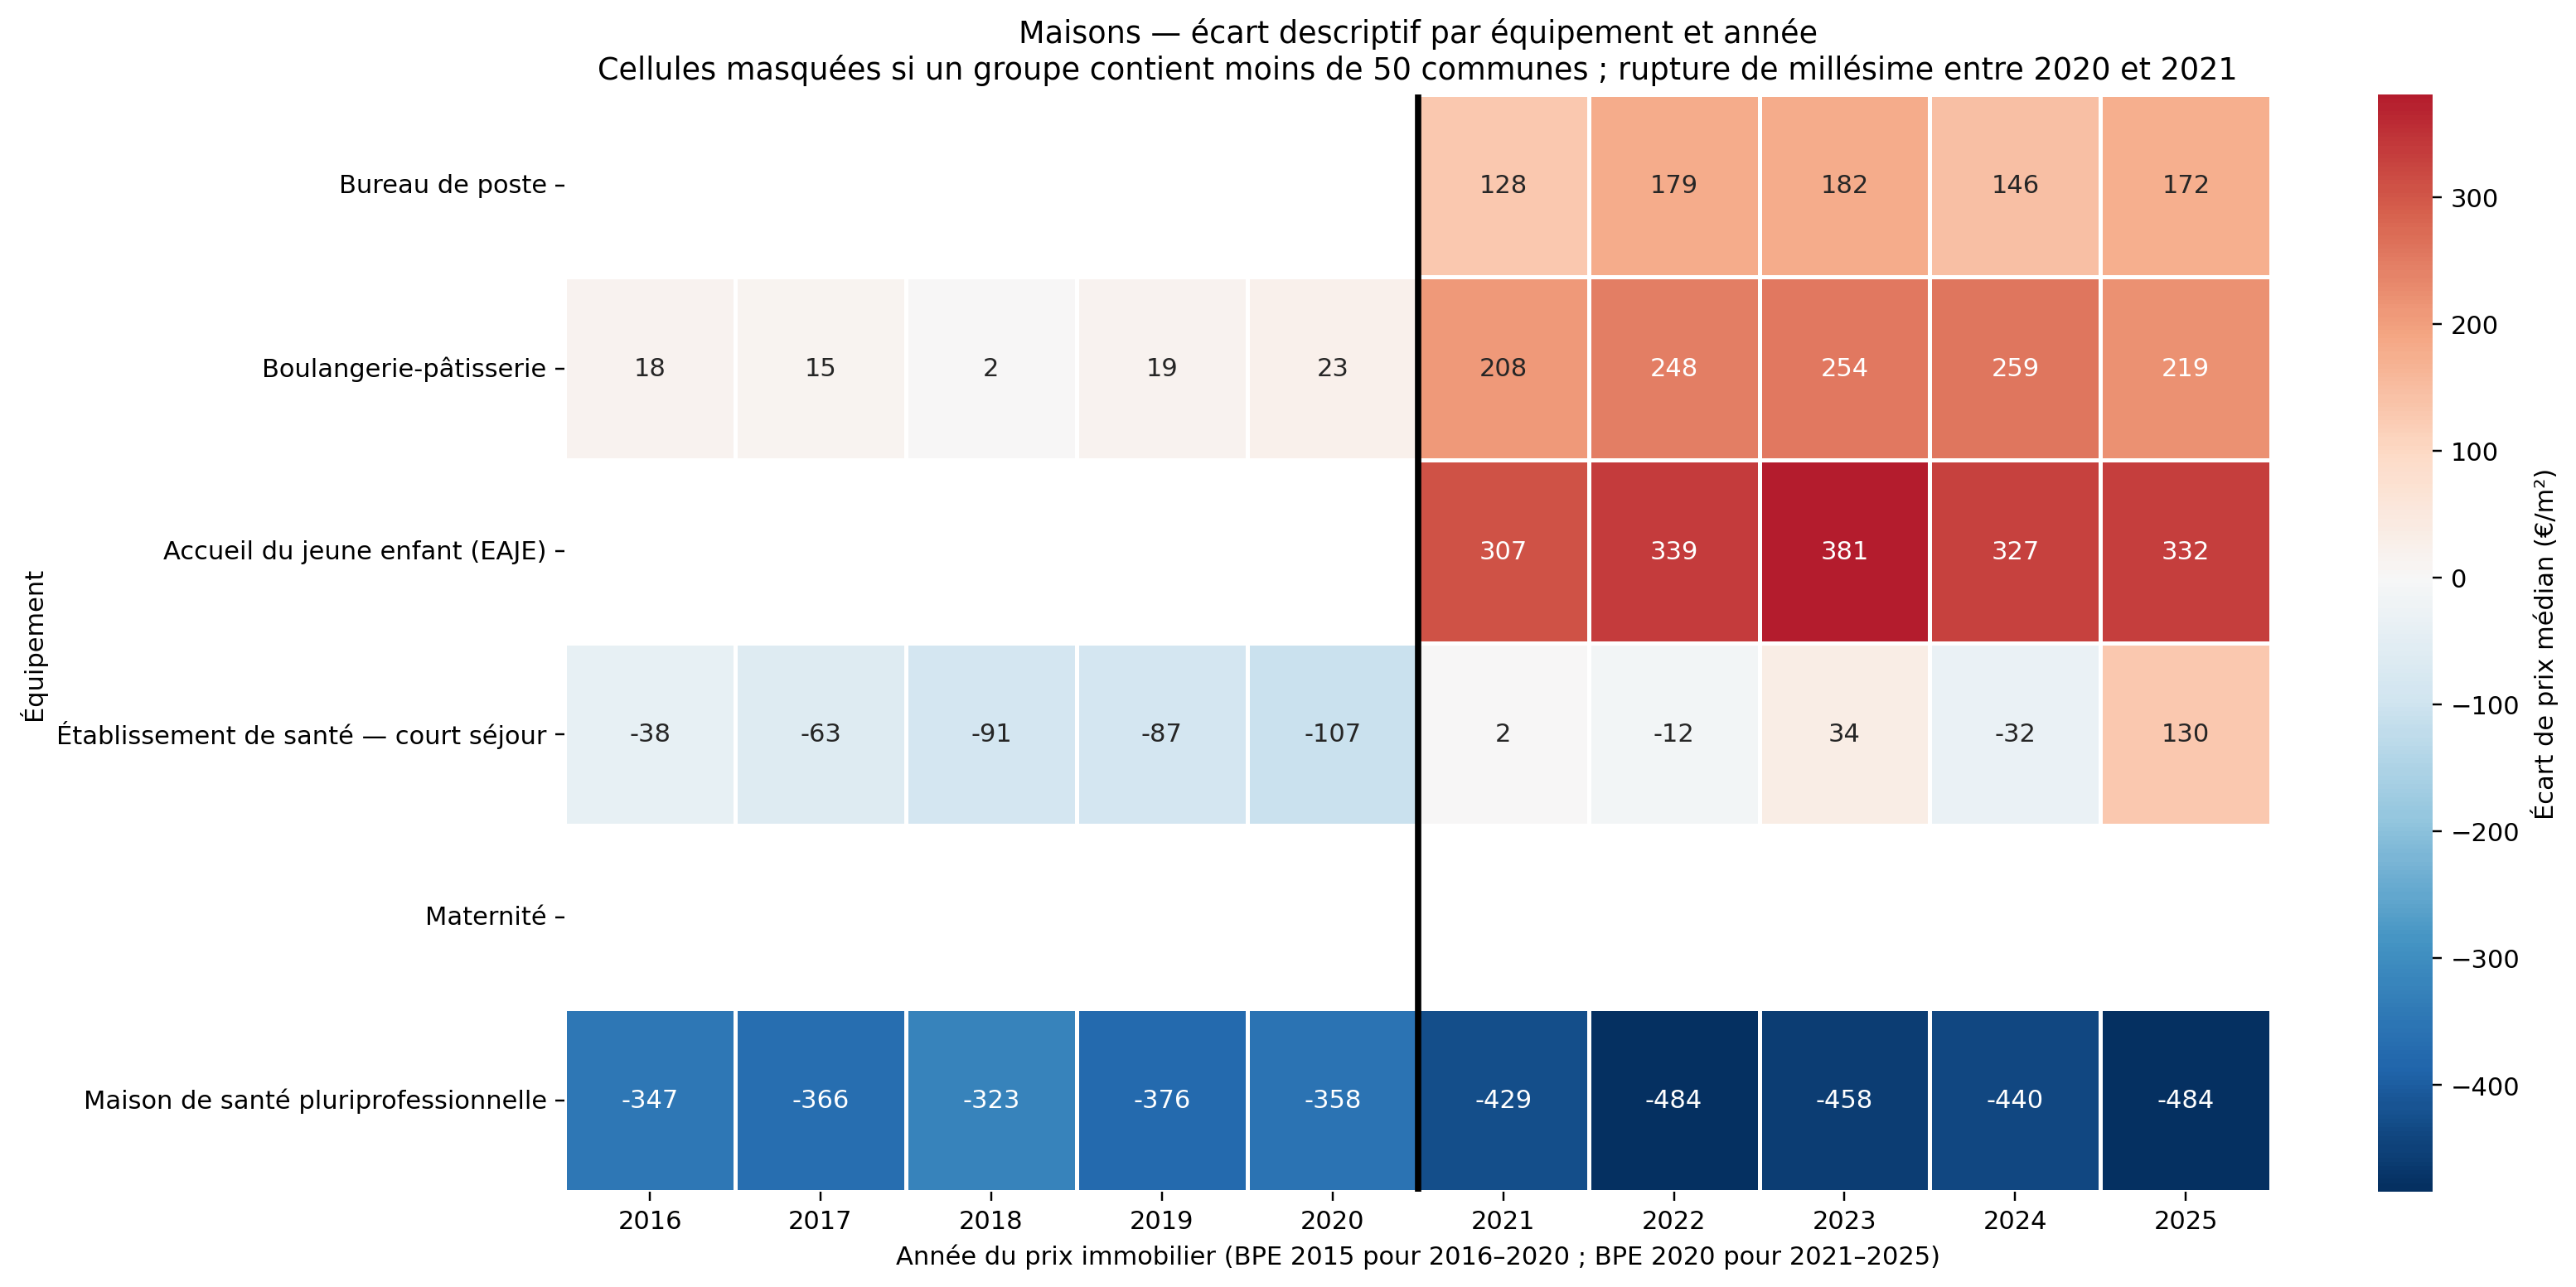

**Interprétation — Maisons**

Sur la période 2016 - 2025 , les écarts ne suivent pas une évolution uniforme selon les équipements:
-  *Boulangerie-pâtisserie* et  *bureau de poste* présentent des écarts positifs sur les années affichées à partir de 2021.

- *Accueil du jeune enfant (EAJE)* présente également des écarts positifs de 2021 à 2025, autour de +300 à +380 €/m². À l’inverse,

- *Maison de santé pluriprofessionnelle* se distingue par un écart négatif persistant, compris entre environ −320 et −485 €/m² sur la période affichée. L’écart associé aux établissements de santé de court séjour fluctue autour de zéro et ne fait pas apparaître de trajectoire stable. La maternité ne peut pas être interprétée, car les cellules sont masquées en raison des effectifs insuffisants.

**Conclusion :**

*Accueil du jeune enfant (EAJE)* est l’équipement qui présente l’association positive la plus régulière parmi les équipements interprétables depuis 2021 ; la maison de santé pluriprofessionnelle se distingue par l’association négative la plus persistante. Cela permet seulement d’affirmer que, dans les groupes de communes comparés, les prix médians des maisons sont descriptivement plus élevés avec un EAJE et plus faibles avec une maison de santé pluriprofessionnelle. Cela ne prouve pas que ces équipements causent les différences de prix.

**Prudence temporelle :**

la rupture entre 2020 et 2021 correspond aussi au changement de millésime BPE. Les différences de part et d’autre de cette frontière ne peuvent pas être interprétées comme une évolution certaine sans vérification de la comparabilité des millésimes. Les cellules blanches ne représentent pas un écart nul.


**Carte thermique — Appartements**

Carte thermique intégrée au notebook : les écarts descriptifs de prix médians au m² sont affichés ci-dessous. L’image est incorporée au fichier et ne nécessite aucun chemin externe pour être visible.

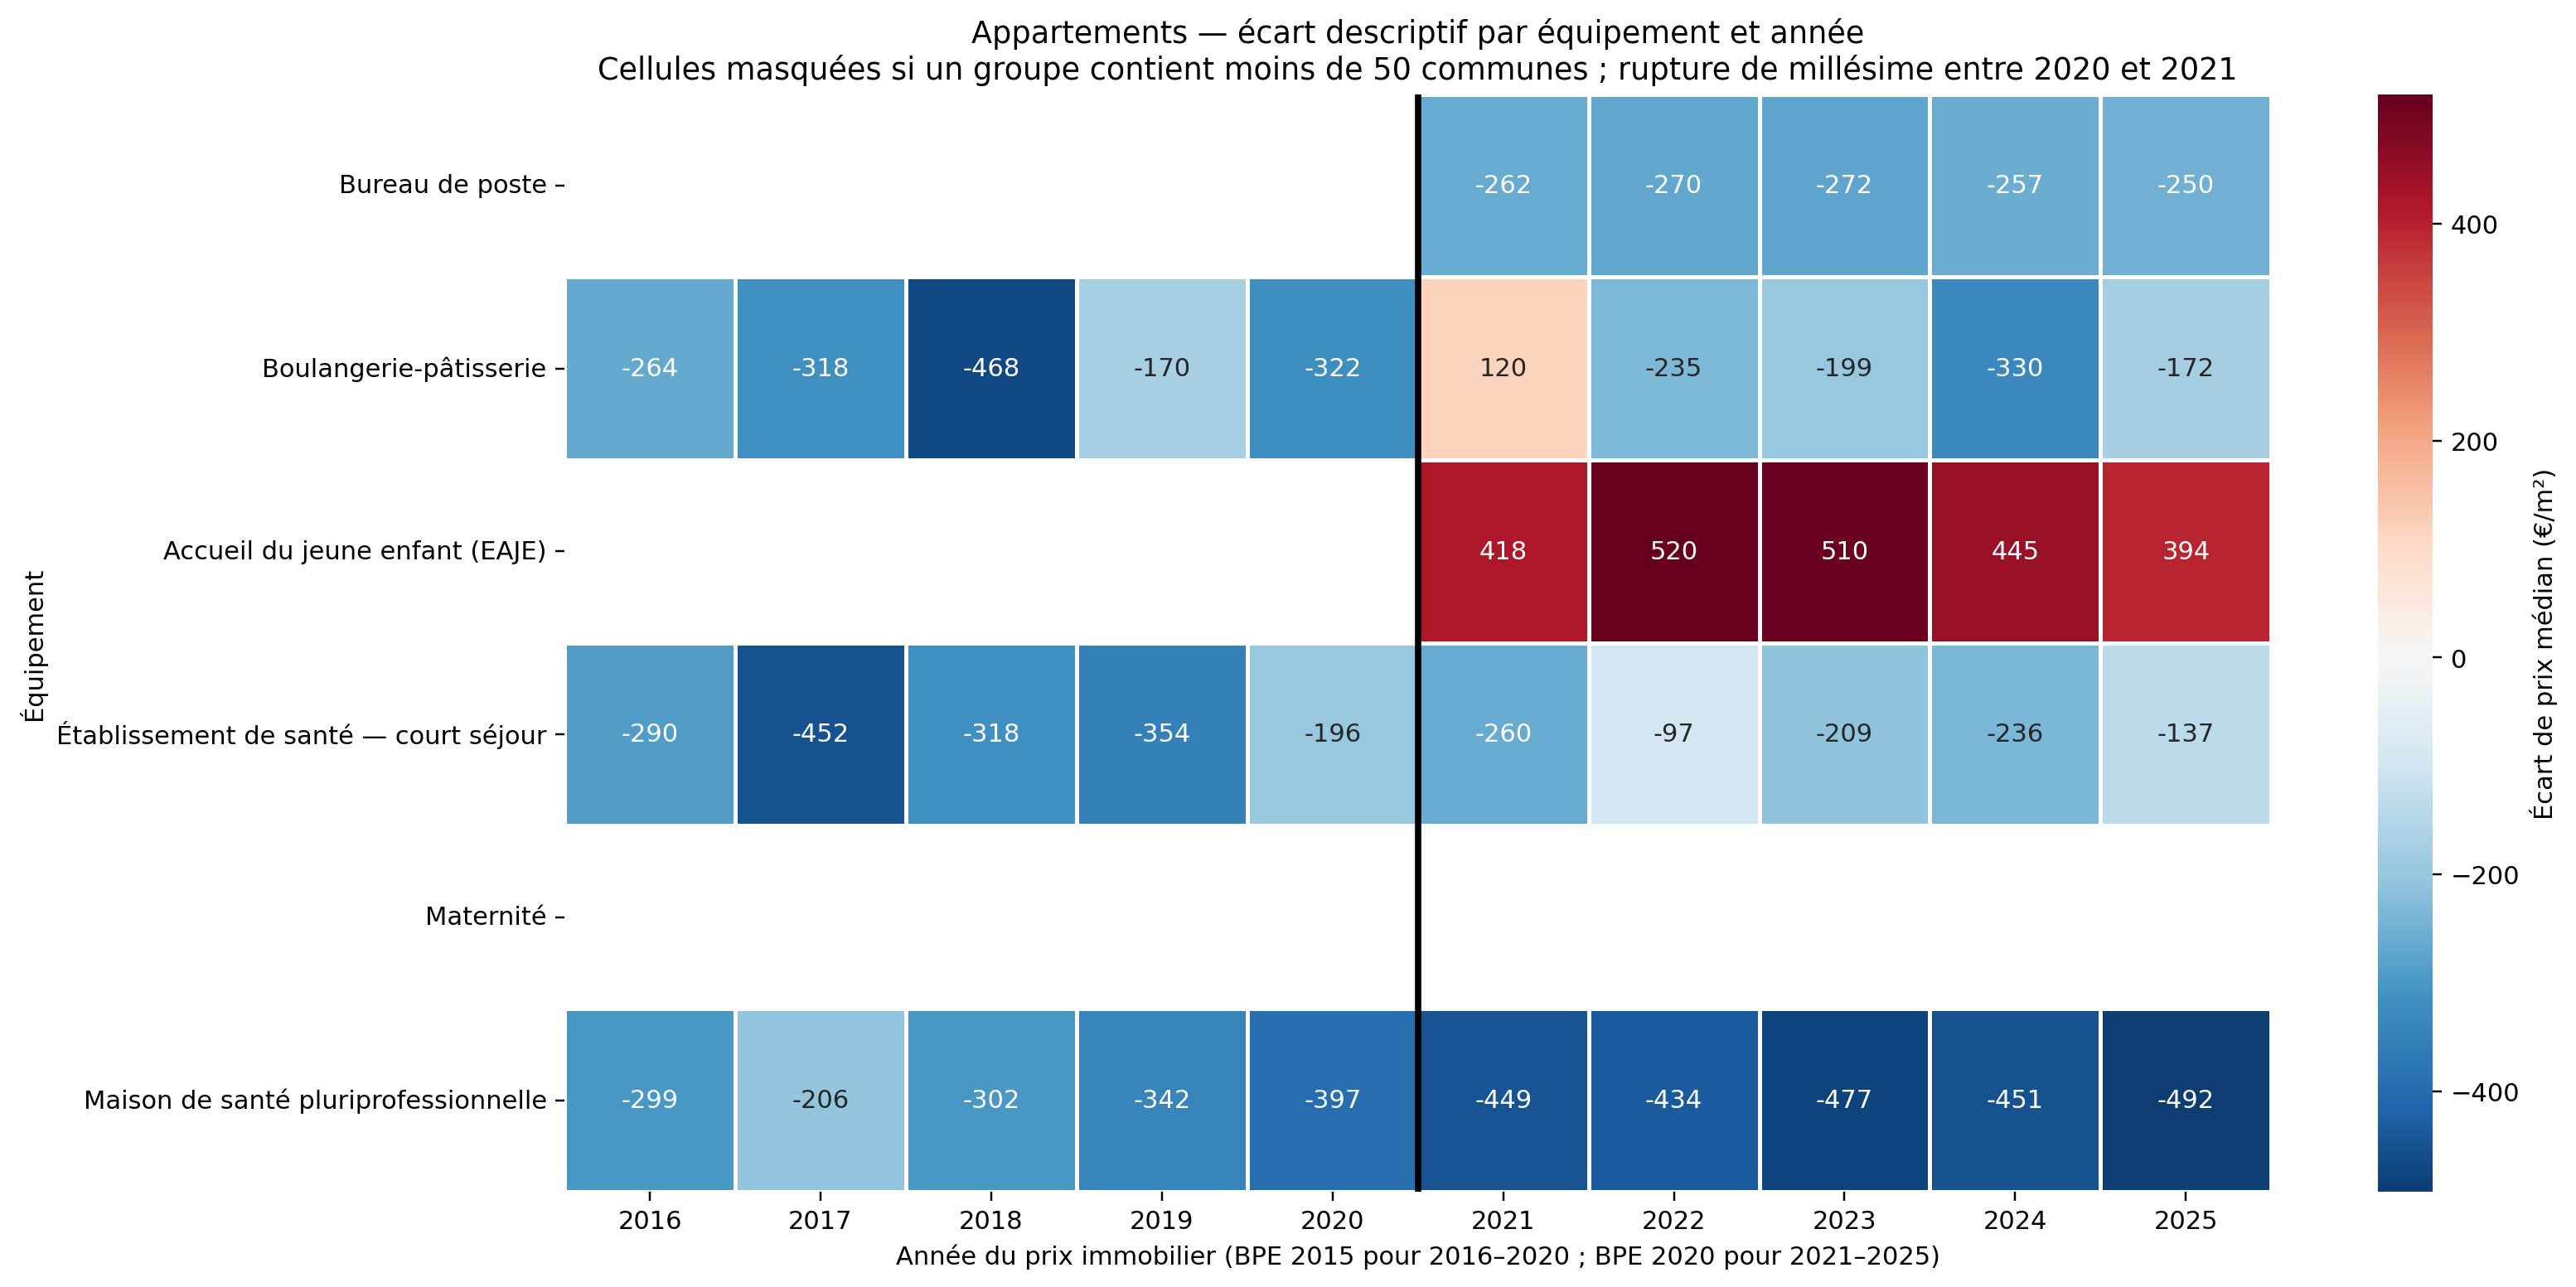

**Interprétation — Appartements**

Sur la période 2016 - 2025, les associations observées pour les appartements diffèrent parfois de celles des maisons.
- *Accueil du jeune enfant (EAJE)* présente des écarts positifs sur toutes les années affichées, de 2021 à 2025, même si l’écart diminue après son maximum de 2022.
- *Maison de santé pluriprofessionnelle* affiche, elle, un écart négatif chaque année visible de 2016 à 2025, parmi les plus marqués de la carte.
- *Bureau de poste* est associé à des écarts négatifs sur les années visibles à partir de 2021.
- *Boulangerie-pâtisserie* et les *établissements de santé de court séjour* présentent des écarts négatifs la plupart du temps, mais avec des fluctuations et sans trajectoire régulière. La maternité ne peut pas être interprétée : ses cellules sont masquées en raison des effectifs insuffisants.

**Conclusion :**

Les deux équipements qui se démarquent le plus nettement sont **l’EAJE**, associé à des prix médians plus élevés sur la période visible depuis 2021, et *la maison de santé pluriprofessionnelle*, associée à des prix médians plus faibles sur l’ensemble de la période affichée. On peut décrire ces associations dans les communes comparées, mais pas conclure que la présence de ces équipements explique à elle seule les prix observés.

**Prudence temporelle :** la rupture entre 2020 et 2021 correspond au changement de millésime BPE. Les écarts avant/après cette frontière ne sont pas directement interprétables comme une évolution réelle sans contrôle de comparabilité. Les cellules blanches ne représentent pas un écart nul.


### F. Travail sur la délinquance

**Exploration du lien de la délinquance avec la variable cible**

*Objectif :* comprendre comment les indicateurs de délinquance se rapprochent ou se distinguent, puis étudier leur lien avec le prix au m², et surtout avec son évolution.

*Maille :* une ligne par bassin de vie et par année, avec Paris, Lyon et Marseille en ville entière (option A, en attendant la décision de l’équipe).

*Période :* 2016-2024. 2025 est l’année de test et est retirée de toute l’EDA.

*Indicateurs :* 15 taux pour 1 000 habitants (pour 1 000 logements pour les cambriolages). Les communes masquées reçoivent la moyenne départementale des communes masquées.

*Cible :* prix médian au m² par bassin et par année, recalculé à partir des ventes DVF+. Une médiane ne se combine pas, il faut donc la recalculer à partir des ventes.

*Rapprochement des tables :* les 14 517 lignes bassin × année de la cible (7,6 millions de ventes) trouvent toutes un taux de délinquance, sans perte.

**Analyse des taux de délinquances entre eux**

Graphiques et analyses disponibles en annexe.

*Résultats* :
- Absence de redondance entre les taux, regroupements des 15 taux en 8 familles de même nature.
- Répartition hétérogène des familles sur le territoire.
- Evolutions hétérogènes des différentes familles de délinquance, dû potentiellement à d'autres facteurs sociaux que la délinquance elle-même.
- Stabilité des bassins de vie dépend du type de délinquance. Les informations de la base de données permettent d'avantage de cibler les lieux où il y a eu de la délinquance plutôt que leur temporalité.

**Lien entre la délinquance et la variable cible du projet**

Graphiques et analyses disponibles en annexe.

*Résultats :*
- lien faible à moyen de la délinquance avec le niveau des prix.
- lien faible avec l'évolution relative des prix, le lien est de sens négatif et va dans le sens d'un effet de réputation. Les bassins les plus touchés au départ voient leur prix progresser moins vite.

**Variables candidates à la modélisation**
| Variable envisagée | Construite à partir de | Maille | Disponible a priori ? | Justification |
|---|---|---|---|---|
| Taux de violences (ou violences intrafamiliales seules) | `nombre`, `insee_pop` | bassin de vie | Oui, avec un décalage (chiffres de l'année N arrêtés en avril N+1) | lien négatif le plus net avec le niveau et l'évolution relative des prix |
| Taux de cambriolages | `nombre`, `insee_log` | bassin de vie | Oui, avec décalage | Le plus lié au logement ; territorialisé ; lien négatif avec l'évolution relative |
| Taux de vols de véhicule | `nombre`, `insee_pop` | bassin de vie | Oui, avec décalage | profil net, masqué dans sa famille |

**Notes lors de l'introduction des variables**
- passer la base en format large (une colonne par famille ou indicateur retenu) ;
- appliquer le décalage d'un an (taux de l'année N-1 pour les prix de l'année N) ;
- exclure l'usage de stupéfiants (AFD) des calculs portant sur les années avant 2021.

### G. Travail sur le parc de logement

Le preprocessing transforme la base INSEE du parc de logements (millésime 2022), qui compte 49 276 lignes et 101 colonnes au niveau IRIS (quartier), en un fichier au niveau commune. Ce fichier est prêt à être joint aux données DVF+ pour étudier les prix au m². Le fichier d’origine reste intact tout au long du processus.

**les étapes du pre-processing**

*Suppression des colonnes inutiles.* 17 colonnes sont retirées : 10 propres à l’outre-mer, 5 sur le chauffage, ainsi que LAB_IRIS et TYP_IRIS. Les premières présentent des valeurs manquantes structurelles (98,6 % et 1,4 %). LAB_IRIS n’est pas documenté. TYP_IRIS n’a plus d’utilité une fois les données agrégées à la commune. Il reste 84 colonnes.

*Suppression des IRIS vides.* 152 IRIS sans aucun logement (zones d’activité, parcs) sont supprimés. Leurs effectifs sont tous nuls, ils n’apportent donc aucune information.

*Traitement de Paris, Lyon et Marseille.* Ces trois villes sont codées par arrondissement dans DVF+, alors que d’autres sources utilisent la commune entière. On garde donc le code par arrondissement dans COM et on crée une colonne COM_ENTIERE (75056 pour Paris, 69123 pour Lyon, 13055 pour Marseille). Les deux types de jointure restent possibles, sans perdre le détail par arrondissement. Ces villes comptent respectivement 992, 185 et 393 IRIS.

*Agrégation par commune.* DVF+ ne contient pas de code IRIS, la jointure se fait donc par commune. Les effectifs des IRIS sont additionnés par commune (ou par arrondissement) avec un groupby(...).sum(), et le nombre d’IRIS par commune est conservé. Les effectifs sont additionnés, mais on ne fait jamais la moyenne de taux. On obtient 34 955 communes et arrondissements.

*Création des indicateurs.* Les effectifs bruts dépendent de la taille de la commune et ne sont pas comparables entre eux. On calcule donc 19 indicateurs en parts (%) ou en moyennes, avec une division protégée contre les dénominateurs nuls. Ils couvrent la vacance, les résidences secondaires, les maisons et appartements, les petits et grands logements, le nombre de pièces, l’âge du parc, les propriétaires, les locataires, les HLM, la mobilité résidentielle, la taille des ménages, l’équipement en voiture et en parking, et la suroccupation.

*Ajout de colonnes d’aide.* Cinq colonnes sont ajoutées : le département, un signalement des communes d’Alsace-Moselle (absentes de DVF+, leur exclusion sera décidée à la jointure), un signalement des petites communes de moins de 50 logements (dont les taux sont fragiles), la taille de la commune en logarithme (la distribution est très asymétrique) et le millésime 2022.

### H. Travail sur les logements vacants (LOVAC)

Le preprocessing transforme la feuille communale du fichier LOVAC (logements privés vacants, Cerema, millésimes 2020 à 2026) en une table au format long, avec une ligne par commune et par millésime. Cette table est prête à être jointe aux ventes DVF+ année par année. LOVAC est une source administrative exhaustive qui ne contient aucun prix : c’est une variable explicative annuelle, ce qui permet de respecter la règle « on n’utilise que l’information de l’année précédant la vente ».

**les étapes du pre-processing**
*Traitement du secret statistique.* Dans les colonnes de chiffres (celles qui commencent par pp_ ou ff_), chaque « s » devient une valeur manquante, puis les colonnes sont converties en nombres. Un « s » signifie « valeur cachée » et non zéro. Cela produit 310 532 valeurs manquantes.

*Passage du format large au format long.* Dans le fichier d’origine, chaque millésime a ses propres colonnes (pp_vacant_20, pp_vacant_21, etc.). On empile les 7 millésimes pour obtenir une ligne par commune et par millésime, avec le nombre de logements vacants, ceux vacants depuis plus de 2 ans et le parc privé total. Pour le millésime 2026, le parc privé n’existe pas et reste manquant. On obtient 244 384 lignes (34 912 × 7). Ce format est indispensable pour joindre avec les ventes par année.

*Gestion des dates.* Le millésime N décrit la situation au 1er janvier N-1. On ajoute donc l’année de situation (N-1) et l’année de vente associée (N). Pour une vente de l’année N, on utilisera le millésime N, publié en milieu d’année. Cela évite les confusions de dates et les fuites de données.

*Création des indicateurs.* Les effectifs bruts dépendent de la taille de la commune. On calcule trois indicateurs, avec une division protégée contre les dénominateurs nuls :

- le taux de vacance du parc privé ;
- le taux de vacance de plus de 2 ans (vacance « structurelle ») ;
- la part de la vacance longue parmi les logements vacants, qui ne dépend pas du parc total.

*Ajout de colonnes d’aide.*

- Un signalement de la rupture de série : la fin de la taxe d’habitation en 2023 a changé la collecte (dispositif GMBI), et les millésimes 2024 et suivants ne sont pas directement comparables aux précédents.
- Le département, avec un signalement de l’Alsace-Moselle (absente de DVF+) et de Mayotte (absente de DVF).
- Le code EPCI (intercommunalité), utile à l’étape suivante.
- La colonne COM_ENTIERE pour Paris, Lyon et Marseille (75056, 69123, 13055), afin de pouvoir joindre avec des sources codées sans arrondissements, comme la table des bassins de vie.

*Complétion des taux cachés.* Le parc privé est sous secret pour environ 53 % des communes, surtout les petites, dont le taux de vacance reste donc inconnu. Pour ne pas perdre les communes rurales, on calcule le taux de leur EPCI (somme des vacants et du parc des communes connues) et on l’utilise à leur place. Une colonne taux_impute signale les valeurs remplacées, et taux_vacance_complete contient le taux final.

*Les deux enjeux propres à LOVAC sont le secret statistique* (« s » traité comme manquant et non comme zéro, puis complété par le taux de l’EPCI avec un drapeau) et *la rupture de série de 2023*, signalée plutôt que corrigée. Comme pour le fichier logement, les cas particuliers (Alsace-Moselle, Mayotte, arrondissements) sont marqués et non supprimés.

*Deux points demandent de la prudence pour la suite :*

Le taux complété par l’EPCI est une approximation : il lisse les différences entre communes d’une même intercommunalité. Il faut donc garder taux_impute comme variable de contrôle.
Le taux de vacance du millésime 2026 reste vide, car le parc privé n’existe pas pour cette année. Il ne peut être complété ni par la commune ni par l’EPCI. Le notebook ne traite pas explicitement ce cas.

### I. Feature selection à partir des données de logements et LOVAC

**Démarche**
| Partie | Action | Fichier créé ? |
|---|---|---|
| 1. Merge temporaire | Table cible + base logement + LOVAC | Non (en mémoire) |
| 2. Sélection | Séparation train (2014-2024) / test (2025), puis analyse **sur train uniquement** | Non (en mémoire) |
| 3. Fichiers allégés | On repart des fichiers d'origine et on retire les variables écartées | Oui : 2 nouveaux fichiers |

**Méthode de sélection**
- *Cibles* : log du prix médian au m², maisons et appartements séparément, seulement si la commune a au moins 5 ventes dans l'année (une médiane sur 1 ou 2 ventes n'est pas fiable). Cela donne 195 568 lignes pour les maisons et 35 958 pour les appartements.
- *Lien avec le prix* : corrélation de Spearman, choisie parce que la relation n'est pas forcément linéaire et que ce coefficient est peu sensible aux valeurs extrêmes.
- *Vérification* : même calcul sur 2024 seule (une ligne par commune). Les résultats sont presque identiques : la répétition des communes sur plusieurs années ne fausse pas les coefficients.
- *Règle* : on garde une variable si |ρ| > 0,2 pour les maisons ou pour les appartements.
- *Doublons* : si deux variables sont corrélées à plus de 0,8 entre elles, on n'en garde qu'une.

**Résultats**
| Variable | Source | ρ maisons | ρ apparts | % manquants | Décision |
|---|---|---|---|---|---|
| taux_vacance_2ans | LOVAC | -0,69 | -0,59 | 85,4 | À tester |
| part_longue_parmi_vacants | LOVAC | -0,68 | -0,60 | 82,1 | Écartée (doublon de taux_vacance_2ans, 0,88) |
| part_avant1946 | Recensement | -0,61 | -0,35 | 0 | Gardée |
| taux_vacance | Recensement | -0,50 | -0,48 | 0 | Gardée |
| taux_vacance_complete | LOVAC | -0,46 | -0,34 | 54,5 | Gardée |
| anciennete_moyenne | Recensement | -0,45 | -0,15 | 0 | Gardée |
| part_2006_2019 | Recensement | 0,42 | 0,30 | 0 | Gardée |
| part_apparts | Recensement | 0,40 | 0,14 | 0 | Gardée |
| part_maisons | Recensement | -0,39 | -0,14 | 0 | Écartée (doublon de part_apparts, -0,96) |
| log_nb_logements | Recensement | 0,38 | 0,10 | 0 | Gardée |
| part_parking | Recensement | 0,24 | 0,32 | 0 | Gardée |
| taille_menage | Recensement | 0,30 | 0,24 | 0 | Gardée |
| part_rsec | Recensement | -0,25 | 0,16 | 0 | Gardée |
| part_suroccupes | Recensement | 0,24 | 0,23 | 0 | Gardée |
| part_sans_voiture | Recensement | -0,17 | -0,23 | 0 | Gardée |
| part_moins40m2 | Recensement | 0,20 | 0,21 | 0 | Gardée |
| part_locataires | Recensement | 0,16 | -0,20 | 0 | Écartée (lien faible) |
| part_hlm | Recensement | 0,17 | -0,16 | 0 | Écartée (lien faible) |
| part_emmenages_2ans | Recensement | 0,17 | -0,13 | 0 | Écartée (lien faible) |
| part_proprio | Recensement | -0,15 | 0,17 | 0 | Écartée (lien faible, doublon de part_locataires) |
| part_2voitures | Recensement | 0,16 | 0,17 | 0 | Écartée (lien faible) |
| nb_pieces_moyen | Recensement | -0,12 | -0,07 | 0 | Écartée (lien faible) |
| part_100m2_plus | Recensement | 0,01 | 0,10 | 0 | Écartée (lien faible) |

Les 54,5 % de manquants de `taux_vacance_complete` correspondent aux années 2014 à 2019, où LOVAC n'existe pas. La variable est complète de 2020 à 2025.

**Bilan : 12 variables du recensement gardées, 1 de LOVAC gardée, 1 de LOVAC à tester, 9 écartées.**

**Constat**
Les variables les plus liées au prix décrivent l'**attractivité du marché local** :
- un parc ancien, une vacance élevée et des habitants installés depuis longtemps vont avec des prix plus bas ;
- des constructions récentes et des communes plus grandes vont avec des prix plus élevés.

Les liens sont plus forts pour les maisons que pour les appartements.

**Impact projet**
- Les variables LOVAC sont parmi les plus liées au prix, mais elles sont vides de 2014 à 2019 et complètes en 2025 : l'entraînement et le test n'ont pas la même couverture LOVAC.
- `taux_vacance_2ans` n'est connue que pour environ un tiers des communes, surtout les plus grandes (secret statistique). Son lien fort est mesuré sur un sous-ensemble qui n'est pas représentatif.

**Incertitudes**
- Spearman ne détecte que les liens qui vont toujours dans le même sens. Une variable écartée pourrait quand même être utile à un modèle à arbres ; à vérifier avec l'importance des variables.
- Le seuil de 0,2 est un choix : `part_locataires` (0,20) est écartée de justesse.
- `part_rsec` a un effet opposé pour les maisons (-) et les appartements (+), sans doute à cause des stations touristiques où les appartements sont chers. À interpréter avec prudence.
- Le recensement 2022 est utilisé pour toutes les années, y compris pour les ventes de 2014 à 2021.

## 4. Dataset final

## ANNEXES

### Annexe n°1 : DVF dictionnaire des variables par type

**Variables de type str (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Type statistique |
|---|---|---|---|
| `idmutinvar` | Identifiant invariant de la mutation | `str` | Identifiant |
| `idopendata` | Identifiant de la mutation dans les données ouvertes | `str` | Identifiant |
| `datemut` | Date de la mutation | `str` | Temporelle |
| `coddep` | Code du département | `str` | Qualitative nominale |
| `libnatmut` | Libellé de la nature de la mutation (vente, échange, VEFA, etc.) | `str` | Qualitative nominale |
| `l_codinsee` | Liste des codes INSEE des communes concernées | `str` | Liste de codes géographiques |
| `l_section` | Liste des sections cadastrales concernées | `str` | Liste de références cadastrales |
| `l_idpar` | Liste des identifiants des parcelles concernées | `str` | Liste d'identifiants |
| `l_idparmut` | Liste des identifiants des parcelles ayant muté | `str` | Liste d'identifiants |
| `l_dcnt` | Liste des surfaces de terrain ayant muté, par catégorie d'occupation du sol | `str` | Liste de valeurs quantitatives |
| `l_idlocmut` | Liste des identifiants des locaux ayant muté | `str` | Liste d'identifiants |
| `libtypbien` | Libellé du type de biens concernés par la mutation | `str` | Qualitative nominale |
| `departement_source` | Département du fichier source utilisé pour l'échantillonnage | `str` | Qualitative nominale |

**Variable de type bolléenne (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Type statistique |
|---|---|---|---|
| `vefa` | Vente en l'état futur d'achèvement (vente sur plan). Indique si la mutation concerne une VEFA (`True`) ou non (`False`). | `bool` | Qualitative nominale binaire |

**Variables numériques (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Nature statistique |
|---|---|---|---|
| `idmutation` | Identifiant unique de la mutation | `int64` | Identifiant |
| `idnatmut` | Code de la nature de mutation | `int64` | Qualitative nominale codée |
| `codservch` | Code du service chargé de l'enregistrement | `float64` | Qualitative nominale codée |
| `refdoc` | Référence du document fiscal | `float64` | Identifiant / référence |
| `anneemut` | Année de la mutation | `int64` | Temporelle discrète |
| `moismut` | Mois de la mutation (1 à 12) | `int64` | Temporelle discrète |
| `nbartcgi` | Nombre d'articles du Code général des impôts associés à la mutation | `int64` | Quantitative discrète |
| `l_artcgi` | Liste des articles du Code général des impôts associés à la mutation | `float64` | Liste de codes (non numérique au sens statistique) |
| `valeurfonc` | Valeur foncière totale de la mutation, en euros | `float64` | Quantitative continue |
| `nbdispo` | Nombre de dispositions associées à la mutation | `int64` | Quantitative discrète |
| `nblot` | Nombre de lots concernés par la mutation | `float64` | Quantitative discrète |
| `nbcomm` | Nombre de communes concernées | `int64` | Quantitative discrète |
| `nbsection` | Nombre de sections cadastrales concernées | `int64` | Quantitative discrète |
| `nbpar` | Nombre de parcelles concernées | `int64` | Quantitative discrète |
| `nbparmut` | Nombre de parcelles ayant effectivement muté | `int64` | Quantitative discrète |
| `nbsuf` | Nombre de subdivisions fiscales concernées | `int64` | Quantitative discrète |
| `sterr` | Surface totale de terrain associée à la mutation, en m² | `float64` | Quantitative continue |
| `nbvolmut` | Nombre de volumes immobiliers ayant muté | `int64` | Quantitative discrète |
| `nblocmut` | Nombre de locaux ayant muté | `int64` | Quantitative discrète |
| `nblocmai` | Nombre de maisons concernées | `int64` | Quantitative discrète |
| `nblocapt` | Nombre d'appartements concernés | `int64` | Quantitative discrète |
| `nblocdep` | Nombre de dépendances concernées | `int64` | Quantitative discrète |
| `nblocact` | Nombre de locaux d'activité concernés | `int64` | Quantitative discrète |
| `nbapt1pp` | Nombre d'appartements de 1 pièce principale | `int64` | Quantitative discrète |
| `nbapt2pp` | Nombre d'appartements de 2 pièces principales | `int64` | Quantitative discrète |
| `nbapt3pp` | Nombre d'appartements de 3 pièces principales | `int64` | Quantitative discrète |
| `nbapt4pp` | Nombre d'appartements de 4 pièces principales | `int64` | Quantitative discrète |
| `nbapt5pp` | Nombre d'appartements de 5 pièces principales ou plus | `int64` | Quantitative discrète |
| `nbmai1pp` | Nombre de maisons de 1 pièce principale | `int64` | Quantitative discrète |
| `nbmai2pp` | Nombre de maisons de 2 pièces principales | `int64` | Quantitative discrète |
| `nbmai3pp` | Nombre de maisons de 3 pièces principales | `int64` | Quantitative discrète |
| `nbmai4pp` | Nombre de maisons de 4 pièces principales | `int64` | Quantitative discrète |
| `nbmai5pp` | Nombre de maisons de 5 pièces principales ou plus | `int64` | Quantitative discrète |
| `sbati` | Surface bâtie totale associée à la mutation, en m² | `float64` | Quantitative continue |
| `sbatmai` | Surface bâtie totale des maisons, en m² | `float64` | Quantitative continue |
| `sbatapt` | Surface bâtie totale des appartements, en m² | `float64` | Quantitative continue |
| `sbatact` | Surface bâtie totale des locaux d'activité, en m² | `float64` | Quantitative continue |
| `sapt1pp` | Surface totale des appartements de 1 pièce principale, en m² | `float64` | Quantitative continue |
| `sapt2pp` | Surface totale des appartements de 2 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt3pp` | Surface totale des appartements de 3 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt4pp` | Surface totale des appartements de 4 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt5pp` | Surface totale des appartements de 5 pièces principales ou plus, en m² | `float64` | Quantitative continue |
| `smai1pp` | Surface totale des maisons de 1 pièce principale, en m² | `float64` | Quantitative continue |
| `smai2pp` | Surface totale des maisons de 2 pièces principales, en m² | `float64` | Quantitative continue |
| `smai3pp` | Surface totale des maisons de 3 pièces principales, en m² | `float64` | Quantitative continue |
| `smai4pp` | Surface totale des maisons de 4 pièces principales, en m² | `float64` | Quantitative continue |
| `smai5pp` | Surface totale des maisons de 5 pièces principales ou plus, en m² | `float64` | Quantitative continue |
| `codtypbien` | Code de la typologie des biens concernés par la mutation | `int64` | Qualitative nominale codée |
| `geompar_x` | Coordonnée X de localisation géographique de la mutation | `float64` | Coordonnée géographique |
| `geompar_y` | Coordonnée Y de localisation géographique de la mutation | `float64` | Coordonnée géographique |


### Annexe n°2 : DVF, distribution des valeurs extrêmes

**Variables catégorielles**
![](<pieces_jointes/dvf audit val extr var catego.png>)

**Variables quantitatives discrètes**
![alt text](<pieces_jointes/dvf audit val extr var quantitatives discrètes.png>)

**Variables quantitatives continues**
![alt text](<pieces_jointes/dvf audit val extr var quantitatives continues.png>)

![alt text](<pieces_jointes/dvf audit val extr var quantitatives continues2.png>)

### Annexe n°3: Annonces de ventes immobilières dans le 68, détail des variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| type_annonceur | Type d'annonceur (pr = professionnel) | qualitative nominale | pr | object : cohérent, mais constante |
| typedebien | Type de bien (a, m, an, mn, l) | qualitative nominale | a / m / an / mn / l | object : cohérent |
| typedetransaction | Type de transaction (v = vente) | qualitative nominale | v / vp / pi | object : cohérent |
| etage | Étage du logement | quantitative discrète | étage ; de -1 à 999 | int64 : cohérent, mais 999 = valeur sentinelle à passer en NaN |
| surface | Surface habitable | quantitative continue | m² ; de 2 à 980 | int64 : cohérent |
| surface_terrain | Surface du terrain | quantitative continue | m² ; de 1 à 431 600 | float64 : cohérent |
| nb_pieces | Nombre de pièces | quantitative discrète | pièces ; de 1 à 43 | int64 : cohérent |
| prix_bien | Prix affiché (cible) | quantitative continue | € ; de 1 076 à 3 380 000 | int64 : cohérent |
| prix_maison | Prix de la maison (offre terrain + maison) | quantitative continue | € ; de 86 000 à 514 999 | float64 : cohérent |
| prix_terrain | Prix du terrain (offre terrain + maison) | quantitative continue | € ; de 1 à 320 000 | float64 : cohérent |
| mensualiteFinance | Mensualité de crédit indicative | quantitative continue | €/mois ; de 0 à 7 715 | int64 : cohérent, mais 0 = non renseigné |
| balcon | Nombre de balcons | quantitative discrète | balcons ; de 0 à 8 | int64 : cohérent |
| eau | Nombre de salles d'eau | quantitative discrète | pièces ; de 0 à 10 | int64 : cohérent |
| bain | Nombre de salles de bain | quantitative discrète | pièces ; de 0 à 12 | int64 : cohérent |
| dpeL | Étiquette énergie du DPE | qualitative ordinale | A à G ; 10 modalités (+ 0, NS, VI) | object : à convertir en catégorie ordonnée ; « 0 » = NA caché |
| dpeC | Consommation d'énergie du DPE | quantitative continue | kWh/m²/an ; de 0 à 988 | float64 : cohérent |
| mapCoordonneesLatitude | Latitude | quantitative continue | degrés ; de 47.43 à 48.3 | float64 : cohérent |
| mapCoordonneesLongitude | Longitude | quantitative continue | degrés ; de 6.86 à 7.62 | float64 : cohérent |
| annonce_exclusive | Mandat exclusif | qualitative binaire | Non / 0 / Oui | object : à convertir en booléen ; « 0 » = NA caché |
| nb_etages | Nombre d'étages du bâtiment | quantitative discrète | étages ; de 0 à 36 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| parking | Présence d'un parking | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| places_parking | Nombre de places de parking | quantitative discrète | places ; de 0 à 35 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| cave | Présence d'une cave | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| exposition | Orientation du logement | qualitative nominale | 35 modalités | object : cohérent, mais « 0 » = NA caché et casse non homogène |
| ges_class | Classe d'émission de GES du DPE | qualitative ordinale | A à G ; 9 modalités (+ NS, VI) | object : à convertir en catégorie ordonnée |
| annee_construction | Année de construction | temporelle | année ; de 971 à 2025 | float64 : cohérent (float à cause des NaN), mais valeurs < 1700 aberrantes |
| nb_toilettes | Nombre de WC | quantitative discrète | WC ; de 0 à 15 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| nb_terraces | Nombre de terrasses | quantitative discrète | terrasses ; de 0 à 14 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| videophone | Présence d'un vidéophone | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| porte_digicode | Présence d'un digicode | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| surface_balcon | Surface du balcon | quantitative continue | m² ; de 1 à 801 | float64 : cohérent |
| ascenseur | Présence d'un ascenseur | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| nb_logements_copro | Nombre de lots de la copropriété | quantitative discrète | lots ; de 0 à 3 442 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| charges_copro | Charges annuelles de copropriété | quantitative continue | €/an ; de 0 à 2 577 352 | float64 : cohérent |
| chauffage_energie | Énergie de chauffage | qualitative nominale | 10 modalités | object : cohérent mais plusieurs valeurs dans un même champ (« Gaz, Bois ») |
| chauffage_systeme | Système de chauffage | qualitative nominale | 13 modalités | object : cohérent mais plusieurs valeurs dans un même champ |
| chauffage_mode | Mode de chauffage | qualitative nominale | Individuel / Collectif / Central + combinaisons | object : cohérent, plusieurs valeurs dans un même champ |
| categorie_annonceur | Catégorie d'annonceur (codes non documentés) | qualitative nominale | a / network / cm / m / ca / b | object : cohérent |
| logement_neuf | Logement neuf (o / n) | qualitative binaire | n / o | object : à convertir en booléen (0 / 1) |
| duree_int | Durée de mise en ligne (hypothèse) | quantitative discrète | jours ? ; de -1125 à 793 | float64 : type cohérent, mais valeurs négatives impossibles |
| typedebien_lite | Type de bien simplifié (a, m, l) | qualitative nominale | a / m / l | object : cohérent |
| date | Mois de publication | temporelle | AAAA-MM ; 51 modalités | object : incohérent, date stockée en texte → pd.to_datetime |
| INSEE_COM | Code commune INSEE | qualitative nominale | code ; 366 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| IRIS | Numéro d'IRIS dans la commune | qualitative nominale | code ; 56 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| CODE_IRIS | Code IRIS complet | qualitative nominale | code ; 495 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| TYP_IRIS_x | Type d'IRIS (H, Z, D) | qualitative nominale | Z / H / D | object : cohérent |
| TYP_IRIS_y | Type d'IRIS (doublon de jointure) | qualitative nominale | Z / H | object : cohérent, mais doublon de TYP_IRIS_x |
| GRD_QUART | Code grand quartier INSEE | qualitative nominale | code ; 366 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| UU2010 | Code unité urbaine 2010 | qualitative nominale | code ; 39 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| REG | Code région | qualitative nominale | code ; 44 | int64 : incohérent, code stocké en nombre ; constante |
| DEP | Code département | qualitative nominale | code ; 68 | int64 : incohérent, code stocké en nombre ; constante |
| loyer_m2_median_n6 | Loyer médian local, niveau n6 | quantitative continue | €/m²/mois ; de 3.08 à 23.73 | float64 : cohérent |
| nb_log_n6 | Nb d'annonces pour la médiane n6 | quantitative discrète | annonces ; de 1 à 212 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| taux_rendement_n6 | Rendement locatif brut, niveau n6 | quantitative continue | ratio ; de 0 à 10.5 | float64 : cohérent |
| loyer_m2_median_n7 | Loyer médian local, niveau n7 | quantitative continue | €/m²/mois ; de 4.78 à 23.73 | float64 : cohérent |
| nb_log_n7 | Nb d'annonces pour la médiane n7 | quantitative discrète | annonces ; de 1 à 960 | float64 : cohérent (float à cause des NaN, valeurs entières) |
| taux_rendement_n7 | Rendement locatif brut, niveau n7 | quantitative continue | ratio ; de 0 à 10.77 | float64 : cohérent |
| prix_m2_vente | Prix au m² (prix / surface) | quantitative continue | €/m² ; de 15.59 à 79 500 | float64 : cohérent |

### Annexe n°4 : Annonces de ventes immobilières dans le 68, périmètre réel des données disponibles.

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets / groupes | Annonces de vente : maisons et appartements, anciens et neufs | Maisons 13 938 (50,3 %), appartements 13 798 (49,7 %), 1 « autre » ; neuf 13,0 %, ancien 84,3 %, inconnu 2,7 % | Équilibre maisons / appartements. Le neuf est une petite sous-population : peu d'exemples pour le modèle |
| Temps, si pertinent | Février 2019 → avril 2023, 51 mois, aucun mois manquant | 2019 : 722 · 2020 : 6 610 · 2021 : 7 041 · 2022 : 9 399 · 2023 (4 mois) : 3 965 | 2019 très peu fourni  (18 à 150 annonces par mois) et composé à 81 % d'appartements, contre ~50 % ensuite. Pic de 1 383 annonces en janvier 2020 . Creux d'avril 2020 (105) : premier confinement |
| Géographie, si pertinente | Haut-Rhin (68) uniquement | 1 seul département ; 366 communes présentes, soit toutes les communes du département ; 20,4 % des annonces en commune rurale | Modèle non généralisable hors Haut-Rhin. 29 communes ont 5 annonces ou moins : estimations locales fragiles |
| Autre dimension | Annonceurs | 100 % professionnels (`pr`) ; 76 % catégorie `a` | Aucune vente entre particuliers : le périmètre réel est « le marché des agences », pas tout le marché |

### Annexe n°5: Annonces de ventes immobilières dans le 68, valeurs manquantes

| Variable | Nombre / proportion | Codes d'absence possibles | Sens / structure observée |
|---|---|---|---|
| parking, videophone | 27 710 (99,9 %) / 27 602 (99,5 %) | NaN | Champs quasi jamais remplis : information non collectée par la source. Inexploitables |
| prix_maison, prix_terrain | 27 300 (98,4 %) chacun | NaN ; prix_terrain = 1 € (41 lignes) | Non applicable : ne concernent que les offres « terrain + maison » neuves (mn). Le 1 € est une valeur de remplissage |
| surface_balcon, nb_terraces | 97,6 % / 85,2 % | NaN | Probablement « pas de balcon / terrasse » plutôt qu'inconnu, mais non vérifiable |
| exposition | 0 NaN, mais 21 392 « 0 » (77,1 %) | « 0 » | NA caché : le « 0 » signifie « non renseigné » |
| charges_copro, nb_logements_copro | 75,9 % / 72,7 % | NaN ; 0 (220 et 78 lignes) | Non applicable pour les maisons (98-99 % de NaN) ; pour les appartements, ~50 % de NaN = inconnu. Les deux colonnes sont souvent vides ensemble |
| ascenseur | 68,5 % | NaN | Non applicable pour les maisons (100 % de NaN) ; 37 % inconnu pour les appartements |
| annee_construction | 65,9 % | NaN ; années < 1700 (59 lignes) | Inconnu. 100 % vide en 2019, 91 % vide pour le neuf, très variable selon l'annonceur |
| surface_terrain | 58,7 % | NaN | Non applicable pour les appartements (97 % de NaN) ; 21 % inconnu pour les maisons |
| chauffage_energie / mode / systeme | 54,7 % / 50,9 % / 72,5 % | NaN | Inconnu ; les trois colonnes sont souvent vides ensemble (11 326 lignes) : bloc « chauffage » non saisi |
| cave | 52,2 % | NaN | Ambigu : « pas de cave » ou « non précisé » ? Le taux varie de 12 % à 100 % selon l'annonceur |
| nb_etages, nb_toilettes | 46,4 % / 44,3 % | NaN | Inconnu, répartition proche entre maisons et appartements |
| dpeC | 38,2 % | NaN ; 0 (92 lignes) | Lié à l'étiquette : manque presque toujours quand dpeL = 0, NS ou VI. Vide à 99,5 % pour le neuf |
| dpeL | 0 NaN, mais 4 766 « 0 » (17,2 %) ; 4 059 NS / VI (14,6 %) | « 0 », « NS », « VI » | NA caché (« 0 ») et cas non applicables (NS = non soumis, VI = diagnostic vierge). « 0 » : 78 % en 2019, ~12 % ensuite |
| annonce_exclusive | 0 NaN, mais 4 717 « 0 » (17,0 %) | « 0 » | NA caché |
| loyer_m2_median_n6, nb_log_n6, taux_rendement_n6 | 10 252 (37,0 %) | NaN | Toujours vides ensemble : calcul impossible faute d'annonces de location. 66 % de NaN en commune rurale contre 30 % en ville |
| loyer_m2_median_n7 (et n7) | 8 087 (29,2 %) | NaN | Même logique, zone plus large donc moins de NaN |
| ges_class | 28,9 % | NaN ; « NS », « VI » | Inconnu ou non applicable |
| duree_int | 1 541 (5,6 %) | NaN ; valeurs négatives (-757…) | Concentré en 2023 (35 % de NaN) : annonces encore en ligne lors de l'extraction ? |
| logement_neuf | 739 (2,7 %) | NaN | Concentré sur les maisons neuves `mn` (91 % de NaN) : déductible de typedebien |
| mensualiteFinance | 0 NaN, mais 27 318 zéros (98,5 %) | 0 | NA caché : 0 = mensualité non affichée |
| etage | 0 NaN, mais 20 lignes à 999 | 999 | Valeur sentinelle = inconnu |

**Hypothèse de mécanisme:**

Pour une grande partie des variables, l'absence n'est pas aléatoire mais **structurelle** (non applicable) : surface_terrain pour les appartements, ascenseur et copropriété pour les maisons, prix_maison / prix_terrain hors offres « terrain + maison ».

Pour les absences inexpliquées (annee_construction, dpeC, chauffage, cave), l'hypothèse la plus plausible est un mécanisme **MAR** : l'absence dépend surtout de variables observées, en premier lieu **le type d'annonceur** (selon son logiciel, il remplit ou non ces champs), **la période** de collecte et le **caractère neuf** du bien.

Pour `dpeC`, un mécanisme **MNAR** ne peut pas être exclu : un vendeur pourrait omettre la consommation d'un logement très énergivore.

**Éléments à l'appui et limites :**

- Les catégories d'annonceurs `cm` et `b` ont 100 % de NaN sur annee_construction et dpeC, contre 40 % et 19 % pour la catégorie `m`. `cm` publie à 98 % des maisons (dont 21 % neuves), `b` et `ca` à 62 % des appartements neufs : ce seraient des constructeurs et des promoteurs, qui ne remplissent pas les champs propres à l'ancien.
- En 2019, annee_construction et cave sont vides à 100 % et dpeL vaut « 0 » à 78 % : la collecte de 2019 ne reprenait pas ces champs.
- dpeC est vide à 99,5 % pour le neuf, cohérent avec un DPE pas encore réalisé pour un bien sur plan.
- Les biens sans dpeC ont un prix au m² médian plus élevé (3 000 € contre 2 344 €). L'absence est donc liée au prix : supprimer ces lignes biaiserait l'échantillon vers les biens moins chers.

Limites : ces associations sont compatibles avec MAR, mais ne le prouvent pas. Les valeurs manquantes étant par définition inconnues, aucun test ne peut exclure le MNAR. Les codes d'annonceurs n'étant pas documentés, l'interprétation « constructeur / promoteur » reste une hypothèse.

MCAR : absence indépendante des valeurs observées et non observées. MAR : à valeurs observées données, l’absence ne dépend pas des valeurs manquantes. MNAR : une dépendance aux valeurs non observées subsiste. Le taux de manquants ou une association observée ne suffit pas à établir le mécanisme.

### Annexe n°6 : Annonces de ventes immobilières dans le 68, vérification des formats et incohérences des variables

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| exposition | Une même orientation doit s'écrire d'une seule façon | 35 modalités, 30 après mise en minuscules | « Sud-Ouest », « sud-ouest », « SUD OUEST », « sud ouest », « sud,ouest » : saisie libre, sans liste fermée. À normaliser |
| chauffage_energie / systeme / mode | Une seule valeur par case | 42 / 64 / 152 cases multi-valeurs | « Fioul, Bois » et « Bois, Fioul » comptés comme deux modalités ; faute « Climatisation révérsible ». Biens à chauffage mixte : à éclater en colonnes oui / non |
| annonce_exclusive, logement_neuf, cave… | Codage homogène des variables oui / non | 3 codages différents | « Oui / Non / 0 », « o / n », « True / False » : sources ou étapes de préparation différentes. À uniformiser en 0 / 1 |
| date | Format AAAA-MM | 0 violation | Format homogène, mais stocké en texte |
| prix_m2_vente | = prix_bien / surface | 0 violation | Variable calculée, cohérente |
| prix_maison + prix_terrain | = prix_bien pour les offres terrain + maison | 1 sur 437 | Écart isolé, probablement un arrondi ou une saisie |
| typedebien / typedebien_lite | Même type de bien | 0 violation | Colonnes redondantes |
| typedebien / logement_neuf | `an` et `mn` = neuf ; `a` et `m` = ancien | 2 324 maisons `m` et 586 appartements `a` marqués neufs | Le code de type ne distingue pas toujours le neuf ; ou neuf récent revendu. `logement_neuf` semble plus fiable |
| etage (maisons) | Une maison est à l'étage 0, sans ascenseur | 0 violation | Règle respectée |
| etage / nb_etages (appartements) | Étage ≤ nombre d'étages de l'immeuble | 70 sur 8 947 | Conventions différentes (rez-de-chaussée compté ou non) ou erreur de saisie |
| surface_terrain (appartements) | Pas de terrain pour un appartement | 383 | Plausible : jardin privatif en rez-de-chaussée, ou surface de la parcelle de la copropriété |
| balcon / surface_balcon | Pas de surface si 0 balcon | 141 | Le balcon est compté dans une autre colonne (terrasse) ou balcon = 0 signifie « non renseigné » |
| annee_construction / date | Un logement ancien n'est pas construit après l'annonce | 0 (ancien) ; 324 (neuf) | Cohérent : les biens neufs sont vendus sur plan, avant leur achèvement |
| duree_int | Durée ≥ 0 | 5 159 valeurs négatives | Erreur de calcul (dates inversées ?), dont 1 323 lignes à -757 jours en janvier 2020 |
| TYP_IRIS_x / TYP_IRIS_y | Les deux versions sont identiques | 17 | `D` d'un côté, `H` de l'autre : deux millésimes du référentiel INSEE lors d'une jointure |
| dpeL / dpeC | L'étiquette ne peut pas être meilleure que la classe de consommation | 209 sur 17 059 | Erreur de saisie, ou ancien barème du DPE (avant juillet 2021). À l'inverse, 4 409 étiquettes « moins bonnes » sont plausibles : depuis 2021, la lettre retient la pire des deux notes énergie / GES |

### Annexe n°7 : Annonces de ventes immobilières dans le 68, distribution des valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| prix_bien | Asymétrique : moyenne 277 343 €, nettement au-dessus de la médiane 242 000 €. 50 % des biens entre 159 000 et 347 000 € | 6 prix < 20 000 € (minimum 1 076 €) ; 1 160 valeurs éloignées selon l'IQR, surtout au-dessus | **Erreur probable** pour les prix très bas : un appartement de 69 m² à 1 076 € (faute de saisie, montant de frais ou de loyer ?). **Cas rares plausibles** en haut : grandes maisons de 400 à 500 m² à 2,5–3,4 M€.  |
| prix_m2_vente | Moyenne 2 625 €/m², médiane 2 581 €/m². 50 % des biens entre 1 870 et 3 268 €/m² | 67 biens < 500 €/m², 20 biens > 8 000 €/m² (maximum 79 500 €/m²) | Les valeurs > 8 000 €/m² viennent presque toutes d'une **surface erronée** (2, 5 ou 8 m² pour une maison) : erreur de saisie de la surface, pas du prix |
| surface | Asymétrique : moyenne 108 m², médiane 95 m². 50 % des biens entre 71 et 130 m² | 7 biens < 9 m² ; maximum 980 m² | Moins de 9 m² : **erreur** (seuil légal d'un logement décent). Grandes surfaces : **plausibles** (grandes maisons, corps de ferme), à croiser avec le prix |
| nb_pieces | Moyenne 4,5, médiane 4. 50 % des biens entre 3 et 5 pièces | 1 bien à 43 pièces pour 2 m² ; plusieurs maisons de 20 pièces | 43 pièces pour 2 m² : **erreur évidente**. 20 pièces pour 547 m² : **plausible** (immeuble ou grande bâtisse) |
| surface_terrain | Très asymétrique : moyenne 1 017 m², près du double de la médiane 589 m² | 14 terrains > 5 ha (maximum 43 ha) | **Autre population** probable : propriétés avec terres agricoles ou forêts. Plausible mais à isoler |
| annee_construction | Médiane 1978, 50 % des biens construits entre 1950 et 2007 | 59 biens avant 1700, dont 3 avant 1400 (971, 1095, 1300) | Les années 1500–1600 sont **plausibles** en Alsace (centres historiques, dont 10 biens à Colmar). Les 3 valeurs avant 1400 sont **à vérifier**, probablement des erreurs |
| etage | Majorité des biens au rez-de-chaussée (0) ; toutes les maisons sont à 0 | 20 appartements à l'étage 999 | **Code sentinelle** (inconnu), pas un vrai étage |
| typedetransaction | 98,7 % de `v` | `vp` : 351 annonces ; `pi` : 17 annonces | **Autres populations** : `vp` regroupe des biens plus grands et plus chers (médiane 435 000 €, 148 m²), `pi` des petits biens peu chers (80 000 €, 45 m²). Signification à vérifier |
| typedebien | Maisons 48 %, appartements 47 %, neuf 5 % | `l` : 1 seule annonce | **Catégorie rare** : à supprimer ou à regrouper |

**Constat :**

Les variables de prix et de surface sont asymétriques : la moyenne dépasse nettement la médiane (prix : 277 343 € contre 242 000 € ; surface_terrain : 1 017 m² contre 589 m²). Quelques biens très grands ou très chers tirent la distribution vers le haut. Parmi les valeurs extrêmes, il faut distinguer trois cas :
- des **erreurs probables**, peu nombreuses : 7 surfaces sous 9 m², 6 prix sous 20 000 €, 1 bien de 43 pièces pour 2 m², 20 étages codés 999, 3 années de construction avant 1400 ;
- des **cas rares mais plausibles** : grandes maisons de 400 à 500 m² vendues 2,5 à 3,4 M€, bâtiments du XVIe siècle dans les centres historiques ;
- d'**autres populations** : propriétés avec plusieurs hectares de terrain, transactions `vp` et `pi` aux caractéristiques très différentes des ventes classiques.

Les prix au m² aberrants (jusqu'à 79 500 €/m²) viennent presque toujours d'une surface mal saisie, et non d'un prix erroné.

**Impact projet :**

Les quelques erreurs suffisent à fausser les moyennes et les corrélations. Un modèle de régression y serait sensible : un seul bien à 79 500 €/m² pèse lourd dans l'erreur quadratique. L'asymétrie du prix pénalise aussi les modèles linéaires, qui supposent des erreurs à peu près symétriques. À l'inverse, supprimer les biens chers mais réels rendrait le modèle incapable d'estimer le haut de gamme.

**Action envisagée :**

À l'étape de pre-processing, appliquer les critères métier fixés ici :
- supprimer les erreurs évidentes : surface < 9 m², prix < 20 000 €, prix au m² hors de [500 ; 8 000] €/m² après vérification au cas par cas ;
- passer 999 en NaN pour `etage`, et les années < 1400 en NaN pour `annee_construction` ;
- conserver les grands biens plausibles et modéliser le **logarithme du prix** pour réduire l'asymétrie ;
- isoler ou exclure les transactions `vp` et `pi` ainsi que la catégorie `l`, pour se concentrer sur les ventes classiques de maisons et d'appartements.

**Incertitudes / limites, si nécessaire :**

Les seuils retenus (500 et 8 000 €/m², 20 000 €) sont des choix raisonnés, mais en partie arbitraires : un garage ou un bien en viager pourrait légitimement être sous 20 000 €. Faute de documentation, impossible de savoir si `vp` et `pi` correspondent à de la vente de prestige, du viager ou de l'investissement. Enfin, la règle de l'IQR signale 1 160 prix « éloignés », mais sur une distribution aussi asymétrique elle repère surtout des biens chers et normaux : elle a servi à cibler les vérifications, pas à décider des suppressions.

### Annexe n°8 : Annonces de locations dans le 68, détail des variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| type_annonceur | Type d'annonceur (pr = professionnel, pa = particulier) | qualitative nominale | pr / pa | object : cohérent |
| typedebien | Type de bien (a, m, l) | qualitative nominale | a / m / l | object : cohérent |
| typedetransaction | Type de transaction (l = location, lt = location temporaire ?) | qualitative nominale | l / lt | object : cohérent |
| etage | Étage du logement | quantitative discrète | étage ; de -2 à 999 | int64 : cohérent, mais 999 = valeur sentinelle |
| surface | Surface habitable | quantitative continue | m² ; de 7 à 450 | int64 : cohérent |
| surface_terrain | Surface du terrain | quantitative continue | m² ; de 1.71 à 10 198 | float64 : cohérent |
| nb_pieces | Nombre de pièces | quantitative discrète | pièces ; de 1 à 13 | int64 : cohérent |
| prix_bien | Loyer mensuel affiché (cible) | quantitative continue | €/mois ; de 1 à 3 287 | int64 : cohérent |
| prix_maison | Prix de la maison (sans objet en location) | quantitative continue | € ; 100 % vide | float64 : colonne vide |
| prix_terrain | Prix du terrain (sans objet en location) | quantitative continue | € ; 100 % vide | float64 : colonne vide |
| mensualiteFinance | Mensualité de crédit (sans objet en location) | quantitative continue | €/mois ; toujours 0 | int64 : cohérent, mais constante |
| balcon | Nombre de balcons | quantitative discrète | balcons ; de 0 à 12 | int64 : cohérent |
| eau | Nombre de salles d'eau | quantitative discrète | pièces ; de 0 à 3 | int64 : cohérent |
| bain | Nombre de salles de bain | quantitative discrète | pièces ; de 0 à 127 | int64 : cohérent |
| dpeL | Étiquette énergie du DPE | qualitative ordinale | A à G ; 10 modalités (+ 0, NS, VI) | object : à convertir en catégorie ordonnée ; « 0 » = NA caché |
| dpeC | Consommation d'énergie du DPE | quantitative continue | kWh/m²/an ; de 0 à 939 | float64 : cohérent |
| mapCoordonneesLatitude | Latitude | quantitative continue | degrés ; de 43.7 à 49.36 | float64 : cohérent |
| mapCoordonneesLongitude | Longitude | quantitative continue | degrés ; de 0.08 à 7.59 | float64 : cohérent |
| annonce_exclusive | Mandat exclusif | qualitative binaire | 0 / Non / Oui | object : à convertir en booléen ; « 0 » = NA caché |
| nb_etages | Nombre d'étages du bâtiment | quantitative discrète | étages ; de 0 à 169 | float64 : cohérent (float à cause des NaN) |
| parking | Présence d'un parking | qualitative binaire | 100 % vide | float64 : colonne vide |
| places_parking | Nombre de places de parking | quantitative discrète | places ; de 0 à 216 | float64 : cohérent (float à cause des NaN) |
| cave | Présence d'une cave | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| exposition | Orientation du logement | qualitative nominale | 25 modalités | object : cohérent, mais « 0 » = NA caché et casse non homogène |
| ges_class | Classe d'émission de GES du DPE | qualitative ordinale | A à G ; 9 modalités (+ NS, VI) | object : à convertir en catégorie ordonnée |
| annee_construction | Année de construction | temporelle | année ; de 1001 à 2023 | float64 : cohérent (float à cause des NaN) |
| nb_toilettes | Nombre de WC | quantitative discrète | WC ; de 0 à 14 | float64 : cohérent (float à cause des NaN) |
| nb_terraces | Nombre de terrasses | quantitative discrète | terrasses ; de 0 à 3 | float64 : cohérent (float à cause des NaN) |
| videophone | Présence d'un vidéophone | qualitative binaire | True / False | object : à convertir en booléen (0 / 1) |
| porte_digicode | Présence d'un digicode | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| surface_balcon | Surface du balcon | quantitative continue | m² ; de 1 à 31 | float64 : cohérent |
| ascenseur | Présence d'un ascenseur | qualitative binaire | False / True | object : à convertir en booléen (0 / 1) |
| nb_logements_copro | Nombre de lots de la copropriété | quantitative discrète | lots ; de 0 à 131 | float64 : cohérent (float à cause des NaN) |
| charges_copro | Charges annuelles de copropriété | quantitative continue | €/an ; 100 % vide | float64 : colonne vide |
| chauffage_energie | Énergie de chauffage | qualitative nominale | Gaz / Électrique / Fioul / Bois / Électrique, Bois | object : type cohérent, mais champ multi-valeurs |
| chauffage_systeme | Système de chauffage | qualitative nominale | 9 modalités | object : type cohérent, mais champ multi-valeurs |
| chauffage_mode | Mode de chauffage | qualitative nominale | Individuel / Collectif / Central + combinaisons | object : type cohérent, mais champ multi-valeurs |
| categorie_annonceur | Catégorie d'annonceur (codes non documentés) | qualitative nominale | a / m / ca | object : cohérent |
| logement_neuf | Logement neuf (o / n) | qualitative binaire | n / o | object : à convertir en booléen ; quasi constante (1 seul « o ») |
| duree_int | Durée de mise en ligne (hypothèse) | quantitative discrète | jours ? ; de -1125 à 504 | float64 : type cohérent, mais valeurs négatives impossibles |
| typedebien_lite | Type de bien simplifié (a, m, l) | qualitative nominale | a / m / l | object : cohérent |
| date | Mois de publication | temporelle | AAAA-MM ; 49 modalités | object : incohérent, date stockée en texte → pd.to_datetime |
| INSEE_COM | Code commune INSEE | qualitative nominale | code ; 307 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| IRIS | Numéro d'IRIS dans la commune | qualitative nominale | code ; 65 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| CODE_IRIS | Code IRIS complet | qualitative nominale | code ; 441 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| TYP_IRIS_x | Type d'IRIS (H, Z, A) | qualitative nominale | H / Z / A | object : cohérent |
| TYP_IRIS_y | Type d'IRIS (doublon de jointure) | qualitative nominale | H / Z / A | object : cohérent, mais doublon de TYP_IRIS_x |
| GRD_QUART | Code grand quartier INSEE | qualitative nominale | code ; 307 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| UU2010 | Code unité urbaine 2010 | qualitative nominale | code ; 44 modalités | int64 : incohérent, code stocké en nombre → catégorie |
| REG | Code région | qualitative nominale | code ; 6 modalités (44 = Grand Est) | int64 : incohérent, code stocké en nombre → catégorie |
| DEP | Code département | qualitative nominale | code ; 6 modalités (68, 69, 75, 86, 6, 14) | int64 : incohérent, code stocké en nombre → catégorie |

### Annexe n°9 : Annonces de locations dans le 68, périmètre réel des données.

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets / groupes | Annonces de location, très majoritairement d'appartements anciens | Appartements 10 677 (91,2 %), maisons 1 021 (8,7 %), « autre » 4 ; location `l` 99,8 %, `lt` 27 ; 1 seul logement neuf | Les maisons sont peu nombreuses : un modèle de loyer sera surtout fiable pour les appartements. Le neuf est absent |
| Temps, si pertinent | Avril 2019 → avril 2023, 49 mois | 2019 : 373 · 2020 : 3 733 · 2021 : 2 855 · 2022 : 3 533 · 2023 (4 mois) : 1 208 | Commence 2 mois après `ventes` (février et mars 2019 absents). 2019 très peu fourni (1 seule annonce en mai 2019). Pic de 571 annonces en janvier 2020, creux en avril 2020 (62 annonces, premier confinement) |
| Géographie, si pertinente | Haut-Rhin, plus quelques annonces ailleurs | 11 675 annonces dans le 68 ; 27 hors département (Rhône 13, Paris 11, Vienne, Alpes-Maritimes, Calvados 1 chacun) ; 307 communes sur 366 ; 7,0 % en commune rurale | Les **27 annonces hors 68 sont exactement les 27 `lt`**, toutes de fin 2019 à début 2020 : un lot étranger au périmètre, à exclure. Les communes rurales sont deux fois moins représentées qu'en vente (7 % contre 20 %) |
| Autre dimension | Annonceurs | 99,1 % de professionnels, 107 particuliers (0,9 %) | Les locations entre particuliers, nombreuses en réalité, sont presque absentes |

### Annexe n°10 : Annonces de locations dans le 68, valeurs manquantes.

| Variable | Nombre / proportion | Codes d'absence possibles | Sens / structure observée |
|---|---|---|---|
| prix_maison, prix_terrain, charges_copro, parking | 11 702 (100 %) | NaN | Colonnes entièrement vides : sans objet en location (prix) ou jamais collectées (charges, parking) |
| mensualiteFinance | 0 NaN, mais 100 % de 0 | 0 | Constante sans objet en location |
| nb_logements_copro | 99,9 % | NaN | Quasi jamais renseignée |
| surface_balcon, videophone | 98,4 % / 95,6 % | NaN | Quasi jamais renseignées |
| surface_terrain | 95,7 % | NaN | Non applicable pour les appartements (99 % de NaN) ; inconnu pour 57 % des maisons |
| annonce_exclusive | 0 NaN, mais 11 276 « 0 » (96,4 %) | « 0 » | NA caché. Renseignée uniquement pour 426 annonces de 2020 (362 « Non », 64 « Oui ») |
| exposition | 0 NaN, mais 10 708 « 0 » (91,5 %) | « 0 » | NA caché, plus fréquent qu'en vente (77 %) |
| nb_terraces, porte_digicode | 86,6 % / 83,1 % | NaN | Probablement « absent » plutôt qu'inconnu, non vérifiable |
| annee_construction | 80,6 % | NaN | Inconnu. 100 % vide en 2019 et pour les particuliers |
| places_parking | 65,1 % | NaN ; 0 (461 lignes) | Ambigu : pas de parking ou non précisé |
| nb_toilettes, cave | 59,1 % / 57,3 % | NaN | Inconnu ; 100 % vide en 2019 ; cave 100 % vide pour les particuliers |
| chauffage_energie / systeme / mode | 51,8 % / 69,1 % / 35,8 % | NaN | Inconnu ; souvent vides ensemble (3 489 lignes) ; 100 % vide en 2019 |
| ascenseur | 43,7 % | NaN | Non applicable pour les maisons (100 %) ; 38 % inconnu pour les appartements |
| nb_etages | 43,3 % | NaN | Inconnu |
| dpeC | 24,5 % | NaN ; 0 (244 lignes) | Manque presque toujours quand dpeL = 0, NS ou VI. Contrairement aux autres variables, renseigné à 100 % en 2019 |
| ges_class | 19,5 % | NaN ; « NS », « VI » | Inconnu ou non applicable ; 100 % vide en 2019 |
| dpeL | 0 NaN, mais 1 139 « 0 » (9,7 %) ; 1 666 NS / VI | « 0 », « NS », « VI » | NA caché : 45 % de « 0 » en 2019, 4 % en 2023 |
| logement_neuf | 362 (3,1 %) | NaN | Concentrés dans le lot de 2020 où annonce_exclusive est remplie |
| duree_int | 257 (2,2 %) | NaN ; valeurs négatives | Concentrés en 2023 (21 % de NaN) : annonces encore en ligne lors de l'extraction ? |
| etage | 0 NaN, mais 7 lignes à 999 | 999 | |

### Annexe n°11 : Annonces de locations dans le 68, formats et incohérences des variables

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| exposition | Une même orientation s'écrit d'une seule façon | 25 modalités, 20 après mise en minuscules | « Sud-Ouest », « sud-ouest », « SUD OUEST », « sud,ouest » : saisie libre, à normaliser |
| chauffage_energie / systeme / mode | Une seule valeur par case | 1 / 6 / 59 cases multi-valeurs | « Collectif, Individuel » : à éclater en colonnes oui / non |
| annonce_exclusive, logement_neuf, cave… | Codage homogène des variables oui / non | 3 codages différents | « Oui / Non / 0 », « o / n », « True / False ». À uniformiser en 0 / 1 |
| date | Format AAAA-MM | 0 violation | Format homogène, mais stocké en texte |
| typedebien / typedebien_lite | Même type de bien | 0 violation | Colonnes redondantes |
| etage, ascenseur (maisons) | Une maison est à l'étage 0, sans ascenseur | 0 violation | Règle respectée |
| etage / nb_etages (appartements) | Étage ≤ nombre d'étages de l'immeuble | 88 sur 6 230 | Conventions de comptage différentes ou erreur de saisie |
| surface_terrain (appartements) | Pas de terrain pour un appartement | 67 | Plausible : jardin privatif en rez-de-chaussée |
| balcon / surface_balcon | Pas de surface si 0 balcon | 18 | Balcon compté ailleurs, ou 0 = non renseigné |
| duree_int | Durée ≥ 0 | 3 010 valeurs négatives | Erreur de calcul ; dont 513 lignes à -757 jours, toutes en janvier 2020 (même anomalie que dans `ventes`) |
| TYP_IRIS_x / TYP_IRIS_y | Les deux versions sont identiques | 5 | `H` d'un côté, `A` de l'autre : deux millésimes du référentiel INSEE |
| DEP / INSEE_COM | Le département correspond au code commune | 0 violation | Les annonces hors 68 sont bien localisées, pas mal codées |
| DEP / typedetransaction | Périmètre : Haut-Rhin uniquement | 27 annonces hors 68, qui sont exactement les 27 `lt` | Lot étranger au périmètre (Paris, Lyon…), extrait fin 2019 - début 2020 |

| mensualiteFinance, logement_neuf | Variables utiles en location | constante (0) / 1 seul « o » | Champs hérités du format « vente », sans information en location |

### Annexe n°12 : Annonces de locations dans le 68, valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| prix_bien (loyer) | Moyenne 715 €, médiane 660 €. 50 % des loyers entre 531 et 820 € | 3 loyers < 150 € (1 €, 100 €, 130 €) ; maximum 3 287 € ; 571 valeurs éloignées selon l'IQR | **Erreurs** pour 1 € et 100 € (93 m²). Le loyer de 130 € est dans les Alpes-Maritimes, hors périmètre. **Cas plausibles** en haut : grandes maisons de 175 à 386 m² à 2 500–3 250 €. Deux studios Nexity à 3 287 € (31 et 52 m²) : **autre population** possible (résidence avec services) |
| loyer au m² (calculé) | Moyenne 11,9 €/m², médiane 11,2 €/m². 50 % entre 9,6 et 13,2 €/m² | 57 annonces > 30 €/m² (maximum 106) ; 8 < 4 €/m² | Les loyers > 30 €/m² sont surtout des studios de 9 à 16 m² : **plausible**, les petites surfaces sont toujours plus chères au m². Les annonces hors 68 ont une médiane de 34,7 €/m² contre 11,2 : **autre population** |
| surface | Moyenne 65 m², médiane 62 m². 50 % entre 45 et 79 m² | 1 surface < 9 m² (7 m²) ; 7 surfaces < 10 m² ; maximum 450 m² | 7 m² : **erreur** (seuil légal de 9 m²). 9 m² : chambres ou studios à la limite légale, **plausibles** |
| nb_pieces | Moyenne 2,8, médiane 3. 50 % entre 2 et 3 pièces | Maximum 13 ; 1 089 valeurs « éloignées » selon l'IQR | L'IQR est trop étroit sur une variable discrète aussi concentrée : il signale tous les 1 pièce et les 5 pièces et plus. **Plausible** |
| typedebien | Appartements 91,2 %, maisons 8,7 % | « l » : 4 annonces | **Catégorie rare** : à supprimer ou à regrouper |
| bain | Médiane 1 | 1 maison de 78 m² avec 127 salles de bain | **Erreur évidente** de saisie |
| places_parking | Médiane 1 | 88 annonces avec 207 ou 208 places, toutes de la même agence | **Erreur de sens** : nombre de places de la résidence, et non du logement |
| nb_etages | Médiane 3 | 3 annonces à 52, 65 et 169 étages | **Erreur** : aucun immeuble du Haut-Rhin n'approche cette hauteur |
| annee_construction | Médiane 1985 | 1 bien construit en 1001 | **Erreur probable** |
| typedetransaction | 99,8 % de `l` | 27 annonces `lt`, toutes hors Haut-Rhin | **Autre population**, hors périmètre : à exclure |

**Constat :**

- **Valeurs manquantes** : nombreuses mais en grande partie structurelles (colonnes sans objet en location, ascenseur pour les maisons, terrain pour les appartements). Les autres absences dépendent surtout de la période et de la source : en 2019, la plupart des champs d'équipement sont vides à 100 %, et `annonce_exclusive` n'est renseignée que dans un lot de 426 annonces de 2020. S'y ajoutent des NA cachés : « 0 » dans `exposition` (91 %), `annonce_exclusive` (96 %) et `dpeL` (10 %), et 999 dans `etage`.
- **Incohérences** : écritures hétérogènes (`exposition`, chauffage multi-valeurs) 88 appartements situés plus haut que leur immeuble.
- **Valeurs extrêmes** : quelques erreurs évidentes (loyer de 1 €, 127 salles de bain, immeuble de 169 étages, 88 annonces avec 207 ou 208 places de parking, qui correspondent sans doute à la résidence entière). Les loyers au m² élevés des petits studios sont en revanche plausibles.

**Impact projet :**

Les variables clés (loyer, surface, pièces, localisation) sont complètes et globalement fiables. Les variables d'équipement et d'énergie sont trop lacunaires pour être utilisées telles quelles. Les erreurs ponctuelles sont rares, mais elles suffisent à fausser les moyennes et un modèle de régression.

**Action envisagée :**

Convertir les NA cachés en NaN ; imputer les cas non applicables par une valeur logique (pas d'ascenseur pour une maison) ; créer un indicateur « valeur manquante » plutôt que supprimer des lignes ; normaliser `exposition` et éclater les colonnes de chauffage ; supprimer ou corriger les valeurs impossibles selon les critères fixés à l'étape 5.3 (loyer < 150 €, surface < 9 m²…).

**Incertitudes / limites, si nécessaire :**

Le mécanisme des absences (MAR vraisemblable, lié à la source de collecte) reste une hypothèse : le MNAR ne peut pas être exclu. Les seuils retenus pour les valeurs extrêmes sont en partie arbitraires.

### Annexe n°X : Bassins de vie, liste des variables et distributions

| Variable | Signification | Nature statistique | unité | Type de stockage et cohérence |
|---|---|---|---|---|
| LIBGEO | Libellé géographique | qualitative | N/A | str : cohérent |
| BV2012 | code géographique du bassin de vie 2012 | qualitative | N/A | str : cohérent |
| LIBBV2012 | libellé géographique du bassin de vie | qualitative | N/A | str : cohérent |
| DEP | Code géographique du département | qualitative | N/A| str :  cohérent car ce sont des nombres mais ils devront se comporter comme des modalités|
| REG | Code géographique de la région | qualitative | N/A  | int64 : devront se comporter comme des modalités, passer en str? |
| NB_COM | Nombre de communes contenues dans le bassin de vie | quantitative continue | quantitative | int64 : cohérent |
| TYPE_BV2022 | type de bassin de vie | qualitative |1-bassin issus d'un pôle partiel, dit 'rural', 2-bassin avec une seule commune pôle, dit 'intermédiare', 3- bassin avec plusieurs communes-pôles, dit 'dense' | int64 : modalités donc str? |
| TYPE_COMMUNE_BV2022 | catégorie de la commune vis-à-vis du bassin de vie | qualitative | 00-non pôle, 11- pôle partiel, 12- commune associée à un pôle partiel, 20-pôle | int64 : modalités donc str? |


![alt text](<pieces_jointes/taille bv.png>)
Graphique : taille des bassins de vie.
Si on regarde la taille des bassins de vie c'est-à-dire le nombre de bassins en fonction du nombre de communes par bassin on peut voir que les données sont presque superposées. La répartition des différents bassins et communes est stable, d'autant plus qu'on observe un temps relativement long (2012 à 2026).
Il y a très peu de très gros bassins avec un nombre très importants de communes.


![alt text](<pieces_jointes/types bv.png>)
Graphique : bassins de vie en 2022 classés par type.
Les bassins de type intermédiaire domine largement avec 1408 bassins soit 82% des bassins du fichier.
Le type dense ne regroupe que 271 bassins et le type de bassin rural seulement 28 bassins sont concernés.
Le type 3 urbain, malgré qu'il ne représente que 15.9% des bassins est aussi le plus étendu en terme de surface sur le territoire car chaque bassin possède en moyenne 28.8communes. On se représente plutôt bien ce type de bassins : une ville au centre très importante et sa couronne.



![alt text](<pieces_jointes/top15 bv.png>)
Sans surprise Paris est le plus grand bassin de vie avec 440 communes et devance de loin le second qui est Reims (130 communes).
Le nombre de communes dans un bassin reflète le morcellement des petites communes notamment en zone rurale, qu'il pourra être intéressant d'analyser réellement en tant que bassin, contrairement à Paris où au sein d'un même bassin de vie les prix des biens peuvent énormément varier sur de plus courtes distances.

### Annexe n°X : Ménages, liste des variables et distributions

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| IRIS | IRIS (Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal suivi du numéro d'IRIS) | object / CHAR(9) | 49276 modalités | 0 |
| COM | Commune ou ARM (Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal pour Paris Lyon et Marseille) | object / CHAR(5) | 34960 modalités | 0 |
| TYP_IRIS | Type d'Iris (Type d'Iris : habitat (H), activité (A), divers (D), Autre (Z)) | str / CHAR(1) | ['Z', 'H', 'A', 'D'] | 0 |
| LAB_IRIS | Label de l'Iris (Label de qualité de l'Iris) | object / CHAR(1) | 10 modalités | 0 |
| C22_MEN | Ménages en 2022 (compl) (Nombre de ménages) | float64 / NUM(17) | min = 0.0, max = 6631.82617347553 | 0 |
| C22_MENPSEUL | Ménages 1 personne en 2022 (compl) (Nombre de ménages d'une personne) | float64 / NUM(17) | min = 0.0, max = 4575.03868336617 | 0 |
| C22_MENHSEUL | Ménages Hommes seuls en 2022 (compl) (Nombre de ménages composés d'hommes seuls) | float64 / NUM(17) | min = 0.0, max = 2705.629788459 | 0 |
| C22_MENFSEUL | Ménages Femmes seules en 2022 (compl) (Nombre de ménages composés de femmes seules) | float64 / NUM(17) | min = 0.0, max = 2047.81636906301 | 0 |
| C22_MENSFAM | Ménages Autres sans famille en 2022 (compl) (Nombre de ménages autres sans famille) | float64 / NUM(17) | min = 0.0, max = 765.314946792773 | 0 |
| C22_MENFAM | Ménages avec famille(s) en 2022 (compl) (Nombre de ménages avec famille(s)) | float64 / NUM(17) | min = 0.0, max = 3377.38612582722 | 0 |
| C22_MENCOUPSENF | Mén fam princ Couple sans enfant en 2022 (compl) (Nombre de ménages dont la famille principale est formée d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1491.49559369234 | 0 |
| C22_MENCOUPAENF | Mén fam princ Couple avec enfant(s) en 2022 (compl) (Nombre de ménages dont la famille principale est formée d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1706.25049751629 | 0 |
| C22_MENFAMMONO | Mén fam princ Famille mono en 2022 (compl) (Nombre de ménages dont la famille principale est une famille monoparentale) | float64 / NUM(17) | min = 0.0, max = 1384.43745592174 | 0 |
| C22_PMEN | Pop Ménages en 2022 (compl) (Nombre de personnes des ménages) | float64 / NUM(16) | min = 0.0, max = 13187.2005042746 | 0 |
| C22_PMEN_MENPSEUL | Pop mén Personnes seules en 2022 (compl) (Nombre de personnes des ménages d'une personne) | float64 / NUM(17) | min = 0.0, max = 4575.03868336617 | 0 |
| C22_PMEN_MENHSEUL | Pop mén Hommes seuls en 2022 (compl) (Nombre de personnes des ménages composés d'hommes seuls) | float64 / NUM(17) | min = 0.0, max = 2705.629788459 | 0 |
| C22_PMEN_MENFSEUL | Pop mén Femmes seules en 2022 (compl) (Nombre de personnes des ménages composés de femmes seules) | float64 / NUM(17) | min = 0.0, max = 2047.81636906301 | 0 |
| C22_PMEN_MENSFAM | Pop mén Autres sans famille en 2022 (compl) (Nombre de personnes des ménages Autres sans famille) | float64 / NUM(16) | min = 0.0, max = 1546.70219572721 | 0 |
| C22_PMEN_MENFAM | Pop mén avec famille(s) en 2022 (compl) (Nombre de personnes des ménages avec famille(s)) | float64 / NUM(16) | min = 0.0, max = 12043.4120619991 | 0 |
| C22_PMEN_MENCOUPSENF | Pop mén fam princ Couple sans enfant en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est un couple sans enfant) | float64 / NUM(16) | min = 0.0, max = 3020.83248782877 | 0 |
| C22_PMEN_MENCOUPAENF | Pop mén fam princ Couple avec enfant(s) en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est un couple avec enfant(s)) | float64 / NUM(16) | min = 0.0, max = 6793.36550514903 | 0 |
| C22_PMEN_MENFAMMONO | Pop mén fam princ Famille mono en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est une famille monoparentale) | float64 / NUM(16) | min = 0.0, max = 7266.50301537127 | 0 |
| P22_POP15P | Pop 15 ans ou plus en 2022 (princ) (Nombre de personnes de 15 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 10535.0090883026 | 0 |
| P22_POP1524 | Pop 15-24 ans en 2022 (princ) (Nombre de personnes de 15 à 24 ans) | float64 / NUM(17) | min = 0.0, max = 4113.75670657614 | 0 |
| P22_POP2554 | Pop 25-54 ans en 2022 (princ) (Nombre de personnes de 25 à 54 ans) | float64 / NUM(17) | min = 0.0, max = 7131.24030958912 | 0 |
| P22_POP5579 | Pop 55-79 ans en 2022 (princ) (Nombre de personnes de 55 à 79 ans) | float64 / NUM(17) | min = 0.0, max = 3246.0 | 0 |
| P22_POP80P | Pop 80 ans ou plus en 2022 (princ) (Nombre de personnes de 80 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 899.936337301575 | 0 |
| P22_POPMEN15P | Pop mén 15 ans ou plus en 2022 (princ) (Nombre de personnes des ménages de 15 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 10279.0118865108 | 0 |
| P22_POPMEN1524 | Pop mén 15-24 ans en 2022 (princ) (Nombre de personnes des ménages de 15 à 24 ans) | float64 / NUM(17) | min = 0.0, max = 3845.57828009828 | 0 |
| P22_POPMEN2554 | Pop mén 25-54 ans en 2022 (princ) (Nombre de personnes des ménages de 25 à 54 ans) | float64 / NUM(17) | min = 0.0, max = 6840.93909806694 | 0 |
| P22_POPMEN5579 | Pop mén 55-79 ans en 2022 (princ) (Nombre de personnes des ménages de 55 à 79 ans) | float64 / NUM(17) | min = 0.0, max = 3178.0 | 0 |
| P22_POPMEN80P | Pop mén 80 ans ou plus en 2022 (princ) (Nombre de personnes des ménages de 80 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 830.057074753759 | 0 |
| P22_POP15P_PSEUL | Pop 15 ans ou plus ans vivant seule en 2022 (princ) (Nombre de personnes de 15 ans ou plus vivant seules) | float64 / NUM(17) | min = 0.0, max = 3961.45659667091 | 0 |
| P22_POP1524_PSEUL | Pop 15-24 ans vivant seule en 2022 (princ) (Nombre de personnes de 15 à 24 ans vivant seules) | float64 / NUM(18) | min = 0.0, max = 3476.40962239896 | 0 |
| P22_POP2554_PSEUL | Pop 25-54 ans vivant seule en 2022 (princ) (Nombre de personnes de 25 à 54 ans vivant seules) | float64 / NUM(17) | min = 0.0, max = 2259.62429202828 | 0 |
| P22_POP5579_PSEUL | Pop 55-79 ans vivant seule en 2022 (princ) (Nombre de personnes de 55 à 79 ans vivant seules) | float64 / NUM(17) | min = 0.0, max = 1185.0 | 0 |
| P22_POP80P_PSEUL | Pop 80 ans ou plus vivant seule en 2022 (princ) (Nombre de personnes de 80 ans ou plus vivant seules) | float64 / NUM(18) | min = 0.0, max = 483.739005300055 | 0 |
| P22_POP15P_MARIEE | Pop 15 ans ou plus mariée en 2022 (princ) (Nombre de personnes de 15 ans ou plus mariées) | float64 / NUM(17) | min = 0.0, max = 3810.09208720427 | 0 |
| P22_POP15P_PACSEE | Pop 15 ans ou plus pacsée en 2022 (princ) (Nombre de personnes de 15 ans ou plus pacsées) | float64 / NUM(17) | min = 0.0, max = 853.477131122718 | 0 |
| P22_POP15P_CONCUB_UNION_LIBRE | Pop 15 ans ou plus en concubinage ou union libre en 2022 (princ) (Nombre de personnes de 15 ans ou plus en concubinage ou union libre) | float64 / NUM(17) | min = 0.0, max = 2002.59150211561 | 0 |
| P22_POP15P_VEUFS | Pop 15 ans ou plus veuves ou veufs en 2022 (princ) (Nombre de personnes de 15 ans ou plus veuves ou veufs) | float64 / NUM(17) | min = 0.0, max = 1056.47955074845 | 0 |
| P22_POP15P_DIVORCEE | Pop 15 ans ou plus divorcée en 2022 (princ) (Nombre de personnes de 15 ans ou plus divorcées) | float64 / NUM(17) | min = 0.0, max = 848.230682269967 | 0 |
| P22_POP15P_CELIBATAIRE | Pop 15 ans ou plus célibataire en 2022 (princ) (Nombre de personnes de 15 ans ou plus célibataires) | float64 / NUM(17) | min = 0.0, max = 6181.06099861751 | 0 |
| C22_MEN_STAT_GSEC11_21 | Ménages Pers Réf Agri. expl. en 2022 (compl) (Nombre de ménages dont la personne de référence est Agriculteur exploitant) | float64 / NUM(17) | min = 0.0, max = 191.289680258755 | 0 |
| C22_MEN_STAT_GSEC12_22 | Ménages Pers Réf Art. Comm. Chef entr. en 2022 (compl) (Nombre de ménages dont la personne de référence est Artisan, Commerçant, Chef d'entreprise) | float64 / NUM(17) | min = 0.0, max = 372.643674303746 | 0 |
| C22_MEN_STAT_GSEC13_23 | Ménages Pers Réf Cadre Prof int sup en 2022 (compl) (Nombre de ménages dont la personne de référence est Cadre ou exerce une Profession intellectuelle supérieure) | float64 / NUM(17) | min = 0.0, max = 3275.3513165677 | 0 |
| C22_MEN_STAT_GSEC14_24 | Ménages Pers Réf Prof intermédiaire en 2022 (compl) (Nombre de ménages dont la personne de référence exerce une Profession intermédiaire) | float64 / NUM(17) | min = 0.0, max = 1553.54471003297 | 0 |
| C22_MEN_STAT_GSEC15_25 | Ménages Pers Réf Employé en 2022 (compl) (Nombre de ménages dont la personne de référence est Employé) | float64 / NUM(17) | min = 0.0, max = 1602.23612884422 | 0 |
| C22_MEN_STAT_GSEC16_26 | Ménages Pers Réf Ouvrier en 2022 (compl) (Nombre de ménages dont la personne de référence est Ouvrier) | float64 / NUM(17) | min = 0.0, max = 1163.46594484206 | 0 |
| C22_MEN_STAT_GSEC32 | Ménages Pers Réf Retraité en 2022 (compl) (Nombre de ménages dont la personne de référence est Retraité) | float64 / NUM(17) | min = 0.0, max = 2022.66089108911 | 0 |
| C22_MEN_STAT_GSEC40 | Ménages Pers Réf Autre en 2022 (compl) (Nombre de ménages dont la personne de référence est Autre sans activité professionnelle) | float64 / NUM(17) | min = 0.0, max = 3617.6186307222 | 0 |
| C22_PMEN_STAT_GSEC11_21 | Pop mén Pers Réf Agri. expl. en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Agriculteur exploitant) | float64 / NUM(17) | min = 0.0, max = 692.188507493792 | 0 |
| C22_PMEN_STAT_GSEC12_22 | Pop mén Pers Réf Art Com Chef entr. en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Artisan, Commerçant, Chef d'entreprise) | float64 / NUM(17) | min = 0.0, max = 1011.5620958369 | 0 |
| C22_PMEN_STAT_GSEC13_23 | Pop mén Pers Réf Cadre Prof int sup en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Cadre ou exerce une Profession intellectuelle supérieure) | float64 / NUM(17) | min = 0.0, max = 6394.40579853238 | 0 |
| C22_PMEN_STAT_GSEC14_24 | Pop mén Pers Réf Prof intermédiaire en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence exerce une Profession intermédiaire) | float64 / NUM(17) | min = 0.0, max = 3278.2735217937 | 0 |
| C22_PMEN_STAT_GSEC15_25 | Pop mén Pers Réf Employé en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Employé) | float64 / NUM(17) | min = 0.0, max = 3157.2946677691 | 0 |
| C22_PMEN_STAT_GSEC16_26 | Pop mén Pers Réf Ouvrier en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Ouvrier) | float64 / NUM(17) | min = 0.0, max = 2909.74901238553 | 0 |
| C22_PMEN_STAT_GSEC32 | Pop mén Pers Réf Retraité en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Retraité) | float64 / NUM(17) | min = 0.0, max = 2916.62706270627 | 0 |
| C22_PMEN_STAT_GSEC40 | Pop mén Pers Réf Autre en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Autre sans activité professionnelle) | float64 / NUM(17) | min = 0.0, max = 7456.19212347787 | 0 |
| C22_FAM | Familles en 2022 (compl) (Nombre de familles) | float64 / NUM(17) | min = 0.0, max = 3399.88682466536 | 0 |
| C22_COUPAENF | Fam Couple avec enfant(s) en 2022 (compl) (Nombre de familles formées d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1707.89503086201 | 0 |
| C22_FAMMONO | Fam Monoparentales en 2022 (compl) (Nombre de familles monoparentales) | float64 / NUM(17) | min = 0.0, max = 1547.64207575535 | 0 |
| C22_COUPSENF | Fam Couple sans enfant en 2022 (compl) (Nombre de familles formées d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1495.3737186275 | 0 |
| C22_NE24F0 | Fam 0 enfant moins 25 ans en 2022 (compl) (Nombre de familles avec 0 enfant de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 1589.28084908324 | 0 |
| C22_NE24F1 | Fam 1 enfant moins 25 ans en 2022 (compl) (Nombre de familles avec 1 enfant de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 1036.48969877314 | 0 |
| C22_NE24F2 | Fam 2 enfants moins 25 ans en 2022 (compl) (Nombre de familles avec 2 enfants de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 897.14417306429 | 0 |
| C22_NE24F3 | Fam 3 enfants moins 25 ans en 2022 (compl) (Nombre de familles avec 3 enfants de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 469.940994340952 | 0 |
| C22_NE24F4P | Fam 4 enfants ou plus moins 25 ans en 2022 (compl) (Nombre de familles avec 4 enfants ou plus de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 814.341136548895 | 0 |
| C22_MEN-FAM | Ménages avec 1 famille en 2022 (compl) (Nombre de ménages avec 1 famille) | float64 / NUM(17) | min = 0.0, max = 3377.38612582722 | 0 |
| C22_MEN1FCOUPSENF | Mén 1 fam Couple sans enfant en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1486.79333165282 | 0 |
| C22_MEN1FCOUPUNIQENFCOUP | Mén 1 fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1529.74441111723 | 0 |
| C22_MEN1FCOUPENF1ADUL | Mén 1 fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(17) | min = 0.0, max = 314.308471769192 | 0 |
| C22_MEN1FMONO | Mén 1 fam Monoparentale en 2022 (compl) (Nombre de ménages d’une famille monoparentale) | float64 / NUM(17) | min = 0.0, max = 1344.17677988945 | 0 |
| C22_PMENFAM | Pop ménage d’une famille en 2022 (compl) (Population des ménages d’une famille) | float64 / NUM(16) | min = 0.0, max = 12043.4120619991 | 0 |
| C22_PMEN1FCOUPSENF | Pop Men 1 fam Couple sans enfant en 2022 (compl) (Nombre de personnes des ménages d’une famille formée un couple sans enfant) | float64 / NUM(16) | min = 0.0, max = 2992.61891559164 | 0 |
| C22_PMEN1FCOUPUNIQENFCOUP | Pop Men  1 fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de personnes des ménages d’une famille formée d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(16) | min = 0.0, max = 6021.75323680933 | 0 |
| C22_PMEN1FCOUPENF1ADUL | Pop Men  1 fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de personnes des ménages d’une famille formée d'un couple avec au moins un enfant d’un seul des 2 membres du couple) | float64 / NUM(16) | min = 0.0, max = 1559.24031627823 | 0 |
| C22_PMEN1FMONO | Pop Mén 1 fam monoparentale en 2022 (compl) (Nombre de personnes des ménages d’une famille monoparentale) | float64 / NUM(16) | min = 0.0, max = 5203.68378055006 | 0 |
| C22_FAMTRAD | Fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de familles composées d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(17) | min = 0.0, max = 1549.42078778555 | 0 |
| C22_FAMRECOMP | Fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de familles composées d'un couple avec au moins un enfant d’un seul des 2 membres du couple) | float64 / NUM(17) | min = 0.0, max = 339.434501278019 | 0 |



![alt text](<pieces_jointes/répartition des ménages en FR.png>)
**Constat** : 38,6 % de personnes seules et 10,1 % de familles monoparentales.

**Apport pour le modèle** : Justifie l'utilisation des ratios de mono-occupants comme indicateurs de tension sur les petites typologies (T1/T2/T3).

![alt text](<pieces_jointes/repart personnes vivant seules.png>)
**Constat** : Concentration majeure chez les 55-79 ans (4,85 M) et les 25-54 ans (4,16 M).

**Apport pour le modèle** : Permet de distinguer deux segments de demande : l'accession/locatif jeunes actifs d'un côté, et le besoin de logements adaptés au vieillissement de l'autre.

### Annexe n°X : Délinquance, liste des variables et distribution

**Dictionnaire des variables**
| Variable | Signification | Type pandas | Type statistique |
|---|---|---|---|
| **Identification** | | | |
| `CODGEO_2026` | Code Insee de la commune en géographie 2026 (ou de l'arrondissement pour Paris, Lyon, Marseille) | `str` | Identifiant |
| `annee` | Année d'enregistrement des faits | `int32` | Temporelle discrète |
| `indicateur` | Type de crime ou délit (15 modalités, voir ci-dessous) | `category` | Qualitative nominale |
| `unite_de_compte` | Ce qui est compté : victime, victime entendue, infraction, véhicule, mis en cause | `category` | Qualitative nominale |
| **Mesure** | | | |
| `nombre` | Nombre de faits enregistrés dans l'unité de compte | `float64` | Quantitative discrète |
| `taux_pour_mille` | Nombre pour 1 000 habitants (pour 1 000 logements pour les cambriolages) | `float64` | Quantitative continue |
| **Secret statistique** | | | |
| `est_diffuse` | « diff » si la valeur est publiée, « ndiff » si elle est masquée | `str` | Qualitative binaire |
| `complement_info_nombre` | Nombre moyen des communes masquées du même département, même année et même indicateur | `float64` | Quantitative continue |
| `complement_info_taux` | Taux moyen des communes masquées du même département | `float64` | Quantitative continue |
| **Population de référence** | | | |
| `insee_pop` | Population municipale (recensement) | `int32` | Quantitative discrète |
| `insee_pop_millesime` | Année du recensement utilisé pour la population | `int32` | Temporelle discrète |
| `insee_log` | Nombre de logements (recensement) | `int32` | Quantitative discrète |
| `insee_log_millesime` | Année du recensement utilisé pour les logements | `int32` | Temporelle discrète |

**Les 15 indicateurs**

| Indicateur | Unité de compte |
|---|---|
| Violences physiques intrafamiliales | Victime |
| Violences physiques hors cadre familial | Victime |
| Violences sexuelles | Victime |
| Vols avec armes | Infraction |
| Vols violents sans arme | Infraction |
| Vols sans violence contre des personnes | Victime entendue |
| Cambriolages de logement | Infraction |
| Vols de véhicule | Véhicule |
| Vols dans les véhicules | Véhicule |
| Vols d'accessoires sur véhicules | Véhicule |
| Destructions et dégradations volontaires | Infraction |
| Usage de stupéfiants | Mis en cause |
| Usage de stupéfiants (AFD) | Mis en cause |
| Trafic de stupéfiants | Mis en cause |
| Escroqueries et fraudes aux moyens de paiement | Victime |

**Modalités variables qualitatives**
![alt text](<pieces_jointes/delinq audit var quali.png>)

**Constat**
- **`indicateur`** : 15 indicateurs, de 349 200 lignes chacun (34 920 codes × 10 années), ce qui confirme que la grille est complète. La liste des modalités de la colonne en annonce 18 : les trois autres (homicides, tentatives d'homicide, usage de stupéfiants hors AFD) ne sont publiés qu'au niveau départemental et n'ont aucune ligne dans la base communale.
- **`unite_de_compte`** : 5 unités (victime, victime entendue, infraction, véhicule, mis en cause). Les indicateurs ne se comptent pas dans la même unité : on ne peut pas les additionner entre eux.
- **`est_diffuse`** : près de la moitié des lignes sont masquées par le secret statistique (environ 2,4 millions sur 5,2 millions). Ce point est étudié dans la partie Qualité.


**Nombre de faits enregistrés par indicateur**
![alt text](<pieces_jointes/delinq audit nb de fait.png>)

**Constat**
Deux indicateurs dominent : les vols sans violence contre des personnes (environ 5,5 millions de faits) et les destructions et dégradations volontaires (environ 4,7 millions). Les cambriolages de logement, l'indicateur le plus directement lié au logement, comptent environ 1,6 million de faits. Les vols avec armes sont très rares (quelques dizaines de milliers en neuf ans) : au niveau d'une commune ou d'un bassin de vie, ils seront presque toujours nuls ou masqués. Ces totaux sont un peu sous-estimés, car les communes masquées ne sont pas comptées.

### Annexe n°x : Parc de logement, liste des variables et distributions
| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `IRIS` | Code IRIS : département + commune (ou arrondissement) + numéro d'IRIS | Qualitative nominale (identifiant) | Code à 9 caractères ; 49 276 valeurs | str : cohérent (lu en texte volontairement) |
| `COM` | Code commune, ou arrondissement pour Paris, Lyon, Marseille | Qualitative nominale (identifiant) | Code à 5 caractères ; 34 960 valeurs | str : cohérent |
| `TYP_IRIS` | Type d'IRIS : habitat (H), activité (A), divers (D), commune non découpée (Z) | Qualitative nominale | H / A / D / Z | str : cohérent |
| `LAB_IRIS` | Label de qualité de l'IRIS | Qualitative nominale (ordinale ?) | 1 / 2 / 3 / 4 / 5 / Z (5 = toutes les communes non découpées) | str : cohérent, mais **codes non expliqués** |
| `P22_LOG` | Nombre total de logements | Quantitative continue (effectif estimé) | Logements ; de 0 à 29 617 | float64 : cohérent (décimales dues au sondage) |
| `P22_RP`, `P22_RSECOCC`, `P22_LOGVAC` | Résidences principales, secondaires et occasionnelles, vacantes | Quantitative continue | Logements ; de 0 à 26 565 | float64 : cohérent ; leur somme = `P22_LOG` |
| `P22_MAISON`, `P22_APPART` | Maisons, appartements (tous logements) | Quantitative continue | Logements ; de 0 à 25 844 | float64 : cohérent |
| `P22_RP_1P` à `P22_RP_5PP` | Résidences principales de 1, 2, 3, 4, 5 pièces ou plus | Quantitative continue | Logements ; de 0 à 3 435 | float64 : cohérent ; somme = `P22_RP` |
| `P22_RP_M30M2` à `P22_RP_120M2P` | Résidences principales par tranche de surface (< 30 m² à ≥ 120 m²) | Quantitative continue | Logements ; de 0 à 3 614 | float64 : cohérent ; somme = `P22_RP` |
| `P22_RPMAISON`, `P22_RPAPPART` | Résidences principales de type maison, appartement | Quantitative continue | Logements | float64 : cohérent |
| `P22_NBPI_RP` (+ maison, appart, par ancienneté) | **Total** des pièces des résidences principales | Quantitative continue (somme) | Pièces ; de 0 à 19 326 | float64 : cohérent ; divisé par `P22_RP`, donne 4,0 pièces en moyenne |
| `P22_RP_ACHTOT` à `P22_RP_ACH2019` (+ maison, appart) | Résidences principales par époque d'achèvement (avant 1919 … 2006-2019) ; `ACHTOT` = achevées avant 2020 | Quantitative continue | Logements | float64 : cohérent ; `ACHTOT` = 98,3 % de `P22_RP` (sans les constructions récentes) |
| `P22_MEN`, `P22_MEN_ANEM…` | Ménages, par ancienneté d'emménagement (< 2 ans, 2-4, 5-9, 10 ans et plus) | Quantitative continue | Ménages | float64 : cohérent ; `P22_MEN` = `P22_RP` (1 ménage = 1 résidence principale) |
| `P22_PMEN`, `P22_PMEN_ANEM…` | Population des ménages, par ancienneté d'emménagement | Quantitative continue (somme) | Personnes ; de 0 à 15 674 | float64 : cohérent |
| `P22_NBPI_RP_ANEM…` | Total des pièces selon l'ancienneté d'emménagement | Quantitative continue (somme) | Pièces | float64 : cohérent |
| `P22_RP_PROP`, `_LOC`, `_LOCHLMV`, `_GRAT` | Résidences principales occupées par propriétaire, locataire (dont HLM loué vide), logé gratuitement | Quantitative continue | Logements | float64 : cohérent ; propriétaires + locataires + gratuits = `P22_RP` (HLM inclus dans les locataires) |
| `P22_NPER_RP…` | Nombre de personnes, selon le statut d'occupation | Quantitative continue (somme) | Personnes | float64 : cohérent |
| `P22_ANEM_RP…` | **Total** des années d'ancienneté d'emménagement, selon le statut | Quantitative continue (somme) | Années ; de 0 à 69 414 | float64 : cohérent ; divisé par `P22_RP`, donne 15,3 ans en moyenne |
| `P22_RP_CGAZV`, `_CFIOUL`, `_CELEC`, `_CGAZB`, `_CAUT` | Résidences principales par combustible de chauffage (gaz de ville, fioul, électricité, gaz en bouteille, autre) | Quantitative continue | Logements | float64 : cohérent ; **1,4 % manquants = outre-mer** (non renseigné) |
| `P22_RP_ELEC`, `_EAUCH`, `_BDWC`, `_CHOS`, `_CLIM`, `_TTEGOU`, `_HABFOR`, `_CASE`, `_MIBOIS`, `_MIDUR` | Équipements et type de bâti spécifiques aux départements d'outre-mer | Quantitative continue | Logements | float64 : cohérent ; **98,6 % manquants = métropole** (non concernée) |
| `P22_RP_GARL`, `_VOIT1P`, `_VOIT1`, `_VOIT2P` | Ménages avec au moins un parking, au moins une voiture, une voiture, deux ou plus | Quantitative continue | Ménages | float64 : cohérent |
| `C22_RP_NORME` à `C22_RP_SUROCC_ACC` | Résidences principales selon l'occupation (normale, sous-occupation, suroccupation), exploitation complémentaire | Quantitative continue | Logements | float64 : cohérent ; somme ≈ `P22_RP` (100,1 %) |

**Variables ambiguës / documentation manquante :** `LAB_IRIS` (label de qualité) a des codes 1 à 5 et Z non expliqués dans le dictionnaire. Les variables `NBPI`, `NPER`, `PMEN` et `ANEM_RP` sont des **totaux**, pas des moyennes : il faut les diviser par le nombre de résidences principales. `ACHTOT` ne signifie pas « total » mais « achevées avant 2020 ». `P22_RP_GARL` concerne les ménages malgré son nom en « RP ». Le préfixe `C22_` (exploitation complémentaire) suit une méthode légèrement différente de `P22_` (exploitation principale). Aucune variable constante, aucune valeur négative.

**Utilité provisoire pour le projet :** utiles une fois converties en **parts** : taux de vacance, part de résidences secondaires, part de maisons, part de propriétaires, part de HLM, part de logements anciens (avant 1946) ou récents, surface et nombre de pièces moyens, ancienneté moyenne d'emménagement et part d'emménagés récents (mobilité résidentielle), suroccupation. Peu utiles : les variables propres à l'outre-mer et le détail du chauffage. Les nombreuses déclinaisons (maison ou appartement × époque, ancienneté × pièces…) sont redondantes : en garder quelques-unes.

![](<pieces_jointes/logements, part des petits logements par commune.png>)
**Interprétation du graphique :** la part de petits logements (moins de 40 m²) augmente très nettement avec la taille de la commune. La médiane passe de 1,5 % dans les villages (moins de 500 logements) à 23,7 % dans les grandes villes (plus de 50 000) : une résidence principale sur quatre y est un studio ou un petit deux-pièces, contre presque aucune à la campagne. La dispersion augmente aussi : les communes moyennes sont plus hétérogènes (villes étudiantes contre villes résidentielles).

### Annexe n°X : LOVAC, liste des variables et distributions.
| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `CODGEO_26` | Code commune INSEE (géographie 2026) | Qualitative nominale (identifiant) | 5 caractères ; 34 912 valeurs | Texte : cohérent si lu en `str` |
| `LIBGEO_26` | Nom de la commune | Qualitative nominale | Texte | Texte : cohérent |
| `pp_vacant_XX` (XX = 20 à 26) | Logements privés vacants au 1er janvier de l'année XX-1 | Quantitative discrète (effectif exact) | Logements | **Texte : incohérent** (« s » pour le secret) → conversion nécessaire |
| `pp_vacant_plus_2ans_XX` | Logements privés vacants depuis plus de 2 ans | Quantitative discrète | Logements | Texte : incohérent (même raison) |
| `ff_pp_total_XX` (XX = 20 à 25) | Parc privé total (dénominateur des taux) | Quantitative discrète | Logements | Texte : incohérent ; **absent pour 2026** |
| `EPCI_26`, `LIB_EPCI_26` | Code et nom de l'intercommunalité | Qualitative nominale | 9 caractères | Texte : cohérent ; 1 manquant (Saint-Martin, 97127) |
| `DEP`, `LIB_DEP`, `REG`, `LIB_REG` | Département et région | Qualitative nominale | Codes | Texte : cohérent |

![](<pieces_jointes/lovac logements privés vacants par an.png>)

**Interprétation du graphique :** de 2019 à 2023, le nombre de logements privés vacants est stable, autour de 3,6-3,7 millions (taux national d'environ 11 %). En 2024, il chute brutalement à 2,38 millions (7,2 %), puis remonte à 3,16 millions en 2025. Une baisse d'un tiers en un an, suivie d'une remontée, ne correspond à aucune évolution réelle du marché : c'est l'effet du changement de collecte après la fin de la taxe d'habitation (dispositif GMBI). La vacance de plus de 2 ans reste stable (1,1 à 1,35 million) : elle est moins touchée par la rupture.

**Avis métier :** il ne faut pas utiliser LOVAC pour mesurer l'**évolution** de la vacance autour de 2023-2024. En revanche, il reste fiable pour **comparer les communes entre elles** une année donnée. Pour le modèle, il vaut mieux utiliser un indicateur relatif (rang ou écart à la moyenne nationale de l'année) qu'un niveau brut, et signaler les millésimes après rupture.

![alt text](<pieces_jointes/lovac comparaison vacance entre lovac et parc logement.png>)

**Interprétation du graphique :** les deux mesures vont dans le même sens : les communes très vacantes selon le recensement le sont aussi selon LOVAC. Mais la plupart des points sont **au-dessus de la diagonale** : LOVAC donne une vacance plus élevée dans 74,6 % des 15 105 communes comparées (médiane de 9,9 % contre 7,5 %). Le nuage est large : pour un même taux au recensement, LOVAC varie beaucoup.

**Avis métier :** les deux sources mesurent la même réalité avec des méthodes différentes : vacance observée par l'enquêteur contre vacance fiscale, tout le parc contre parc privé. Elles ne sont pas redondantes au point d'en écarter une d'office : LOVAC apporte la dimension annuelle et la vacance longue. Leur corrélation reste assez élevée pour qu'il faille vérifier, lors de la modélisation, qu'elles ne se font pas concurrence (importance des variables).

### Annexe n°X : DVF+, observation des variables pour évaluer leur impact sur la variable cible.

**Graphique g : Prix au m2 selon le nombre de pièces**
![alt text](<pieces_jointes/dvf+ prix au m2 selon nb de pieces.png>)

**Constat :**
- Pour les appartements, le nombre de ventes suit une courbe en cloche : peu de 1 pièce, beaucoup de 2 et 3 pièces, peu de 5 pièces et plus.
- Pour les maisons, le nombre de ventes augmente avec le nombre de pièces. La dernière catégorie regroupe toutes les maisons de 5 pièces et plus, ce qui explique en partie qu'elle soit la plus grande.
- Pour les appartements, le prix médian au m² baisse quand le nombre de pièces augmente : 3 556 € pour une pièce, 2 333 € pour 5 pièces et plus. Les boîtes sont larges et se décalent d'une catégorie à l'autre.
- Pour les maisons, le prix médian au m² reste assez stable (entre 1 380 € et 1 960 €), et les boîtes se chevauchent beaucoup.

**Résultat :**
- Kruskal-Wallis : la p-value est inférieure à 0,05 pour les deux types, on rejette H0 : le prix au m² est différent selon le nombre de pièces. Mais la taille d'effet est faible pour les appartements (η² = 0,04 : le nombre de pièces explique environ 4 % des écarts de prix au m²) et négligeable pour les maisons (η² = 0,007).
- Pour les appartements, plus il y a de pièces, plus le prix au m² baisse. Cet écart vient de deux causes : les studios sont surtout vendus dans les départements chers, et, dans un même département, ils restent plus chers au m².
- Redondance avec la surface : la corrélation de Spearman entre la surface et le nombre de pièces est forte, 0,87 pour les appartements et 0,68 pour les maisons. Pour les appartements, les deux variables portent presque la même information. Pour les maisons, chacune apporte une information en partie différente.

**Interprétation :** le nombre de pièces a un effet propre sur le prix au m² des appartements, qui ne vient pas seulement de la localisation, mais cet effet est faible. Pour les maisons, il est négligeable. On retrouve aussi l'effet de composition vu en C3 : les petits appartements sont vendus surtout là où les prix sont élevés.

**Avis métier :** les studios sont très recherchés (étudiants, jeunes actifs, investissement locatif), et leur cuisine et salle de bain sont réparties sur peu de m². Une maison d'une pièce est souvent une petite maison rurale ou à rénover. À Paris, les grands appartements sont rares, ce qui pourrait expliquer que leur prix au m² rejoigne celui des studios (hypothèse).

**Impact projet :** le prix médian d'une commune dépend aussi du type de logements vendus dans l'année : une année avec beaucoup de studios vendus fera monter le prix médian au m², sans que le marché ait changé.


**Graphique h : Prix au m2 des maisons selon la surface du terrain**
![alt text](<pieces_jointes/dvf+ prix maison selon terrain.png>)

**Constat :**
- 4,5 % des maisons vendues ont un terrain de 0 m². Les ventes de maisons sont plus nombreuses pour les petits terrains (moins de 500 m²) et diminuent quand le terrain augmente.
- Le prix médian au m² des maisons sans terrain est le plus élevé (2 721 €). Pour les autres, il baisse doucement quand le terrain augmente, de 1 932 € (500-999 m²) à 1 576 € (5 000 m² et plus).
- Les boîtes se chevauchent beaucoup. La dispersion est plus forte pour les petits terrains.

**Méthode de vérification :** manipulation de données :
1. pour les maisons sans terrain, la part en copropriété (`nblot` > 0) et les départements où elles sont vendues ;
2. pour chaque tranche de terrain, le prix médian du département où les maisons sont vendues (calculé en B3).

**Résultat :**
- 84,5 % des maisons sans terrain sont en copropriété, contre 4,6 % de l'ensemble des maisons. Elles sont surtout vendues autour des grandes villes et sur le littoral (Gironde, Bouches-du-Rhône, Hérault, Var, grande couronne parisienne).
- Le prix médian du département baisse quand le terrain augmente (de 1 916 € à 1 556 €), presque exactement comme le prix médian des maisons elles-mêmes.

**Interprétation :** un terrain à 0 n'est pas une erreur : la maison est en copropriété et le terrain est commun. La baisse du prix au m² avec la taille du terrain vient de la localisation : les grands terrains se trouvent dans des départements où les prix sont plus bas. À localisation égale, la taille du terrain semble changer peu le prix au m².

**Avis métier :** les grands terrains sont plus courants en zone rurale, où le foncier est moins cher. Les maisons en copropriété (lotissements, résidences) se trouvent plutôt dans les zones urbaines et touristiques, où le terrain est rare.

**Impact projet :** la surface du terrain apporte peu d'information une fois la localisation prise en compte. En revanche, le fait qu'une maison soit en copropriété est une information utile.


**Graphique i : Prix au m2 selon le nombre de dépendances**
![alt text](<pieces_jointes/dvf+ prix selon nb de dependances.png>)

**Constat :**
- 85 % des maisons sont vendues sans dépendance, contre 40 % des appartements. Pour les appartements, 42 % ont une dépendance et 18 % en ont deux ou plus.
- Pour les appartements, le prix médian au m² augmente un peu avec le nombre de dépendances : 2 864 € sans dépendance, 3 056 € avec 3 dépendances et plus (+7 %).
- Pour les maisons, le prix médian passe de 1 840 € sans dépendance à 2 095 € avec une dépendance (+14 %), puis redescend un peu (1 943 € avec 3 et plus).
- Les appartements sans dépendance ont la boîte la plus haute et la plus large.

**Hypothèse :** la localisation peut cacher ou modifier l'effet des dépendances. Les appartements sans dépendance pourraient être vendus surtout dans les départements chers (Paris, centres-villes).

**Méthode de vérification :** manipulation de données. On ajoute à chaque vente le prix médian au m² de son département (calculé en B3), puis on calcule un **prix relatif** : le prix au m² de la vente divisé par le prix médian de son département. Un prix relatif de 1,10 signifie que la vente est 10 % plus chère que la médiane de son département.

**Résultat :**
- Appartements : ceux sans dépendance sont vendus dans les départements les plus chers (médiane du département : 3 047 €), mais leur prix est en dessous (2 864 €, environ -6 %). Ceux avec 3 dépendances et plus sont vendus dans des départements moins chers (2 667 €), mais leur prix est au-dessus (3 056 €, environ +15 %).
- Maisons : les départements sont presque les mêmes quel que soit le nombre de dépendances (environ 1 890 €). Les maisons avec au moins une dépendance se vendent plus cher que la médiane de leur département (2 095 € avec une dépendance, environ +11 %). Les maisons sans dépendance se vendent un peu en dessous (1 840 €).

**Interprétation :** les dépendances augmentent le prix au m² des appartements, mais cet effet était caché dans la première étape : les appartements sans dépendance se trouvent surtout dans les départements chers, ce qui faisait monter leur prix médian. Il faut donc regarder la localisation en même temps qu'une autre variable pour voir son vrai effet. Pour les maisons, avoir au moins une dépendance est associé à un prix plus élevé, mais en avoir plusieurs n'ajoute rien.

**Avis métier :** une cave ou un parking sont recherchés en ville et augmentent le prix d'un appartement. Dans les centres-villes très chers, beaucoup d'appartements se vendent sans parking. Pour une maison, le garage fait souvent partie du bâtiment et n'est pas compté comme dépendance.

**Impact projet :** le nombre de dépendances apporte une information sur le prix, surtout pour les appartements. Plus généralement, l'effet d'une variable peut être caché par la localisation : il faudra toujours en tenir compte dans le modèle.


**Graphique j : Variation annuelle du prix médian au m2 selon le nombre de ventes**
![alt text](<pieces_jointes/dvf+ prix median annuel selon nb de ventes.png>)

**Résultat :** quand il y a peu de ventes, la variation annuelle du prix médian change beaucoup d'une année sur l'autre. C'est le cas d'une grande partie des communes : 46 % des comparaisons d'une année à l'autre portent sur moins de 5 ventes.

**Interprétation :** les prix augmentent d'environ 3 % par an. Avec 10 à 19 ventes, l'écart interquartile est de 22,5 points, donc bien plus grand que cette hausse. Dans les petites communes, la variation du prix médian dépend surtout des quelques biens vendus dans l'année, et pas du marché. On ne voit pas de seuil évident sur le graphique : il faudra choisir entre garder beaucoup de communes et avoir une cible fiable.

**Avis métier :** la DGFiP conseille, quand il y a peu de ventes, d'élargir la zone ou la période étudiée plutôt que de se baser sur quelques ventes.

**Impact projet :** la cible par commune et par année n'est fiable que pour une partie des communes. Le seuil choisi fixe le nombre de communes que le modèle pourra prédire.

### Annexe n°X : Délinquance, relations entre les indicateurs

**Redondance entre indicateurs**
**Méthode :** matrice des corrélations de Spearman entre les 15 taux, sur tous les bassins de vie et toutes les années 2016-2024. On utilise Spearman plutôt que Pearson parce que les distributions sont asymétriques, avec quelques valeurs extrêmes (fiche d'audit, section 7).

![alt text](<pieces_jointes/delinquance spearman 15 var delinq.png>)
**Constat :** aucun couple d'indicateurs n'est lié à |rho| ≥ 0,9 : les 15 taux portent des informations assez distinctes. Trois groupes apparaissent avec des liens moyens à forts (rho de 0,4 à 0,7) :
- **délinquance de voie publique** : destructions et dégradations, vols sans violence contre des personnes, vols dans les véhicules, violences physiques hors cadre familial, vols violents sans arme (rho jusqu'à 0,7 entre destructions et vols sans violence) ;
- **vols liés aux véhicules** : vols de véhicule, vols dans les véhicules, vols d'accessoires (rho de 0,5 à 0,6), dont se rapprochent un peu les cambriolages (0,4 à 0,5) ;
- **violences intrafamiliales, violences sexuelles, escroqueries et usage de stupéfiants (AFD)** (rho de 0,5 à 0,7).

**Méthode :** les 15 indicateurs sont regroupés en 8 familles. On n'additionne que des indicateurs de même nature et de même unité de compte. Pour chaque famille, les faits sont additionnés puis rapportés à la population (aux logements pour les cambriolages). Puis corrélation de spearman.

| Famille | Indicateurs | Unité de compte |
|---|---|---|
| Cambriolages | Cambriolages de logement | Infraction (pour 1 000 logements) |
| Vols liés aux véhicules | Vols de véhicule, vols dans les véhicules, vols d'accessoires sur véhicules | Véhicule |
| Vols violents | Vols avec armes, vols violents sans arme | Infraction |
| Vols sans violence | Vols sans violence contre des personnes | Victime entendue |
| Violences | Violences physiques intrafamiliales, violences physiques hors cadre familial, violences sexuelles | Victime |
| Stupéfiants | Trafic de stupéfiants, usage de stupéfiants | Mis en cause |
| Escroqueries | Escroqueries et fraudes aux moyens de paiement | Victime |
| Destructions et dégradations | Destructions et dégradations volontaires | Infraction |

L'usage de stupéfiants (AFD) n'est pas ajouté : il fait déjà partie de l'usage de stupéfiants.

**Constat :**
- Aucun couple de familles n'est lié à |rho| ≥ 0,9 : le lien le plus fort est 0,77 (vols sans violence et destructions et dégradations). Les huit familles portent des informations distinctes.
- Quatre familles forment un groupe lié entre 0,5 et 0,77 : vols sans violence, destructions et dégradations, violences, stupéfiants.
- Les cambriolages sont la famille la plus à part (rho de 0,11 à 0,56). Leur lien le plus fort est avec les vols liés aux véhicules (0,56).
- Le lien entre violences et escroqueries n'est plus que de 0,33, contre 0,6 entre violences intrafamiliales et escroqueries dans la première matrice, qui mélangeait les années.


**Répartition de la délinquance sur le territoire**
**Méthode :** Carte des taux de 2024 par bassin de vie, avec la même échelle de couleurs pour toutes les familles.

![alt text](<pieces_jointes/dlinq taux sur le territoire.png>)
**Constat :**
- **Familles qui varient nettement selon le territoire :**
  - **cambriolages** : plus élevés dans le Nord-Est, autour de Paris, dans la vallée du Rhône et autour de Bordeaux, Toulouse et Marseille ; bas dans le Massif central, les Alpes et la Corse ;
  - **vols liés aux véhicules** : élevés dans les grandes agglomérations (Paris, Lyon, Bordeaux, Lille) et sur le littoral méditerranéen ; bas dans le Massif central et l'Ouest ;
  - **stupéfiants** : faibles presque partout, élevés dans quelques grandes villes (Marseille, Paris, Lyon, Lille) ;
  - **violences** : élevées dans le Nord (Hauts-de-France) et sur le pourtour méditerranéen. Réunis, les trois indicateurs de violences forment une géographie plus nette que séparément.
- **Familles élevées presque partout :** destructions et dégradations (plus encore sur le pourtour méditerranéen, dans le Nord-Est et en Corse) et vols sans violence (plus élevés dans les grandes villes, les stations des Alpes et sur le littoral).
- **Famille la plus homogène :** escroqueries, avec des couleurs proches sur tout le territoire.
- **Vols violents** : les taux sont trop bas pour être visibles sur cette échelle (autour de 0,2 pour 1 000).
- La carte lissée sur 2021-2024 est très proche de celle de la seule année 2024 : la géographie de chaque famille est stable.

**Interprétation :** regrouper les indicateurs fait mieux apparaître la géographie des familles peu fréquentes prises une à une, comme les violences ou les vols liés aux véhicules. Plusieurs familles (vols liés aux véhicules, stupéfiants, vols sans violence) sont surtout élevées dans les grandes agglomérations, ce qui rappelle le risque de confusion avec l'effet « ville ».


**Evolution de la délinquance dans le temps**
**Méthode :** en deux temps.
1. **Tendance nationale :** pour chaque famille et chaque année, somme des faits de tous les bassins de métropole divisée par la somme des habitants (des logements pour les cambriolages). Un graphique par famille, avec un axe qui part de 0 pour ne pas exagérer les variations.
2. **Écart de chaque bassin à cette tendance :** évolution du taux du bassin entre 2016-2018 et 2022-2024 (moyennes sur trois ans), moins l'évolution nationale.

![alt text](<pieces_jointes/delinq evol famille pour 1000hab.png>)
**Constat :** les familles n'évoluent pas toutes de la même façon entre 2016 et 2024.
- **Hausse continue** : violences, escroqueries, stupéfiants, avec une forte hausse à partir de 2021.
- **Baisse** : vols violents, cambriolages, vols liés aux véhicules, vols sans violence, destructions et dégradations.
- **Une chute en 2020 pour la plupart des familles** : cambriolages, vols liés aux véhicules, vols sans violence, stupéfiants, destructions et dégradations. Les vols liés aux véhicules et les stupéfiants remontent ensuite nettement ; les cambriolages en partie seulement. Les violences, elles, ne baissent pas en 2020 : elles restent au niveau de 2019, puis repartent à la hausse.

![alt text](<pieces_jointes/delinq evol famille nationale.png>)
**Constat :**
- **Cambriolages** (France : −15 %) : les écarts forment de grandes zones. Les cambriolages ont augmenté, dans l'Ouest (Bretagne, Normandie, Pays de la Loire) et une partie du Centre ; ils ont baissé plus vite dans le Sud-Est et en Corse.
- **Vols liés aux véhicules** (France : −9 %) : baisse plus forte que la moyenne dans une grande partie du Sud ; évolution plus défavorable dans des zones du Centre et du Nord-Est.
- **Vols sans violence** (−12 %) et **destructions et dégradations** (−15 %) : la plupart des bassins suivent la tendance nationale, avec des écarts faibles.
- **Vols violents** (−39 %) et **violences** (+54 %) : la majorité des bassins a évolué plus défavorablement que la France (en rouge).
- **Stupéfiants** (+35 %) : la majorité des bassins a évolué nettement en dessous de la tendance nationale (en bleu).
- **Escroqueries** (+55 %) : les écarts forment une mosaïque, sans organisation géographique.



**Stabilité des bassins de vie dans le temps**
**Méthode :** pour chaque famille :
1. **Nuage de points** du taux de chaque bassin en 2016-2018 (abscisse) et en 2022-2024 (ordonnée), en échelles logarithmiques, avec une diagonale qui marque « même taux au début et à la fin ».
2. **Les bassins gardent-ils leur rang ?** Corrélation de Spearman entre les taux lissés de 2016-2018 et ceux de 2022-2024. Proche de 1, les bassins les plus touchés au début le sont encore à la fin.
3. **D'où viennent les écarts ?** Part des écarts entre toutes les valeurs (bassin × année) qui vient des différences entre bassins, plutôt que de l'évolution dans le temps.

![alt text](<pieces_jointes/delinq taux pour chaque fam.png>)
- **Graphiques :** pour les vols sans violence, les destructions et dégradations et les vols liés aux véhicules, les points forment une bande étroite le long de la diagonale : chaque bassin garde presque le même taux. Pour les vols violents, les escroqueries et les stupéfiants, le nuage est plus dispersé. Pour les violences et les escroqueries, le nuage est entièrement au-dessus de la diagonale : hausse dans presque tous les bassins.
- **Tableau :**

| Profil | Familles | rho début / fin | Part des écarts entre bassins |
|---|---|---|---|
| Caractéristique stable du bassin | Vols sans violence, vols liés aux véhicules, destructions et dégradations | 0,83 à 0,88 | 81 à 89 % |
| Plutôt stable, avec des bassins qui bougent | Cambriolages | 0,74 | 70 % |
| Rang instable, faits rares | Vols violents | 0,59 | 83 % |
| Tendance dans le temps importante | Violences, stupéfiants, escroqueries | 0,58 à 0,79 | 36 à 63 % |


### Annexe n°X : Délinquance, relations entre les indicateurs et la variable cible.

**Prix au m2 selon le niveau de délinquance**
**Méthode :** prix médian recalculé à partir des ventes de 2021-2024 (une médiane ne se combine pas). Bassins avec au moins 30 ventes du type de bien sur la période. Nuages de points pour les maisons, puis corrélation de Spearman pour les deux types de biens.

![alt text](<pieces_jointes/delinq prix au m2 selon delinq.png>)
**Constat :**
- Les nuages de points sont très dispersés : à taux de délinquance égal, les prix varient fortement d'un bassin à l'autre.
- **Les vols vont avec des prix plus élevés** : vols violents (rho = 0,44 pour les maisons), vols liés aux véhicules (0,37), vols sans violence (0,34). Le lien le plus fort concerne les vols dans les véhicules (0,50 pour les maisons, lien fort).
- **Les violences vont avec des prix plus bas** (famille : −0,17 et −0,21), surtout les violences sexuelles (−0,36 et −0,30) et intrafamiliales (−0,25 et −0,24). Les violences hors cadre familial ne sont pas liées au prix (0,02 et −0,10).
- **Les cambriolages, les escroqueries, les destructions et les stupéfiants** ont des liens faibles (rho de 0,10 à 0,22). Dans les stupéfiants, la partie sanctionnée par amende (AFD) est plus liée au prix (0,37) que l'usage dans son ensemble (0,21).
- Les liens sont en général un peu plus forts pour les maisons (1 613 bassins) que pour les appartements (1 207 bassins).

**Résultat :** pour toutes les familles, la p-value est inférieure à 0,05 : on rejette H0. Les liens sont faibles à moyens au niveau des familles (|rho| ≤ 0,44) ; seul un indicateur atteint un lien fort (vols dans les véhicules, maisons).

**Le regroupement peut masquer des liens :**
- il renforce le lien pour les vols violents : la famille (0,44) dépasse ses deux indicateurs (0,41 et 0,33), car additionner des faits rares réduit le hasard ;
- il le dilue pour les vols liés aux véhicules, où les vols d'accessoires ne sont pas liés au prix (0,08), et pour les violences, où les violences hors cadre familial ne le sont pas non plus (0,02). Les violences sexuelles, les moins nombreuses des trois, pèsent peu dans la somme alors que leur lien est le plus net.


**Evolution des prix selon le niveau de délinquance**
**Méthode :** pour chaque famille, les bassins sont classés en 4 groupes de même taille selon leur taux de délinquance de 2016-2018, des moins touchés aux plus touchés. Pour chaque groupe, prix médian au m² en 2016-2018 et en 2021-2023, recalculé à partir des ventes. Bassins avec au moins 30 ventes du type de bien dans chaque période. Les graphiques portent sur les maisons (1 609 bassins) ; le test porte sur les maisons et les appartements (858 bassins). Puis corrélation de spearman.

![alt text](<pieces_jointes/delinq evol des prix.png>)
**Constat (maisons) :**
- **Violences** (intrafamiliales, hors cadre familial, sexuelles) et **destructions et dégradations** : les barres baissent régulièrement des moins touchés aux plus touchés. Pour les violences intrafamiliales, les bassins les moins touchés ont progressé d'environ 7,5 points de plus que la France, les plus touchés comme la France.
- **Cambriolages et vols de véhicule** : les bassins les moins touchés ont nettement mieux progressé que les autres groupes (environ +6,7 et +5,5 points, contre +2 à +2,5 pour les autres).
- **Vols violents, vols d'accessoires, usage de stupéfiants** : légère baisse des moins touchés aux plus touchés.
- **Vols sans violence, vols dans les véhicules, trafic de stupéfiants, escroqueries** : pas de profil net ; pour les vols sans violence, les plus touchés progressent même davantage.

**Résultat :**
- **Les violences ont les liens négatifs les plus nets**, pour les deux types de biens : violences intrafamiliales (rho = −0,27 pour les maisons, −0,26 pour les appartements), hors cadre familial (−0,20 et −0,19), sexuelles (−0,17 et −0,09).
- **Les cambriolages et les vols de véhicule** ont des liens négatifs faibles (cambriolages : −0,14 et −0,18 ; vols de véhicule : −0,11 et −0,22).
- **Les vols avec armes** ne sont liés à l'évolution relative que pour les appartements (−0,19 ; maisons : non significatif).
- **Les destructions et dégradations** ont un lien très faible pour les maisons (−0,10) et non significatif pour les appartements.
- **Les vols sans violence** ont un lien légèrement positif (0,09 et 0,10) ; le trafic de stupéfiants, les vols violents sans arme et les escroqueries n'ont pas de lien.

L'hypothèse est **en partie confirmée** : pour les violences, les cambriolages et les vols de véhicule, les bassins les plus touchés au départ ont vu leurs prix progresser moins vite que les autres. Mais tous les liens sont faibles (|rho| ≤ 0,27).

**Interprétation :** les graphiques en barres montraient des écarts nets entre groupes, alors que les rho sont faibles. Les deux résultats sont compatibles : les barres comparent les médianes de groupes de 400 bassins, tandis que rho tient compte de la forte dispersion entre bassins d'un même groupe. Les graphiques montrent aussi que l'écart vient surtout du groupe des bassins les moins touchés, qui a nettement mieux progressé que les autres. Le niveau de délinquance de départ apporte donc une information sur l'évolution des prix, mais faible : il ne peut pas, à lui seul, expliquer pourquoi un bassin progresse plus qu'un autre.